In [67]:

from pathlib import Path
import numpy as np
import pandas as pd

# Resolve the project root
cwd = Path.cwd()
if cwd.name == "notebooks":
    project_root = cwd.parent
else:
    project_root = cwd

# Load the engineered dataset created in Step 1
DATA_PATH = project_root / "data" / "processed" / "engineered_tracks.csv"

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Engineered dataset not found at:\n{DATA_PATH.resolve()}\n"
        "Run Step 1 in feature_engineering.ipynb first."
    )

features = pd.read_csv(DATA_PATH)

print("=" * 55)
print("ENGINEERED DATASET LOADED")
print("=" * 55)
print("File:", DATA_PATH.resolve())
print("Shape:", features.shape)

print("\nFirst five rows:")
display(features.head())

print("\nColumn names:")
print(features.columns.tolist())

print("\nDuplicate track IDs:", features["track_id"].duplicated().sum())
print("=" * 55)


ENGINEERED DATASET LOADED
File: /Users/janibhargesh/Documents/ML-Project/data/processed/engineered_tracks.csv
Shape: (151598, 63)

First five rows:


,track_id,vehicle_id,tour_id,start_time,stop_time,distance,track_gap,avg_speed,max_speed,n_signal_loss,...,n_signal_loss_valid,r_signal_loss_valid,distance_km,avg_speed_kmh,max_speed_kmh,raw_speed_mean_kmh,duration_minutes,avg_speed_implausible,speed_distance_validity,signal_loss_validity
0,0,1,0,2021-09-10 11:04:53.598000+02:00,2021-09-10 12:07:57.395000+02:00,30751.0,NaN,8.13,20.58,0.0,...,0.0,0.0,30.751,29.268,74.088,28.834092,63.063283,False,valid,valid
1,1,1,0,2021-09-10 12:57:54.718000+02:00,2021-09-10 13:13:53.221000+02:00,7762.0,37.504057,8.10,21.79,0.0,...,0.0,0.0,7.762,29.160,78.444,28.411624,15.975050,False,valid,valid
2,2,1,0,2021-09-10 13:25:20.146000+02:00,2021-09-10 14:09:50.802000+02:00,19432.0,4.895394,7.28,24.75,0.0,...,0.0,0.0,19.432,26.208,89.100,25.709182,44.510933,False,valid,valid
3,3,1,1,2021-09-10 14:21:35.547000+02:00,2021-09-10 14:25:26.391000+02:00,56.0,3.836167,0.24,2.44,0.0,...,0.0,0.0,0.056,0.864,8.784,0.456291,3.847400,False,valid,valid
4,4,1,1,2021-09-10 15:39:48.925000+02:00,2021-09-10 15:45:05.392000+02:00,201.0,12.816326,0.64,3.80,0.0,...,0.0,0.0,0.201,2.304,13.680,1.745397,5.274450,False,valid,valid



Column names:
['track_id', 'vehicle_id', 'tour_id', 'start_time', 'stop_time', 'distance', 'track_gap', 'avg_speed', 'max_speed', 'n_signal_loss', 'd_signal_loss', 'r_signal_loss', 'avg_hdop', 'home_base', 'long_haul', 'rest_area', 'service_area_fuel', 'industrial_area', 'cid', 'fleet_test_id', 'gross_vehicle_weight', 'total_mass_with_trailer', 'axle_class', 'raw_observations', 'telemetry_span_seconds', 'raw_speed_mean', 'raw_speed_std', 'raw_speed_min', 'raw_speed_max', 'raw_hdop_mean', 'raw_hdop_median', 'raw_hdop_max', 'missing_speed_count', 'missing_hdop_count', 'insufficient_telemetry', 'start_time_parsed', 'stop_time_parsed', 'duration_seconds', 'duration_invalid', 'avg_speed_negative', 'avg_speed_gt_max_speed', 'raw_speed_missing', 'n_signal_loss_negative', 'r_signal_loss_missing', 'r_signal_loss_out_of_range', 'distance_missing', 'zero_distance', 'zero_distance_speed_issue', 'track_gap_missing', 'limited_telemetry', 'insufficient_core_telemetry', 'avg_speed_valid', 'max_speed_

In [68]:

# Create a separate subset for operational analysis.
# The original `features` DataFrame remains unchanged.

operational = features.loc[
    features["distance_km"] > 1
].copy()

print("=" * 55)
print("OPERATIONAL DATASET")
print("=" * 55)

print("Full dataset shape:", features.shape)
print("Operational dataset shape:", operational.shape)

print(
    "\nTracks with distance > 1 km:",
    len(operational)
)

print(
    "Tracks excluded by this filter:",
    len(features) - len(operational)
)

print(
    "\nMissing distance_km values:",
    features["distance_km"].isna().sum()
)

print(
    "Minimum operational distance (km):",
    operational["distance_km"].min()
)

print(
    "Duplicate track IDs in operational subset:",
    operational["track_id"].duplicated().sum()
)

print("=" * 55)


OPERATIONAL DATASET
Full dataset shape: (151598, 63)
Operational dataset shape: (43125, 63)

Tracks with distance > 1 km: 43125
Tracks excluded by this filter: 108473

Missing distance_km values: 49
Minimum operational distance (km): 1.001
Duplicate track IDs in operational subset: 0


In [69]:

# Candidate features for PCA
candidate_features = [
    "distance_km",
    "duration_minutes",
    "raw_speed_mean_kmh",
    "max_speed_kmh",
    "avg_speed_kmh",
    "d_signal_loss",
    "r_signal_loss_valid",
]

# Verify that all required columns exist
missing_columns = [
    col for col in candidate_features
    if col not in operational.columns
]

if missing_columns:
    raise KeyError(f"Missing candidate columns: {missing_columns}")

# Summarize missingness, unique values, and distributions
quality_summary = operational[candidate_features].agg(
    ["count", "mean", "std", "min", "median", "max"]
).T

quality_summary["missing"] = (
    operational[candidate_features].isna().sum()
)

quality_summary["skewness"] = (
    operational[candidate_features].skew()
)

quality_summary["unique_values"] = (
    operational[candidate_features].nunique()
)

print("PCA Candidate Feature Audit")
display(quality_summary.round(4))


PCA Candidate Feature Audit


,count,mean,std,min,median,max,missing,skewness,unique_values
distance_km,43125.0,50.7153,66.2770,1.0010,25.8030,476.5510,0,2.0790,30180
duration_minutes,43121.0,62.0683,58.8043,0.2802,42.3808,1029.7338,4,1.9098,41742
raw_speed_mean_kmh,43121.0,38.2642,22.7558,0.0632,38.7835,255.2267,4,0.1055,43121
max_speed_kmh,43125.0,75.8311,21.5124,0.2520,82.5480,455.9400,0,-0.1446,2833
avg_speed_kmh,43121.0,40.0607,60.5942,0.2520,38.1960,4430.8440,4,39.8191,2692
d_signal_loss,43125.0,690.3696,2537.6895,0.0000,35.0000,67936.0000,0,10.0174,4436
r_signal_loss_valid,43105.0,0.0154,0.0563,0.0000,0.0019,0.9998,20,10.0544,28743


In [70]:

# Step 5: Prepare PCA-specific feature copies

pca_source = operational.copy()

# 1. Average speed:
# Apply the existing 120 km/h validity rule.
pca_source["avg_speed_kmh_for_pca"] = pca_source[
    "avg_speed_kmh"
].where(
    pca_source["speed_distance_validity"].eq("valid")
)

# 2. Signal-loss distance:
# Check internal consistency against total recorded track distance.
pca_source["d_signal_loss_validity_for_pca"] = np.where(
    pca_source["d_signal_loss"].notna()
    & (
        pca_source["d_signal_loss"]
        <= pca_source["distance_km"] * 1000
    ),
    "valid",
    "invalid"
)

# Keep only consistent measurements in the PCA-specific copy.
pca_source["d_signal_loss_for_pca"] = pca_source[
    "d_signal_loss"
].where(
    pca_source["d_signal_loss_validity_for_pca"].eq("valid")
)

# 3. Relative signal-loss distance:
# Preserve the existing validated feature and its missing values.
# Do not replace missing ratios with zero.
pca_source["r_signal_loss_for_pca"] = pca_source[
    "r_signal_loss_valid"
]

# Summarize the PCA-specific quality handling.
print("PCA-specific quality checks")
print("=" * 50)

print("\nAverage speed validity:")
print(pca_source["speed_distance_validity"].value_counts(dropna=False))

print("\nSignal-loss distance consistency:")
print(
    pca_source["d_signal_loss_validity_for_pca"]
    .value_counts(dropna=False)
)

print("\nMissing values in PCA-specific columns:")
print(
    pca_source[
        [
            "avg_speed_kmh_for_pca",
            "d_signal_loss_for_pca",
            "r_signal_loss_for_pca",
        ]
    ].isna().sum()
)


PCA-specific quality checks

Average speed validity:
speed_distance_validity
valid      42891
invalid      234
Name: count, dtype: int64

Signal-loss distance consistency:
d_signal_loss_validity_for_pca
valid      43105
invalid       20
Name: count, dtype: int64

Missing values in PCA-specific columns:
avg_speed_kmh_for_pca    238
d_signal_loss_for_pca     20
r_signal_loss_for_pca     20
dtype: int64


In [71]:
# Step 6: Audit candidate features before transformation

pca_candidates = [
    "distance_km",
    "duration_minutes",
    "raw_speed_mean_kmh",
    "max_speed_kmh",
    "avg_speed_kmh_for_pca",
    "d_signal_loss_for_pca",
    "r_signal_loss_for_pca",
]

pca_audit = pd.DataFrame({
    "missing_count": pca_source[pca_candidates].isna().sum(),
    "missing_percent": (
        pca_source[pca_candidates].isna().mean() * 100
    ),
    "skewness": pca_source[pca_candidates].skew(),
    "unique_values": pca_source[pca_candidates].nunique(),
})

print("PCA candidate feature audit")
display(pca_audit.round(4))

PCA candidate feature audit


,missing_count,missing_percent,skewness,unique_values
distance_km,0,0.0000,2.0790,30180
duration_minutes,4,0.0093,1.9098,41742
raw_speed_mean_kmh,4,0.0093,0.1055,43121
max_speed_kmh,0,0.0000,-0.1446,2833
avg_speed_kmh_for_pca,238,0.5519,0.1282,2464
d_signal_loss_for_pca,20,0.0464,10.0849,4434
r_signal_loss_for_pca,20,0.0464,10.0544,28743


In [72]:
# Step 7: Apply log1p to selected non-negative features

pca_source["distance_log"] = np.log1p(
    pca_source["distance_km"]
)

pca_source["duration_log"] = np.log1p(
    pca_source["duration_minutes"]
)

pca_source["d_signal_loss_log"] = np.log1p(
    pca_source["d_signal_loss_for_pca"]
)

print("Skewness before and after transformation:")

transformation_audit = pd.DataFrame({
    "original_skewness": [
        pca_source["distance_km"].skew(),
        pca_source["duration_minutes"].skew(),
        pca_source["d_signal_loss_for_pca"].skew(),
    ],
    "transformed_skewness": [
        pca_source["distance_log"].skew(),
        pca_source["duration_log"].skew(),
        pca_source["d_signal_loss_log"].skew(),
    ],
}, index=[
    "distance_km",
    "duration_minutes",
    "d_signal_loss",
])

display(transformation_audit.round(4))

# Inspect the signal-loss ratio boundaries
ratio = pca_source["r_signal_loss_for_pca"]

print("\nSignal-loss ratio boundary check")
print("Minimum:", ratio.min())
print("Maximum:", ratio.max())
print("Zeros:", (ratio == 0).sum())
print("Exactly one:", (ratio == 1).sum())
print("Missing:", ratio.isna().sum())
print("Values outside [0, 1]:", ((ratio < 0) | (ratio > 1)).sum())

Skewness before and after transformation:


,original_skewness,transformed_skewness
distance_km,2.0790,-0.0770
duration_minutes,1.9098,-0.0516
d_signal_loss,10.0849,0.2346



Signal-loss ratio boundary check
Minimum: 0.0
Maximum: 0.9998295
Zeros: 12993
Exactly one: 0
Missing: 20
Values outside [0, 1]: 0


In [73]:
# Step 8: Build comparable PCA feature matrices

operational_features = [
    "distance_log",
    "duration_log",
    "raw_speed_mean_kmh",
    "max_speed_kmh",
    "avg_speed_kmh_for_pca",
]

telemetry_features = [
    "d_signal_loss_log",
    "r_signal_loss_for_pca",
]

all_pca_features = operational_features + telemetry_features

# Keep rows complete across BOTH feature sets for a fair comparison
pca_data = pca_source[all_pca_features].copy()

pca_data = pca_data.replace([np.inf, -np.inf], np.nan)

complete_mask = pca_data.notna().all(axis=1)

pca_data = pca_data.loc[complete_mask].copy()

X_operational = pca_data[operational_features].copy()
X_telemetry = pca_data[all_pca_features].copy()

print("PCA dataset preparation")
print("=" * 45)
print("Original operational tracks:", len(operational))
print("Rows available before complete-case filtering:", len(pca_source))
print("Rows retained for both PCA experiments:", len(pca_data))
print("Rows excluded due to missing/non-finite values:",
      len(pca_source) - len(pca_data))

print("\nOperational PCA matrix:", X_operational.shape)
print("Telemetry-aware PCA matrix:", X_telemetry.shape)

print("\nMissing values in operational matrix:",
      X_operational.isna().sum().sum())
print("Missing values in telemetry matrix:",
      X_telemetry.isna().sum().sum())

PCA dataset preparation
Original operational tracks: 43125
Rows available before complete-case filtering: 43125
Rows retained for both PCA experiments: 42867
Rows excluded due to missing/non-finite values: 258

Operational PCA matrix: (42867, 5)
Telemetry-aware PCA matrix: (42867, 7)

Missing values in operational matrix: 0
Missing values in telemetry matrix: 0


In [74]:

from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# 1. Standardize both feature sets independently
scaler_operational = StandardScaler()
Z_operational = scaler_operational.fit_transform(X_operational)

scaler_telemetry = StandardScaler()
Z_telemetry = scaler_telemetry.fit_transform(X_telemetry)

# 2. Fit PCA using all available components
pca_operational = PCA()
scores_operational = pca_operational.fit_transform(Z_operational)

pca_telemetry = PCA()
scores_telemetry = pca_telemetry.fit_transform(Z_telemetry)

# 3. Summarize explained variance
def pca_variance_table(pca, name):
    return pd.DataFrame({
        "component": [
            f"PC{i}" for i in range(1, len(pca.explained_variance_ratio_) + 1)
        ],
        "explained_variance_ratio": pca.explained_variance_ratio_,
        "explained_variance_percent": (
            pca.explained_variance_ratio_ * 100
        ),
        "cumulative_variance_percent": (
            pca.explained_variance_ratio_.cumsum() * 100
        ),
    }).assign(experiment=name)

variance_operational = pca_variance_table(
    pca_operational, "Operational"
)

variance_telemetry = pca_variance_table(
    pca_telemetry, "Operational + telemetry"
)

print("Operational PCA")
display(variance_operational.round(4))

print("\nTelemetry-aware PCA")
display(variance_telemetry.round(4))


Operational PCA


,component,explained_variance_ratio,explained_variance_percent,cumulative_variance_percent,experiment
0,PC1,0.8089,80.8866,80.8866,Operational
1,PC2,0.1050,10.5022,91.3888,Operational
2,PC3,0.0663,6.6341,98.0229,Operational
3,PC4,0.0159,1.5923,99.6152,Operational
4,PC5,0.0038,0.3848,100.0000,Operational



Telemetry-aware PCA


,component,explained_variance_ratio,explained_variance_percent,cumulative_variance_percent,experiment
0,PC1,0.6250,62.5013,62.5013,Operational + telemetry
1,PC2,0.1756,17.5567,80.0580,Operational + telemetry
2,PC3,0.0832,8.3167,88.3747,Operational + telemetry
3,PC4,0.0623,6.2330,94.6076,Operational + telemetry
4,PC5,0.0399,3.9941,98.6018,Operational + telemetry
5,PC6,0.0113,1.1305,99.7322,Operational + telemetry
6,PC7,0.0027,0.2678,100.0000,Operational + telemetry


In [75]:
# Step 10: Inspect PCA component loadings

loadings_operational = pd.DataFrame(
    pca_operational.components_.T,
    index=operational_features,
    columns=[
        f"PC{i}"
        for i in range(1, len(operational_features) + 1)
    ],
)

loadings_telemetry = pd.DataFrame(
    pca_telemetry.components_.T,
    index=all_pca_features,
    columns=[
        f"PC{i}"
        for i in range(1, len(all_pca_features) + 1)
    ],
)

print("Operational PCA loadings")
display(loadings_operational.iloc[:, :3].round(4))

print("\nTelemetry-aware PCA loadings")
display(loadings_telemetry.iloc[:, :4].round(4))

Operational PCA loadings


,PC1,PC2,PC3
distance_log,0.4839,0.2038,-0.1228
duration_log,0.4002,0.8120,0.0232
raw_speed_mean_kmh,0.4672,-0.3126,-0.2396
max_speed_kmh,0.4214,-0.2642,0.8585
avg_speed_kmh_for_pca,0.4581,-0.3627,-0.4359



Telemetry-aware PCA loadings


,PC1,PC2,PC3,PC4
distance_log,0.4629,-0.1009,0.1300,0.1273
duration_log,0.3869,-0.0278,0.5702,0.5727
raw_speed_mean_kmh,0.4430,-0.1253,-0.2732,-0.2051
max_speed_kmh,0.3990,-0.0120,-0.4369,0.3035
avg_speed_kmh_for_pca,0.4353,-0.1326,-0.2632,-0.3444
d_signal_loss_log,0.3003,0.4989,0.4635,-0.5652
r_signal_loss_for_pca,0.0306,0.8407,-0.3291,0.2891


In [76]:
# Keep only operational tracks with distance greater than 1 km
pca_full = features.loc[
    features["distance_km"] > 1
].copy()

print("Full-feature PCA dataset")
print("=" * 45)
print("Original rows:", len(features))
print("Rows retained (distance > 1 km):", len(pca_full))
print("Rows excluded:", len(features) - len(pca_full))
print("Minimum retained distance (km):", pca_full["distance_km"].min())
print("Shape:", pca_full.shape)

Full-feature PCA dataset
Original rows: 151598
Rows retained (distance > 1 km): 43125
Rows excluded: 108473
Minimum retained distance (km): 1.001
Shape: (43125, 63)


In [77]:
# Step 2: Audit columns for full-feature PCA

column_audit = pd.DataFrame({
    "dtype": pca_full.dtypes.astype(str),
    "missing_count": pca_full.isna().sum(),
    "missing_percent": pca_full.isna().mean() * 100,
    "unique_values": pca_full.nunique(dropna=True),
})

column_audit["unique_percent"] = (
    column_audit["unique_values"] / len(pca_full) * 100
)

print("Column audit:", pca_full.shape)
display(column_audit.round(3))

print("\nAll column names:")
for col in pca_full.columns:
    print(f"{col:35s} {pca_full[col].dtype}")

Column audit: (43125, 63)


,dtype,missing_count,missing_percent,unique_values,unique_percent
track_id,int64,0,0.000,43125,100.000
vehicle_id,int64,0,0.000,150,0.348
tour_id,int64,0,0.000,8992,20.851
start_time,str,0,0.000,43125,100.000
stop_time,str,0,0.000,43125,100.000
...,...,...,...,...,...
raw_speed_mean_kmh,float64,4,0.009,43121,99.991
duration_minutes,float64,4,0.009,41742,96.793
avg_speed_implausible,bool,0,0.000,2,0.005
speed_distance_validity,str,0,0.000,2,0.005



All column names:
track_id                            int64
vehicle_id                          int64
tour_id                             int64
start_time                          str
stop_time                           str
distance                            float64
track_gap                           float64
avg_speed                           float64
max_speed                           float64
n_signal_loss                       float64
d_signal_loss                       float64
r_signal_loss                       float64
avg_hdop                            float64
home_base                           bool
long_haul                           bool
rest_area                           bool
service_area_fuel                   bool
industrial_area                     bool
cid                                 int64
fleet_test_id                       int64
gross_vehicle_weight                float64
total_mass_with_trailer             float64
axle_class                          float64
ra

In [78]:

# Step 3: Select candidate features for full-feature PCA

candidate_features = [
    "distance_km",
    "duration_minutes",
    "track_gap",
    "raw_speed_mean_kmh",
    "raw_speed_std",
    "raw_speed_min",
    "raw_speed_max",
    "max_speed_kmh",
    "d_signal_loss",
    "r_signal_loss_valid",
    "avg_hdop",
    "raw_observations",
    "telemetry_span_seconds",
    "raw_hdop_mean",
    "raw_hdop_max",
]

# Confirm all candidates exist
missing_columns = [
    col for col in candidate_features
    if col not in pca_full.columns
]

if missing_columns:
    raise ValueError(f"Missing candidate columns: {missing_columns}")

candidate_audit = pd.DataFrame({
    "dtype": pca_full[candidate_features].dtypes.astype(str),
    "missing_count": pca_full[candidate_features].isna().sum(),
    "missing_percent": pca_full[candidate_features].isna().mean() * 100,
    "unique_values": pca_full[candidate_features].nunique(dropna=True),
})

print("Candidate feature audit")
print("=" * 50)
display(candidate_audit.round(4))

print("\nCandidate feature matrix shape:",
      pca_full[candidate_features].shape)

print("\nNegative-value counts:")
display(
    (pca_full[candidate_features] < 0).sum()
    .rename("negative_count")
    .to_frame()
)


Candidate feature audit


,dtype,missing_count,missing_percent,unique_values
distance_km,float64,0,0.0000,30180
duration_minutes,float64,4,0.0093,41742
track_gap,float64,27,0.0626,42956
raw_speed_mean_kmh,float64,4,0.0093,43121
raw_speed_std,float64,4,0.0093,43121
raw_speed_min,float64,4,0.0093,73
raw_speed_max,float64,4,0.0093,2833
max_speed_kmh,float64,0,0.0000,2833
d_signal_loss,float64,0,0.0000,4436
r_signal_loss_valid,float64,20,0.0464,28743



Candidate feature matrix shape: (43125, 15)

Negative-value counts:


,negative_count
distance_km,0
duration_minutes,0
track_gap,0
raw_speed_mean_kmh,0
raw_speed_std,0
raw_speed_min,0
raw_speed_max,0
max_speed_kmh,0
d_signal_loss,0
r_signal_loss_valid,0


In [79]:

# Step 4: Check feature skewness and correlation

candidate_data = pca_full[candidate_features].copy()

print("Feature skewness")
skewness = candidate_data.skew().sort_values(ascending=False)
display(skewness.rename("skewness").to_frame().round(4))

print("\nAbsolute correlation matrix")
correlation = candidate_data.corr().abs()
display(correlation.round(3))

print("\nPotentially redundant feature pairs (|r| >= 0.95)")
redundant_pairs = []

for i in range(len(candidate_features)):
    for j in range(i + 1, len(candidate_features)):
        a = candidate_features[i]
        b = candidate_features[j]
        r = correlation.loc[a, b]

        if pd.notna(r) and r >= 0.95:
            redundant_pairs.append({
                "feature_1": a,
                "feature_2": b,
                "absolute_correlation": r,
            })

redundant_df = pd.DataFrame(
    redundant_pairs,
    columns=["feature_1", "feature_2", "absolute_correlation"]
)

if redundant_df.empty:
    print("No pairs exceeded the threshold.")
else:
    display(redundant_df.round(4))


Feature skewness


,skewness
raw_speed_min,55.4770
track_gap,10.4210
r_signal_loss_valid,10.0544
d_signal_loss,10.0174
raw_hdop_mean,5.3895
avg_hdop,5.3888
distance_km,2.0790
telemetry_span_seconds,1.9138
duration_minutes,1.9098
raw_observations,1.8908



Absolute correlation matrix


,distance_km,duration_minutes,track_gap,raw_speed_mean_kmh,raw_speed_std,raw_speed_min,raw_speed_max,max_speed_kmh,d_signal_loss,r_signal_loss_valid,avg_hdop,raw_observations,telemetry_span_seconds,raw_hdop_mean,raw_hdop_max
distance_km,1.000,0.874,0.013,0.701,0.258,0.013,0.505,0.505,0.334,0.025,0.113,0.881,0.877,0.113,0.267
duration_minutes,0.874,1.000,0.005,0.544,0.256,0.015,0.453,0.452,0.306,0.010,0.092,0.991,0.996,0.092,0.268
track_gap,0.013,0.005,1.000,0.065,0.002,0.117,0.049,0.048,0.017,0.035,0.053,0.002,0.000,0.052,0.052
raw_speed_mean_kmh,0.701,0.544,0.065,1.000,0.573,0.087,0.768,0.767,0.239,0.020,0.076,0.551,0.546,0.076,0.206
raw_speed_std,0.258,0.256,0.002,0.573,1.000,0.042,0.780,0.780,0.097,0.019,0.086,0.259,0.258,0.086,0.036
raw_speed_min,0.013,0.015,0.117,0.087,0.042,1.000,0.073,0.073,0.013,0.121,0.152,0.022,0.022,0.152,0.023
raw_speed_max,0.505,0.453,0.049,0.768,0.780,0.073,1.000,1.000,0.226,0.104,0.010,0.447,0.450,0.010,0.171
max_speed_kmh,0.505,0.452,0.048,0.767,0.780,0.073,1.000,1.000,0.226,0.105,0.009,0.447,0.450,0.009,0.172
d_signal_loss,0.334,0.306,0.017,0.239,0.097,0.013,0.226,0.226,1.000,0.487,0.135,0.262,0.299,0.135,0.188
r_signal_loss_valid,0.025,0.010,0.035,0.020,0.019,0.121,0.104,0.105,0.487,1.000,0.457,0.042,0.009,0.457,0.179



Potentially redundant feature pairs (|r| >= 0.95)


,feature_1,feature_2,absolute_correlation
0,duration_minutes,raw_observations,0.9910
1,duration_minutes,telemetry_span_seconds,0.9962
2,raw_speed_max,max_speed_kmh,0.9998
3,avg_hdop,raw_hdop_mean,1.0000
4,raw_observations,telemetry_span_seconds,0.9955


In [80]:

# Step 6: Remove highly redundant features

selected_features = [
    "distance_km",
    "duration_minutes",
    "track_gap",
    "raw_speed_mean_kmh",
    "raw_speed_std",
    "raw_speed_min",
    "max_speed_kmh",
    "d_signal_loss",
    "r_signal_loss_valid",
    "avg_hdop",
    "raw_hdop_max",
]

X_full_pca = pca_full[selected_features].copy()

print("Reduced PCA feature matrix")
print("=" * 45)
print("Original columns:", len(candidate_features))
print("Selected features:", len(selected_features))
print("Matrix shape:", X_full_pca.shape)

print("\nMissing values:")
display(X_full_pca.isna().sum().rename("missing_count").to_frame())


Reduced PCA feature matrix
Original columns: 15
Selected features: 11
Matrix shape: (43125, 11)

Missing values:


,missing_count
distance_km,0
duration_minutes,4
track_gap,27
raw_speed_mean_kmh,4
raw_speed_std,4
raw_speed_min,4
max_speed_kmh,0
d_signal_loss,0
r_signal_loss_valid,20
avg_hdop,0


In [81]:

# Step 2: Inspect the largest raw_speed_min values

inspect_cols = [
    "track_id",
    "vehicle_id",
    "distance_km",
    "duration_minutes",
    "raw_speed_min",
    "raw_speed_mean_kmh",
    "raw_speed_std",
    "max_speed_kmh",
    "raw_speed_max",
    "raw_observations",
    "avg_hdop",
    "raw_hdop_mean",
    "raw_hdop_max",
]

top_raw_min = (
    pca_full[inspect_cols]
    .sort_values("raw_speed_min", ascending=False)
    .head(25)
)

display(top_raw_min)


,track_id,vehicle_id,distance_km,duration_minutes,raw_speed_min,raw_speed_mean_kmh,raw_speed_std,max_speed_kmh,raw_speed_max,raw_observations,avg_hdop,raw_hdop_mean,raw_hdop_max
27588,27588,14,10.922,39.650367,59.87,241.736168,2.932254,255.420,70.95,667,12.303046,12.303598,16.9
108676,108676,55,2.648,8.075917,48.54,176.360824,0.301907,179.352,49.82,34,2.821412,2.820588,13.1
3877,3877,2,1.259,3.468783,47.60,180.057692,3.384607,273.168,75.88,78,12.783975,12.780769,16.4
3154,3154,2,2.078,14.506683,35.80,192.717818,12.105282,227.484,63.19,11,15.293364,15.300000,16.2
81388,81388,40,7.726,4.047650,31.01,144.412839,4.611823,161.136,44.76,124,13.025298,13.021774,16.6
131031,131031,81,1.401,1.355383,24.35,88.779753,0.048549,89.532,24.87,566,0.906793,0.898587,3.4
147296,147296,149,1.991,1.538333,24.09,88.583178,0.134234,90.108,25.03,890,3.124148,3.129213,16.4
127561,127561,69,14.843,10.379983,23.27,86.120797,0.298662,92.484,25.69,6155,0.856507,0.859545,5.7
143263,143263,134,36.927,25.238483,22.52,88.026561,0.489929,94.104,26.14,14984,0.918680,0.916004,9.1
146117,146117,145,29.018,20.061183,21.09,87.111990,0.925649,91.224,25.34,11906,1.326806,1.327238,6.1


In [82]:

# Step 3: Check consistency of raw minimum and maximum speeds

speed_check = pca_full[
    [
        "track_id",
        "vehicle_id",
        "raw_speed_min",
        "raw_speed_max",
        "raw_speed_mean",
        "raw_speed_std",
        "raw_observations",
        "avg_hdop",
    ]
].copy()

# A minimum should not exceed the maximum
speed_check["min_gt_max"] = (
    speed_check["raw_speed_min"] > speed_check["raw_speed_max"]
)

# A mean should generally lie between the minimum and maximum
speed_check["mean_outside_range"] = (
    (speed_check["raw_speed_mean"] < speed_check["raw_speed_min"])
    | (speed_check["raw_speed_mean"] > speed_check["raw_speed_max"])
)

print("Minimum greater than maximum:")
print(speed_check["min_gt_max"].value_counts(dropna=False))

print("\nMean outside min-max range:")
print(speed_check["mean_outside_range"].value_counts(dropna=False))

print("\nRows where minimum exceeds maximum:")
display(
    speed_check.loc[speed_check["min_gt_max"]]
    .sort_values("raw_speed_min", ascending=False)
    .head(30)
)

print("\nRows where mean lies outside min-max range:")
display(
    speed_check.loc[speed_check["mean_outside_range"]]
    .sort_values("raw_speed_min", ascending=False)
    .head(20)
)


Minimum greater than maximum:
min_gt_max
False    43125
Name: count, dtype: int64

Mean outside min-max range:
mean_outside_range
False    43125
Name: count, dtype: int64

Rows where minimum exceeds maximum:


,track_id,vehicle_id,raw_speed_min,raw_speed_max,raw_speed_mean,raw_speed_std,raw_observations,avg_hdop,min_gt_max,mean_outside_range



Rows where mean lies outside min-max range:


,track_id,vehicle_id,raw_speed_min,raw_speed_max,raw_speed_mean,raw_speed_std,raw_observations,avg_hdop,min_gt_max,mean_outside_range


In [83]:

# Step 4: Inspect raw_speed_min distribution in detail

s = pca_full["raw_speed_min"]

print("Distribution summary")
display(
    s.describe(
        percentiles=[0.001, 0.01, 0.05, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99, 0.999]
    ).to_frame("raw_speed_min").round(4)
)

print("\nMost frequent values")
display(
    s.value_counts().head(20)
    .rename_axis("raw_speed_min")
    .to_frame("count")
)

print("\nCounts near zero")
for threshold in [0, 0.01, 0.1, 0.5, 1, 2]:
    print(
        f"raw_speed_min <= {threshold}: "
        f"{(s <= threshold).sum():,}"
    )

print("\nNegative values:", (s < 0).sum())
print("Zero values:", (s == 0).sum())
print("Positive values:", (s > 0).sum())


Distribution summary


,raw_speed_min
count,43121.0000
mean,0.0172
std,0.6472
min,0.0000
0.1%,0.0000
1%,0.0000
5%,0.0000
25%,0.0000
50%,0.0000
75%,0.0000



Most frequent values


,count
raw_speed_min,
0.00,42888
0.01,139
0.02,15
0.06,3
0.04,3
0.07,3
0.18,2
0.27,2
0.03,2



Counts near zero
raw_speed_min <= 0: 42,888
raw_speed_min <= 0.01: 43,027
raw_speed_min <= 0.1: 43,054
raw_speed_min <= 0.5: 43,061
raw_speed_min <= 1: 43,064
raw_speed_min <= 2: 43,067

Negative values: 0
Zero values: 42888
Positive values: 233


In [132]:
# Step 5: Assess whether raw_speed_min adds useful variation

s = pca_full["raw_speed_min"]

non_missing = s.dropna()
positive = non_missing[non_missing > 0]

print("RAW SPEED MINIMUM — FEATURE USEFULNESS")
print("=" * 50)
print("Non-missing observations:", len(non_missing))
print("Zero observations:", (non_missing == 0).sum())
print("Positive observations:", len(positive))
print("Distinct values overall:", non_missing.nunique())
print("Distinct positive values:", positive.nunique())

print("\nPositive-value distribution:")
display(
    positive.describe(
        percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
    ).to_frame("positive_raw_speed_min").round(4)
)

print("\nPositive values, sorted:")
display(positive.sort_values(ascending=False).head(20).to_frame())

RAW SPEED MINIMUM — FEATURE USEFULNESS
Non-missing observations: 43121
Zero observations: 42888
Positive observations: 233
Distinct values overall: 73
Distinct positive values: 72

Positive-value distribution:


,positive_raw_speed_min
count,233.0000
mean,3.1804
std,8.2315
min,0.0100
25%,0.0100
50%,0.0100
75%,0.7800
90%,11.4580
95%,19.2800
99%,43.8240



Positive values, sorted:


,raw_speed_min
27588,59.87
108676,48.54
3877,47.60
3154,35.80
81388,31.01
131031,24.35
147296,24.09
127561,23.27
143263,22.52
146117,21.09


In [133]:
# Step 6: Finalize initial full-feature PCA candidates

selected_features = [
    "distance_km",
    "duration_minutes",
    "track_gap",
    "raw_speed_mean_kmh",
    "raw_speed_std",
    "max_speed_kmh",
    "d_signal_loss",
    "r_signal_loss_valid",
    "avg_hdop",
    "raw_hdop_max",
]

X_full_pca = pca_full[selected_features].copy()

print("Full-feature PCA candidate matrix")
print("=" * 50)
print("Operational tracks:", len(pca_full))
print("Selected features:", len(selected_features))
print("Matrix shape:", X_full_pca.shape)

print("\nMissing values:")
display(
    X_full_pca.isna()
    .sum()
    .rename("missing_count")
    .to_frame()
)

Full-feature PCA candidate matrix
Operational tracks: 43125
Selected features: 10
Matrix shape: (43125, 10)

Missing values:


,missing_count
distance_km,0
duration_minutes,4
track_gap,27
raw_speed_mean_kmh,4
raw_speed_std,4
max_speed_kmh,0
d_signal_loss,0
r_signal_loss_valid,20
avg_hdop,0
raw_hdop_max,4


In [134]:
# Step 7: Check skewness of selected PCA features

skewness_audit = pd.DataFrame({
    "skewness": X_full_pca.skew(),
    "minimum": X_full_pca.min(),
    "median": X_full_pca.median(),
    "maximum": X_full_pca.max(),
    "missing_count": X_full_pca.isna().sum(),
})

display(skewness_audit.sort_values("skewness", ascending=False).round(4))

,skewness,minimum,median,maximum,missing_count
track_gap,10.4210,0.0000,7.9869,541585.4169,27
r_signal_loss_valid,10.0544,0.0000,0.0019,0.9998,20
d_signal_loss,10.0174,0.0000,35.0000,67936.0000,0
avg_hdop,5.3888,0.3500,0.8334,15.2934,0
distance_km,2.0790,1.0010,25.8030,476.5510,0
duration_minutes,1.9098,0.2802,42.3808,1029.7338,4
raw_hdop_max,0.6360,0.5000,3.9000,17.0000,4
raw_speed_mean_kmh,0.1055,0.0632,38.7835,255.2267,4
max_speed_kmh,-0.1446,0.2520,82.5480,455.9400,0
raw_speed_std,-0.5771,0.0110,6.9177,29.2271,4


In [135]:

# Step 9: Transform selected skewed features

X_transformed = X_full_pca.copy()

log_features = [
    "track_gap",
    "d_signal_loss",
    "avg_hdop",
    "distance_km",
    "duration_minutes",
]

for col in log_features:
    # All selected features should be non-negative for log1p
    if (X_transformed[col].dropna() < 0).any():
        raise ValueError(
            f"{col} contains negative values; inspect before log1p."
        )

    X_transformed[col] = np.log1p(X_transformed[col])

print("Skewness before and after transformation")

transformation_audit = pd.DataFrame({
    "before": X_full_pca.skew(),
    "after": X_transformed.skew(),
})

display(transformation_audit.round(4))


Skewness before and after transformation


,before,after
distance_km,2.0790,-0.0770
duration_minutes,1.9098,-0.0516
track_gap,10.4210,2.4002
raw_speed_mean_kmh,0.1055,0.1055
raw_speed_std,-0.5771,-0.5771
max_speed_kmh,-0.1446,-0.1446
d_signal_loss,10.0174,0.2347
r_signal_loss_valid,10.0544,10.0544
avg_hdop,5.3888,1.8555
raw_hdop_max,0.6360,0.6360


In [136]:
# Step 10: Prepare transformed PCA data and handle missingness

# Exclude rows with missing signal-loss ratio for this initial experiment
X_pca_ready = X_transformed.loc[
    X_transformed["r_signal_loss_valid"].notna()
].copy()

# Median-impute remaining missing values
from sklearn.impute import SimpleImputer

imputer = SimpleImputer(strategy="median")

X_imputed = pd.DataFrame(
    imputer.fit_transform(X_pca_ready),
    columns=X_pca_ready.columns,
    index=X_pca_ready.index,
)

print("PCA preparation")
print("=" * 45)
print("Operational tracks initially:", len(pca_full))
print("Rows retained:", len(X_imputed))
print("Rows excluded:", len(pca_full) - len(X_imputed))
print("Features:", X_imputed.shape[1])
print("Missing values after imputation:", X_imputed.isna().sum().sum())

PCA preparation
Operational tracks initially: 43125
Rows retained: 43105
Rows excluded: 20
Features: 10
Missing values after imputation: 0


In [137]:
from sklearn.preprocessing import StandardScaler
import pandas as pd

scaler = StandardScaler()

X_scaled = pd.DataFrame(
    scaler.fit_transform(X_imputed),
    columns=X_imputed.columns,
    index=X_imputed.index,
)

print("Standardization check")
print("=" * 45)
print("Shape:", X_scaled.shape)
print("\nFeature means:")
print(X_scaled.mean().round(4))

print("\nFeature standard deviations:")
print(X_scaled.std(ddof=0).round(4))

Standardization check
Shape: (43105, 10)

Feature means:
distance_km           -0.0
duration_minutes       0.0
track_gap             -0.0
raw_speed_mean_kmh    -0.0
raw_speed_std         -0.0
max_speed_kmh         -0.0
d_signal_loss          0.0
r_signal_loss_valid    0.0
avg_hdop              -0.0
raw_hdop_max          -0.0
dtype: float64

Feature standard deviations:
distance_km            1.0
duration_minutes       1.0
track_gap              1.0
raw_speed_mean_kmh     1.0
raw_speed_std          1.0
max_speed_kmh          1.0
d_signal_loss          1.0
r_signal_loss_valid    1.0
avg_hdop               1.0
raw_hdop_max           1.0
dtype: float64


In [138]:
from sklearn.decomposition import PCA
import pandas as pd
import numpy as np

# Fit PCA using all 10 components
pca = PCA()
X_pca = pca.fit_transform(X_scaled)

# Explained variance summary
explained_variance = pd.DataFrame({
    "Principal Component": [
        f"PC{i+1}" for i in range(len(pca.explained_variance_ratio_))
    ],
    "Eigenvalue": pca.explained_variance_,
    "Explained Variance (%)": pca.explained_variance_ratio_ * 100,
    "Cumulative Variance (%)": np.cumsum(
        pca.explained_variance_ratio_
    ) * 100,
})

print("PCA results")
print("=" * 70)
print("Original feature count:", X_scaled.shape[1])
print("PCA output shape:", X_pca.shape)
print("\nExplained variance:")
print(explained_variance.round(4).to_string(index=False))

PCA results
Original feature count: 10
PCA output shape: (43105, 10)

Explained variance:
Principal Component  Eigenvalue  Explained Variance (%)  Cumulative Variance (%)
                PC1      4.1334                 41.3332                  41.3332
                PC2      1.7548                 17.5478                  58.8810
                PC3      1.0810                 10.8100                  69.6910
                PC4      0.8928                  8.9277                  78.6187
                PC5      0.7179                  7.1786                  85.7973
                PC6      0.5212                  5.2115                  91.0088
                PC7      0.3855                  3.8546                  94.8634
                PC8      0.3075                  3.0748                  97.9382
                PC9      0.1451                  1.4508                  99.3890
               PC10      0.0611                  0.6110                 100.0000


In [139]:
# Step 14: Select components using 90% cumulative explained variance

variance_threshold = 0.90

n_components = np.argmax(
    np.cumsum(pca.explained_variance_ratio_) >= variance_threshold
) + 1

X_pca_reduced = X_pca[:, :n_components]

print("PCA dimensionality reduction")
print("=" * 45)
print("Original features:", X_scaled.shape[1])
print("Components retained:", n_components)
print(
    "Cumulative variance retained:",
    round(
        np.sum(pca.explained_variance_ratio_[:n_components]) * 100,
        2
    ),
    "%"
)
print("Reduced data shape:", X_pca_reduced.shape)

PCA dimensionality reduction
Original features: 10
Components retained: 6
Cumulative variance retained: 91.01 %
Reduced data shape: (43105, 6)


In [140]:
# Step 15: Calculate PCA loadings

loadings = pd.DataFrame(
    pca.components_.T,
    index=X_scaled.columns,
    columns=[
        f"PC{i+1}"
        for i in range(len(pca.components_))
    ],
)

print("PCA loadings for the 6 retained components")
print("=" * 80)
print(loadings.iloc[:, :n_components].round(4).to_string())

print("\nLargest absolute loading for each component")
print("=" * 80)

for component in loadings.columns[:n_components]:
    strongest_features = (
        loadings[component]
        .abs()
        .sort_values(ascending=False)
        .head(3)
        .index
    )

    print(f"\n{component}:")
    for feature in strongest_features:
        print(f"  {feature}: {loadings.loc[feature, component]:.4f}")

PCA loadings for the 6 retained components
                        PC1     PC2     PC3     PC4     PC5     PC6
distance_km          0.4634 -0.0887  0.0003 -0.1491  0.0352 -0.2284
duration_minutes     0.3981 -0.0485 -0.1019 -0.3523  0.0156 -0.4077
track_gap            0.0396  0.3002  0.7398  0.0532 -0.5513 -0.1637
raw_speed_mean_kmh   0.4354 -0.0644  0.1063 -0.0040  0.0189 -0.1507
raw_speed_std        0.3561 -0.1564  0.1298  0.4991  0.1770  0.4024
max_speed_kmh        0.4301 -0.0405  0.1119  0.3414  0.0856  0.1226
d_signal_loss        0.3102  0.2507 -0.4250 -0.1587 -0.3200  0.1086
r_signal_loss_valid  0.0446  0.5124 -0.4299  0.4199 -0.3374 -0.0320
avg_hdop            -0.0447  0.5592  0.0920  0.1941  0.6260 -0.4195
raw_hdop_max         0.1540  0.4809  0.1665 -0.4960  0.2178  0.6053

Largest absolute loading for each component

PC1:
  distance_km: 0.4634
  raw_speed_mean_kmh: 0.4354
  max_speed_kmh: 0.4301

PC2:
  avg_hdop: 0.5592
  r_signal_loss_valid: 0.5124
  raw_hdop_max: 0.4809

PC3:

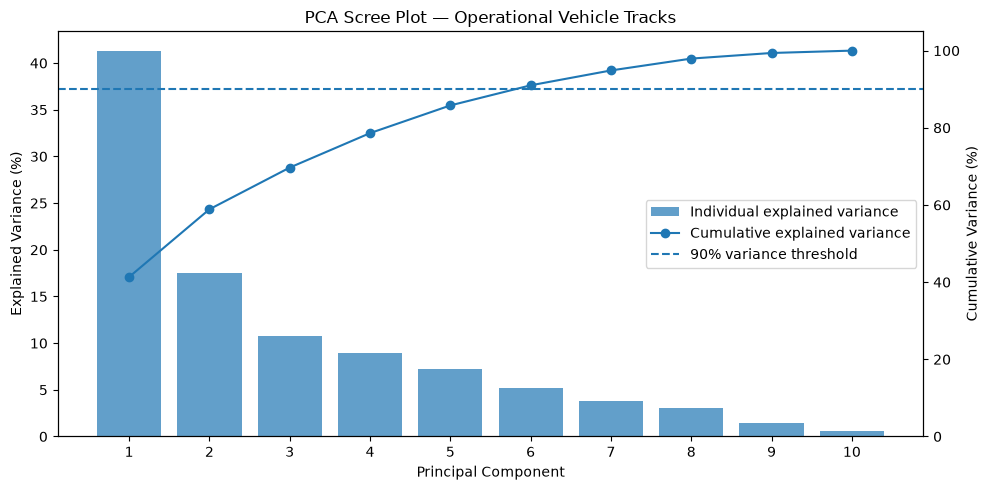

In [141]:
import matplotlib.pyplot as plt
import numpy as np

components = np.arange(1, len(pca.explained_variance_ratio_) + 1)
individual_variance = pca.explained_variance_ratio_ * 100
cumulative_variance = np.cumsum(individual_variance)

fig, ax1 = plt.subplots(figsize=(10, 5))

ax1.bar(
    components,
    individual_variance,
    alpha=0.7,
    label="Individual explained variance"
)
ax1.set_xlabel("Principal Component")
ax1.set_ylabel("Explained Variance (%)")
ax1.set_xticks(components)

ax2 = ax1.twinx()
ax2.plot(
    components,
    cumulative_variance,
    marker="o",
    label="Cumulative explained variance"
)
ax2.axhline(
    90,
    linestyle="--",
    label="90% variance threshold"
)
ax2.set_ylabel("Cumulative Variance (%)")
ax2.set_ylim(0, 105)

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc="center right")

plt.title("PCA Scree Plot — Operational Vehicle Tracks")
plt.tight_layout()
plt.show()

In [142]:
# Step 1: Inventory available PCA representations

candidate_names = [
    "operational",
    "pca_full",
    "X_scaled",
    "X_pca",
    "X_pca_reduced",
    "X_imputed",
    "explained_variance",
    "loadings",
]

print("AVAILABLE PCA VARIABLES")
print("=" * 55)

for name in candidate_names:
    if name in globals():
        obj = globals()[name]
        shape = getattr(obj, "shape", None)
        print(f"{name:25s} available | shape={shape}")
    else:
        print(f"{name:25s} not found") 

AVAILABLE PCA VARIABLES
operational               available | shape=(43125, 63)
pca_full                  available | shape=(43125, 63)
X_scaled                  available | shape=(43105, 10)
X_pca                     available | shape=(43105, 10)
X_pca_reduced             available | shape=(43105, 6)
X_imputed                 available | shape=(43105, 10)
explained_variance        available | shape=(10, 4)
loadings                  available | shape=(10, 10)


In [143]:

import numpy as np
import pandas as pd

print("=" * 65)
print("1. OBJECT TYPES AND SHAPES")
print("=" * 65)

for name in ["operational", "pca_full", "X_imputed",
             "X_scaled", "X_pca", "X_pca_reduced",
             "explained_variance", "loadings"]:
    obj = globals()[name]
    print(f"{name:22s} | type={type(obj).__name__:12s} | shape={obj.shape}")

print("\n" + "=" * 65)
print("2. NUMERICAL VALIDITY")
print("=" * 65)

for name in ["X_imputed", "X_scaled", "X_pca", "X_pca_reduced"]:
    arr = np.asarray(globals()[name], dtype=float)
    print(
        f"{name:22s} | "
        f"NaNs={np.isnan(arr).sum():6d} | "
        f"Infinities={np.isinf(arr).sum():6d}"
    )

print("\n" + "=" * 65)
print("3. EXPLAINED VARIANCE")
print("=" * 65)

print(explained_variance.to_string() if isinstance(
    explained_variance, pd.DataFrame
) else explained_variance)

print("\n" + "=" * 65)
print("4. VARIANCE RETAINED")
print("=" * 65)

ev = np.asarray(X_pca, dtype=float)
if isinstance(explained_variance, pd.DataFrame):
    print("Explained-variance column names:", explained_variance.columns.tolist())
    print("Explained-variance index:", explained_variance.index.tolist())
else:
    print("Explained-variance array preview:", np.asarray(explained_variance)[:3])

# Calculate variance retained directly from the PCA scores.
component_variances = np.var(ev, axis=0, ddof=1)
variance_ratios = component_variances / component_variances.sum()
cumulative_ratios = np.cumsum(variance_ratios)

print("Variance ratios calculated from PCA scores:")
for i, (ratio, cumulative) in enumerate(
    zip(variance_ratios, cumulative_ratios), start=1
):
    print(f"PC{i:02d}: {ratio:.4%} | cumulative: {cumulative:.4%}")

print(f"\nVariance retained by 6 components: {cumulative_ratios[5]:.4%}")
print(f"All 10 components: {cumulative_ratios[-1]:.4%}")
print(f"\nSix-component shape: {np.asarray(X_pca_reduced).shape}")


1. OBJECT TYPES AND SHAPES
operational            | type=DataFrame    | shape=(43125, 63)
pca_full               | type=DataFrame    | shape=(43125, 63)
X_imputed              | type=DataFrame    | shape=(43105, 10)
X_scaled               | type=DataFrame    | shape=(43105, 10)
X_pca                  | type=ndarray      | shape=(43105, 10)
X_pca_reduced          | type=ndarray      | shape=(43105, 6)
explained_variance     | type=DataFrame    | shape=(10, 4)
loadings               | type=DataFrame    | shape=(10, 10)

2. NUMERICAL VALIDITY
X_imputed              | NaNs=     0 | Infinities=     0
X_scaled               | NaNs=     0 | Infinities=     0
X_pca                  | NaNs=     0 | Infinities=     0
X_pca_reduced          | NaNs=     0 | Infinities=     0

3. EXPLAINED VARIANCE
  Principal Component  Eigenvalue  Explained Variance (%)  Cumulative Variance (%)
0                 PC1    4.133418               41.333225                41.333225
1                 PC2    1.754822    

In [144]:

print("=" * 65)
print("1. ROW INDEX ALIGNMENT")
print("=" * 65)

print("operational index unique:", operational.index.is_unique)
print("pca_full index unique:", pca_full.index.is_unique)
print("operational and pca_full indices equal:",
      operational.index.equals(pca_full.index))

print("\nPCA-related DataFrames:")
for name, obj in list(globals().items()):
    if isinstance(obj, pd.DataFrame) and (
        obj.shape[0] == 43105 or obj.shape[1] == 10
    ):
        print(f"{name:30s} shape={obj.shape}")

print("\n" + "=" * 65)
print("2. NUMERICAL VALIDITY")
print("=" * 65)

for name in ["X_imputed", "X_scaled", "X_pca", "X_pca_reduced"]:
    arr = np.asarray(globals()[name], dtype=float)
    print(
        f"{name:22s} | NaNs={np.isnan(arr).sum()} "
        f"| Infinities={np.isinf(arr).sum()}"
    )

print("\n" + "=" * 65)
print("3. PCA FEATURE DEFINITIONS")
print("=" * 65)

print("Loadings index:", loadings.index.tolist())
print("Loadings columns:", loadings.columns.tolist())
print("\nOperational columns:")
print(operational.columns.tolist())


1. ROW INDEX ALIGNMENT
operational index unique: True
pca_full index unique: True
operational and pca_full indices equal: True

PCA-related DataFrames:
X_full_pca                     shape=(43125, 10)
speed_check                    shape=(43125, 10)
X_transformed                  shape=(43125, 10)
X_pca_ready                    shape=(43105, 10)
X_imputed                      shape=(43105, 10)
X_scaled                       shape=(43105, 10)
loadings                       shape=(10, 10)
obj                            shape=(10, 10)
pca_scores_df                  shape=(43105, 10)
pca_scores_6_df                shape=(43105, 6)
pca_metadata                   shape=(43105, 8)
pca_analysis_df                shape=(43105, 18)
pca_analysis_6_df              shape=(43105, 14)
X_pca_10_common                shape=(42867, 10)
X_10_common                    shape=(42867, 10)
pca_common_10_df               shape=(42867, 10)
scores                         shape=(42867, 10)
X_cluster_10_full      

In [145]:

print("=" * 65)
print("1. INDEX TYPES")
print("=" * 65)

for name in ["X_full_pca", "X_transformed", "X_pca_ready",
             "X_imputed", "operational", "pca_full"]:
    obj = globals().get(name)
    if obj is not None:
        print(
            f"{name:20s} | index type={type(obj.index).__name__:12s} "
            f"| rows={len(obj)} | first indexes={list(obj.index[:5])}"
        )

print("\n" + "=" * 65)
print("2. ROWS EXCLUDED FROM PCA")
print("=" * 65)

if isinstance(X_full_pca, pd.DataFrame) and isinstance(X_pca_ready, pd.DataFrame):
    excluded_idx = X_full_pca.index.difference(X_pca_ready.index)
    print("Rows before filtering:", len(X_full_pca))
    print("Rows after filtering: ", len(X_pca_ready))
    print("Excluded row count:   ", len(excluded_idx))
    print("Excluded indexes:     ", excluded_idx.tolist()[:30])

    if len(excluded_idx) > 0:
        print("\nExcluded rows from operational data:")
        cols_to_show = [
            c for c in ["track_id", "vehicle_id", "distance_km",
                        "r_signal_loss", "r_signal_loss_valid"]
            if c in operational.columns
        ]
        print(operational.loc[excluded_idx, cols_to_show].to_string())
else:
    print("At least one PCA input object is not a DataFrame.")
    print("X_full_pca type:", type(X_full_pca))
    print("X_pca_ready type:", type(X_pca_ready))


1. INDEX TYPES
X_full_pca           | index type=Index        | rows=43125 | first indexes=[0, 1, 2, 10, 13]
X_transformed        | index type=Index        | rows=43125 | first indexes=[0, 1, 2, 10, 13]
X_pca_ready          | index type=Index        | rows=43105 | first indexes=[0, 1, 2, 10, 13]
X_imputed            | index type=Index        | rows=43105 | first indexes=[0, 1, 2, 10, 13]
operational          | index type=Index        | rows=43125 | first indexes=[0, 1, 2, 10, 13]
pca_full             | index type=Index        | rows=43125 | first indexes=[0, 1, 2, 10, 13]

2. ROWS EXCLUDED FROM PCA
Rows before filtering: 43125
Rows after filtering:  43105
Excluded row count:    20
Excluded indexes:      [28972, 39102, 49759, 64197, 84264, 87274, 88074, 103288, 103882, 116380, 116381, 117023, 118257, 118258, 129579, 129598, 133221, 138565, 145818, 147683]

Excluded rows from operational data:
        track_id  vehicle_id  distance_km  r_signal_loss  r_signal_loss_valid
28972      28972 

In [146]:

# Confirm that preprocessing preserved row order and indexes.
assert X_pca_ready.index.equals(X_imputed.index), \
    "Index mismatch: X_pca_ready vs X_imputed"

assert len(X_pca) == len(X_pca_ready), \
    "Row mismatch: PCA scores vs PCA input"

assert len(X_pca_reduced) == len(X_pca_ready), \
    "Row mismatch: reduced PCA scores vs PCA input"

assert X_pca_ready.index.is_unique, \
    "PCA input indexes are not unique"

# Attach original row indexes to the PCA scores.
pc_columns = [f"PC{i}" for i in range(1, X_pca.shape[1] + 1)]

pca_scores_df = pd.DataFrame(
    X_pca,
    index=X_pca_ready.index,
    columns=pc_columns
)

pca_scores_6_df = pca_scores_df.iloc[:, :6].copy()

# Retain track identifiers and useful operational metadata.
metadata_columns = [
    c for c in [
        "track_id", "vehicle_id", "distance_km", "duration_minutes",
        "avg_speed_kmh", "max_speed_kmh", "r_signal_loss",
        "r_signal_loss_valid"
    ]
    if c in operational.columns
]

pca_metadata = operational.loc[
    pca_scores_df.index, metadata_columns
].copy()

# Combine metadata and PCA scores using the preserved index.
pca_analysis_df = pca_metadata.join(pca_scores_df)
pca_analysis_6_df = pca_metadata.join(pca_scores_6_df)

print("PCA mapping verified.")
print("10-component dataset:", pca_analysis_df.shape)
print("6-component dataset: ", pca_analysis_6_df.shape)
print("\nFirst five mapped records:")
print(pca_analysis_6_df.head().to_string())

print("\nTrack ID alignment:",
      pca_analysis_df["track_id"].equals(
          operational.loc[pca_analysis_df.index, "track_id"]
      ))


PCA mapping verified.
10-component dataset: (43105, 18)
6-component dataset:  (43105, 14)

First five mapped records:
    track_id  vehicle_id  distance_km  duration_minutes  avg_speed_kmh  max_speed_kmh  r_signal_loss  r_signal_loss_valid       PC1       PC2       PC3       PC4       PC5       PC6
0          0           1       30.751         63.063283         29.268         74.088            0.0                  0.0 -0.253859 -1.421764  0.132911  0.271120  0.014263 -0.263679
1          1           1        7.762         15.975050         29.160         78.444            0.0                  0.0 -1.218106 -0.040360  0.969327  0.863280  0.498850  0.144820
2          2           1       19.432         44.510933         26.208         89.100            0.0                  0.0 -0.179740 -1.588983  0.126564  0.814756  0.126533  0.317060
10        10           1       10.267         12.552000         49.068         70.524            0.0                  0.0 -1.058972 -1.095606  1.071825  0

In [147]:

print("=" * 65)
print("PCA EXPERIMENT INVENTORY")
print("=" * 65)

keywords = [
    "pca", "explained", "variance", "loading",
    "feature", "operational", "telemetry"
]

for name, obj in list(globals().items()):
    if name.startswith("_"):
        continue

    if any(word in name.lower() for word in keywords):
        shape = getattr(obj, "shape", None)

        if shape is not None:
            print(
                f"{name:35s} "
                f"{type(obj).__name__:15s} "
                f"shape={shape}"
            )
        elif isinstance(obj, (list, tuple, dict, set)):
            print(
                f"{name:35s} "
                f"{type(obj).__name__:15s} "
                f"length={len(obj)}"
            )


PCA EXPERIMENT INVENTORY
features                            DataFrame       shape=(151598, 13)
operational                         DataFrame       shape=(43125, 63)
candidate_features                  list            length=15
pca_source                          DataFrame       shape=(43125, 70)
pca_candidates                      list            length=7
pca_audit                           DataFrame       shape=(7, 4)
operational_features                list            length=5
telemetry_features                  list            length=2
all_pca_features                    list            length=7
pca_data                            DataFrame       shape=(42867, 7)
X_operational                       DataFrame       shape=(42867, 5)
X_telemetry                         DataFrame       shape=(42867, 7)
Z_operational                       ndarray         shape=(42867, 5)
Z_telemetry                         ndarray         shape=(42867, 7)
scores_operational                  ndarray     

In [148]:

print("=" * 70)
print("1. FEATURE DEFINITIONS")
print("=" * 70)

print("Operational PCA features:")
print(operational_features)

print("\nTelemetry-aware PCA features:")
print(all_pca_features)

print("\n10-feature PCA features:")
print(selected_features)

print("\n" + "=" * 70)
print("2. EXPLAINED VARIANCE COMPARISON")
print("=" * 70)

print("\nOperational PCA:")
print(variance_operational.to_string(index=False))

print("\nTelemetry-aware PCA:")
print(variance_telemetry.to_string(index=False))

print("\n10-feature PCA:")
print(explained_variance.to_string(index=False))

print("\n" + "=" * 70)
print("3. TRACK INDEX COMPARISON")
print("=" * 70)

print("pca_data index unique:", pca_data.index.is_unique)
print("X_pca_ready index unique:", X_pca_ready.index.is_unique)

print("5-feature and 7-feature PCA share same rows:",
      X_operational.index.equals(X_telemetry.index))

print("7-feature PCA row count:", len(X_telemetry))
print("10-feature PCA row count:", len(X_pca_ready))

common_idx = X_telemetry.index.intersection(X_pca_ready.index)

print("Common row count:", len(common_idx))
print("Common rows equal to 7-feature rows:",
      len(common_idx) == len(X_telemetry))
print("Common rows equal to 10-feature rows:",
      len(common_idx) == len(X_pca_ready))


1. FEATURE DEFINITIONS
Operational PCA features:
['distance_log', 'duration_log', 'raw_speed_mean_kmh', 'max_speed_kmh', 'avg_speed_kmh_for_pca']

Telemetry-aware PCA features:
['distance_log', 'duration_log', 'raw_speed_mean_kmh', 'max_speed_kmh', 'avg_speed_kmh_for_pca', 'd_signal_loss_log', 'r_signal_loss_for_pca']

10-feature PCA features:
['distance_km', 'duration_minutes', 'track_gap', 'raw_speed_mean_kmh', 'raw_speed_std', 'max_speed_kmh', 'd_signal_loss', 'r_signal_loss_valid', 'avg_hdop', 'raw_hdop_max']

2. EXPLAINED VARIANCE COMPARISON

Operational PCA:
component  explained_variance_ratio  explained_variance_percent  cumulative_variance_percent  experiment
      PC1                  0.808866                   80.886580                    80.886580 Operational
      PC2                  0.105022                   10.502238                    91.388818 Operational
      PC3                  0.066341                    6.634090                    98.022908 Operational
      PC4

In [149]:

# Use the 42,867 tracks from the earlier PCA experiments.
common_idx = X_telemetry.index.intersection(pca_scores_df.index)

assert len(common_idx) == 42867
assert X_operational.index.equals(X_telemetry.index)

# Wrap the older score arrays with their original track indexes.
scores_operational_df = pd.DataFrame(
    scores_operational,
    index=X_operational.index,
    columns=[f"PC{i}" for i in range(1, scores_operational.shape[1] + 1)]
)

scores_telemetry_df = pd.DataFrame(
    scores_telemetry,
    index=X_telemetry.index,
    columns=[f"PC{i}" for i in range(1, scores_telemetry.shape[1] + 1)]
)

# Restrict every representation to exactly the same track rows.
X_pca_5_common = scores_operational_df.loc[common_idx].copy()
X_pca_7_common = scores_telemetry_df.loc[common_idx].copy()
X_pca_10_common = pca_scores_df.loc[common_idx].copy()

# Confirm alignment and dimensions.
print("Common tracks:", len(common_idx))
print("5-feature PCA scores:", X_pca_5_common.shape)
print("7-feature PCA scores:", X_pca_7_common.shape)
print("10-feature PCA scores:", X_pca_10_common.shape)

print("\nIndex alignment checks:")
print("5 vs 7:", X_pca_5_common.index.equals(X_pca_7_common.index))
print("7 vs 10:", X_pca_7_common.index.equals(X_pca_10_common.index))

print("\nMissing values:")
for name, df in [
    ("5-feature PCA", X_pca_5_common),
    ("7-feature PCA", X_pca_7_common),
    ("10-feature PCA", X_pca_10_common),
]:
    print(f"{name}: {df.isna().sum().sum()}")


Common tracks: 42867
5-feature PCA scores: (42867, 5)
7-feature PCA scores: (42867, 7)
10-feature PCA scores: (42867, 10)

Index alignment checks:
5 vs 7: True
7 vs 10: True

Missing values:
5-feature PCA: 0
7-feature PCA: 0
10-feature PCA: 0


In [150]:

from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

# 1. Fit the 5-feature PCA on the common tracks.
pca_common_5 = PCA()
scores_common_5 = pca_common_5.fit_transform(Z_operational)

# 2. Fit the 7-feature PCA on the same common tracks.
pca_common_7 = PCA()
scores_common_7 = pca_common_7.fit_transform(Z_telemetry)

# 3. Refit preprocessing and PCA for the 10-feature experiment.
X_10_common = X_pca_ready.loc[common_idx].copy()

imputer_common_10 = SimpleImputer(strategy="median")
X_10_imputed_common = imputer_common_10.fit_transform(X_10_common)

scaler_common_10 = StandardScaler()
X_10_scaled_common = scaler_common_10.fit_transform(
    X_10_imputed_common
)

pca_common_10 = PCA()
scores_common_10 = pca_common_10.fit_transform(
    X_10_scaled_common
)

# Build consistently indexed score DataFrames.
pca_common_5_df = pd.DataFrame(
    scores_common_5,
    index=common_idx,
    columns=[f"PC{i}" for i in range(1, 6)]
)

pca_common_7_df = pd.DataFrame(
    scores_common_7,
    index=common_idx,
    columns=[f"PC{i}" for i in range(1, 8)]
)

pca_common_10_df = pd.DataFrame(
    scores_common_10,
    index=common_idx,
    columns=[f"PC{i}" for i in range(1, 11)]
)

# Report variance retained by each representation.
for name, model, scores in [
    ("5-feature PCA", pca_common_5, pca_common_5_df),
    ("7-feature PCA", pca_common_7, pca_common_7_df),
    ("10-feature PCA", pca_common_10, pca_common_10_df),
]:
    cumulative = np.cumsum(model.explained_variance_ratio_)
    n90 = np.searchsorted(cumulative, 0.90) + 1

    print(f"\n{name}")
    print("-" * 45)
    print("Tracks:", len(scores))
    print("Components:", scores.shape[1])
    print(f"Variance retained by all PCs: {cumulative[-1]:.4%}")
    print(f"Components needed for >=90%: {n90}")
    print(f"Variance at {n90} components: {cumulative[n90 - 1]:.4%}")
    print("All scores finite:", np.isfinite(scores.to_numpy()).all())

print("\nIndex alignment:")
print("5 vs 7:", pca_common_5_df.index.equals(pca_common_7_df.index))
print("7 vs 10:", pca_common_7_df.index.equals(pca_common_10_df.index))



5-feature PCA
---------------------------------------------
Tracks: 42867
Components: 5
Variance retained by all PCs: 100.0000%
Components needed for >=90%: 2
Variance at 2 components: 91.3888%
All scores finite: True

7-feature PCA
---------------------------------------------
Tracks: 42867
Components: 7
Variance retained by all PCs: 100.0000%
Components needed for >=90%: 4
Variance at 4 components: 94.6076%
All scores finite: True

10-feature PCA
---------------------------------------------
Tracks: 42867
Components: 10
Variance retained by all PCs: 100.0000%
Components needed for >=90%: 6
Variance at 6 components: 91.1321%
All scores finite: True

Index alignment:
5 vs 7: True
7 vs 10: True


In [151]:

def show_top_loadings(model, feature_names, n_components, model_name):
    loading_matrix = pd.DataFrame(
        model.components_[:n_components].T,
        index=feature_names,
        columns=[f"PC{i}" for i in range(1, n_components + 1)]
    )

    print(f"\n{model_name}")
    print("-" * 65)

    for pc in loading_matrix.columns:
        top = loading_matrix[pc].abs().sort_values(ascending=False).head(3)
        print(f"\n{pc}:")
        for feature in top.index:
            print(f"  {feature:30s} loading={loading_matrix.loc[feature, pc]:+.4f}")

# Feature order must match the exact matrices used to fit each PCA.
features_5 = list(operational_features)
features_7 = list(all_pca_features)
features_10 = list(X_10_common.columns)

show_top_loadings(
    pca_common_5, features_5, 2, "5-feature Operational PCA"
)

show_top_loadings(
    pca_common_7, features_7, 4, "7-feature Operational + Telemetry PCA"
)

show_top_loadings(
    pca_common_10, features_10, 6, "10-feature Broader Telemetry PCA"
)



5-feature Operational PCA
-----------------------------------------------------------------

PC1:
  distance_log                   loading=+0.4839
  raw_speed_mean_kmh             loading=+0.4672
  avg_speed_kmh_for_pca          loading=+0.4581

PC2:
  duration_log                   loading=+0.8120
  avg_speed_kmh_for_pca          loading=-0.3627
  raw_speed_mean_kmh             loading=-0.3126

7-feature Operational + Telemetry PCA
-----------------------------------------------------------------

PC1:
  distance_log                   loading=+0.4629
  raw_speed_mean_kmh             loading=+0.4430
  avg_speed_kmh_for_pca          loading=+0.4353

PC2:
  r_signal_loss_for_pca          loading=+0.8407
  d_signal_loss_log              loading=+0.4989
  avg_speed_kmh_for_pca          loading=-0.1326

PC3:
  duration_log                   loading=+0.5702
  d_signal_loss_log              loading=+0.4635
  max_speed_kmh                  loading=-0.4369

PC4:
  duration_log                 

In [152]:

# Retain the number of PCs required to explain at least 90% variance.
X_cluster_5 = pca_common_5_df.iloc[:, :2].copy()
X_cluster_7 = pca_common_7_df.iloc[:, :4].copy()
X_cluster_10 = pca_common_10_df.iloc[:, :6].copy()

candidates = {
    "Operational PCA (2 PCs)": X_cluster_5,
    "Operational + telemetry PCA (4 PCs)": X_cluster_7,
    "Broader telemetry PCA (6 PCs)": X_cluster_10,
}

print("CLUSTERING CANDIDATES")
print("=" * 65)

for name, X in candidates.items():
    print(f"\n{name}")
    print("Shape:", X.shape)
    print("Index unique:", X.index.is_unique)
    print("Contains missing values:", X.isna().any().any())
    print("All values finite:", np.isfinite(X.to_numpy()).all())

# Verify that every candidate uses the same tracks.
candidate_indexes = [X.index for X in candidates.values()]

assert all(
    candidate_indexes[0].equals(idx)
    for idx in candidate_indexes[1:]
), "Candidate matrices do not have identical track indexes."

print("\nAll candidates use the same tracks and index order.")


CLUSTERING CANDIDATES

Operational PCA (2 PCs)
Shape: (42867, 2)
Index unique: True
Contains missing values: False
All values finite: True

Operational + telemetry PCA (4 PCs)
Shape: (42867, 4)
Index unique: True
Contains missing values: False
All values finite: True

Broader telemetry PCA (6 PCs)
Shape: (42867, 6)
Index unique: True
Contains missing values: False
All values finite: True

All candidates use the same tracks and index order.


In [153]:

# Reduced representations
X_cluster_5 = pca_common_5_df.iloc[:, :2].copy()
X_cluster_7 = pca_common_7_df.iloc[:, :4].copy()
X_cluster_10 = pca_common_10_df.iloc[:, :6].copy()

# Full representations
X_cluster_5_full = pca_common_5_df.copy()
X_cluster_7_full = pca_common_7_df.copy()
X_cluster_10_full = pca_common_10_df.copy()

candidates = {
    "Operational_2PC": X_cluster_5,
    "Operational_5PC": X_cluster_5_full,
    "Telemetry_4PC": X_cluster_7,
    "Telemetry_7PC": X_cluster_7_full,
    "Broad_6PC": X_cluster_10,
    "Broad_10PC": X_cluster_10_full,
}

print("Candidate | Shape | Finite | Index aligned")
print("-" * 65)

for name, X in candidates.items():
    print(
        f"{name:20s} | {str(X.shape):14s} | "
        f"{np.isfinite(X.to_numpy()).all()} | "
        f"{X.index.equals(common_idx)}"
    )

assert all(
    X.index.equals(common_idx) for X in candidates.values()
), "Candidate row alignment failed."

assert all(
    np.isfinite(X.to_numpy()).all() for X in candidates.values()
), "Non-finite values found."

print("\nAll six candidates are ready.")


Candidate | Shape | Finite | Index aligned
-----------------------------------------------------------------
Operational_2PC      | (42867, 2)     | True | True
Operational_5PC      | (42867, 5)     | True | True
Telemetry_4PC        | (42867, 4)     | True | True
Telemetry_7PC        | (42867, 7)     | True | True
Broad_6PC            | (42867, 6)     | True | True
Broad_10PC           | (42867, 10)    | True | True

All six candidates are ready.


In [154]:
import pandas as pd
import numpy as np

def display_loadings(name, feature_names, loading_matrix):
    loading_df = pd.DataFrame(
        loading_matrix,
        index=feature_names,
        columns=[
            f"PC{i+1}"
            for i in range(loading_matrix.shape[1])
        ]
    )

    print("\n" + "=" * 75)
    print(name)
    print("=" * 75)

    # Sort features by absolute loading on each component
    for pc in loading_df.columns:
        print(f"\n{pc} — strongest feature contributions:")
        print(
            loading_df[pc]
            .sort_values(key=abs, ascending=False)
            .round(4)
            .to_string()
        )

    return loading_df


# 1. Operational PCA: 5 features
loadings_5_df = display_loadings(
    "OPERATIONAL PCA — 5 FEATURES",
    operational_features,
    loadings_operational
)

# 2. Operational + telemetry PCA: 7 features
loadings_7_df = display_loadings(
    "OPERATIONAL + TELEMETRY PCA — 7 FEATURES",
    all_pca_features,
    loadings_telemetry
)

# 3. Broad PCA: 10 features, refitted on the common 42,867 tracks
# Use the fitted PCA estimator from the common-row experiment.
loadings_10_common = pca_common_10.components_.T

loadings_10_df = display_loadings(
    "BROAD PCA — 10 FEATURES (COMMON-ROW REFIT)",
    selected_features,
    loadings_10_common
)


OPERATIONAL PCA — 5 FEATURES

PC1 — strongest feature contributions:
distance_log             0.4839
raw_speed_mean_kmh       0.4672
avg_speed_kmh_for_pca    0.4581
max_speed_kmh            0.4214
duration_log             0.4002

PC2 — strongest feature contributions:
duration_log             0.8120
avg_speed_kmh_for_pca   -0.3627
raw_speed_mean_kmh      -0.3126
max_speed_kmh           -0.2642
distance_log             0.2038

PC3 — strongest feature contributions:
max_speed_kmh            0.8585
avg_speed_kmh_for_pca   -0.4359
raw_speed_mean_kmh      -0.2396
distance_log            -0.1228
duration_log             0.0232

PC4 — strongest feature contributions:
raw_speed_mean_kmh       0.7598
distance_log            -0.4586
avg_speed_kmh_for_pca   -0.4078
duration_log             0.2040
max_speed_kmh           -0.0661

PC5 — strongest feature contributions:
distance_log             0.7064
avg_speed_kmh_for_pca   -0.5497
duration_log            -0.3720
raw_speed_mean_kmh       0.2219
ma

### PCA Loading Interpretation and Validation — 18 October 2026

**Objective:** Interpret the principal components of the operational, operational-plus-telemetry, and broad telemetry feature sets using a common sample of 42,867 tracks.

**Operational PCA (5 features):**
- The first principal component is dominated by distance and speed-related features and represents broad operational variation.
- The second component is primarily associated with duration, contrasting it with speed-related variation.
- Later components retain more specific distinctions involving maximum speed, raw mean speed, and distance versus average speed.
- Two PCs retain 91.39% of the variance.

**Operational + telemetry PCA (7 features):**
- PC1 continues to capture broad operational variation.
- PC2 is dominated by the signal-loss ratio and signal-loss distance, indicating an additional telemetry-related dimension.
- Later components capture mixed duration, signal-loss, and speed-specific patterns.
- Four PCs retain 94.61% of the variance.

**Broad PCA (10 features):**
- PC1 captures broad operational variation.
- PC2 emphasizes GPS/telemetry quality and signal loss.
- PC3–PC7 capture additional contrasts involving track gaps, signal-loss measures, speed variability, and HDOP.
- PC8–PC10 preserve further speed- and distance-related distinctions.
- Six PCs retain 91.13% of the variance on the common sample.

**Conclusions:**
1. The three feature sets capture different combinations of operational and telemetry information.
2. Adding telemetry features introduces distinct dimensions that are not prominent in the operational-only PCA.
3. Reduced PCA representations are compact, but discarded components may still contain useful clustering information.
4. Explained variance alone cannot determine the best clustering representation.
5. Telemetry-quality features may influence clustering and must be considered when interpreting the resulting groups.
6. PCA component interpretations are provisional and do not establish causal relationships or operational cluster labels.

**Next step:** On 19 October, define and document the candidate feature representations and comparison hypotheses before conducting the scheduled clustering baselines.

In [155]:

from pathlib import Path

# Current working directory is notebooks/
PROJECT_ROOT = Path.cwd().parent
OUTPUT_DIR = PROJECT_ROOT / "data" / "processed" / "pca_clustering_inputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

pca_outputs = {
    "Operational_2PC": X_cluster_5,
    "Operational_5PC": X_cluster_5_full,
    "Telemetry_4PC": X_cluster_7,
    "Telemetry_7PC": X_cluster_7_full,
    "Broad_6PC": X_cluster_10,
    "Broad_10PC": X_cluster_10_full,
}

for name, df in pca_outputs.items():
    path = OUTPUT_DIR / f"{name}.parquet"
    df.to_parquet(path, index=True)
    print(f"{name:20} | {df.shape} | Saved: {path.name}")

# Save the shared track index separately.
common_idx_df = pd.DataFrame({"track_index": common_idx})
common_idx_df.to_parquet(
    OUTPUT_DIR / "common_track_index.parquet",
    index=False
)

print("\nTotal files:", len(list(OUTPUT_DIR.glob("*.parquet"))))
print("Output folder:", OUTPUT_DIR)


Operational_2PC      | (42867, 2) | Saved: Operational_2PC.parquet
Operational_5PC      | (42867, 5) | Saved: Operational_5PC.parquet
Telemetry_4PC        | (42867, 4) | Saved: Telemetry_4PC.parquet
Telemetry_7PC        | (42867, 7) | Saved: Telemetry_7PC.parquet
Broad_6PC            | (42867, 6) | Saved: Broad_6PC.parquet
Broad_10PC           | (42867, 10) | Saved: Broad_10PC.parquet

Total files: 10
Output folder: /Users/janibhargesh/Documents/ML-Project/data/processed/pca_clustering_inputs


In [156]:

from pathlib import Path
import pandas as pd
import numpy as np

PROJECT_ROOT = Path.cwd().parent
OUTPUT_DIR = PROJECT_ROOT / "data" / "processed" / "pca_clustering_inputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Original standardized inputs, using the same 42,867 tracks
original_outputs = {
    "Operational_Original": pd.DataFrame(
        Z_operational,
        index=common_idx,
        columns=operational_features
    ),
    "Telemetry_Original": pd.DataFrame(
        Z_telemetry,
        index=common_idx,
        columns=all_pca_features
    ),
    "Broad_Original": pd.DataFrame(
        X_10_scaled_common,
        index=common_idx,
        columns=X_10_common.columns
    ),
}

# Validate and save
for name, df in original_outputs.items():
    assert len(df) == 42867, f"{name}: unexpected row count"
    assert df.index.equals(common_idx), f"{name}: index mismatch"
    assert np.isfinite(df.to_numpy()).all(), f"{name}: non-finite values"

    path = OUTPUT_DIR / f"{name}.parquet"
    df.to_parquet(path, index=True)

    print(f"{name:25} | {df.shape} | Saved: {path.name}")

print("\nOriginal feature matrices saved successfully.")


Operational_Original      | (42867, 5) | Saved: Operational_Original.parquet
Telemetry_Original        | (42867, 7) | Saved: Telemetry_Original.parquet
Broad_Original            | (42867, 10) | Saved: Broad_Original.parquet

Original feature matrices saved successfully.


In [157]:
import pandas as pd

df = pd.read_csv("../data/processed/engineered_tracks.csv")

print("Dataset shape:", df.shape)

print("\nColumns:")
for col in df.columns:
    print(col)

Dataset shape: (151598, 63)

Columns:
track_id
vehicle_id
tour_id
start_time
stop_time
distance
track_gap
avg_speed
max_speed
n_signal_loss
d_signal_loss
r_signal_loss
avg_hdop
home_base
long_haul
rest_area
service_area_fuel
industrial_area
cid
fleet_test_id
gross_vehicle_weight
total_mass_with_trailer
axle_class
raw_observations
telemetry_span_seconds
raw_speed_mean
raw_speed_std
raw_speed_min
raw_speed_max
raw_hdop_mean
raw_hdop_median
raw_hdop_max
missing_speed_count
missing_hdop_count
insufficient_telemetry
start_time_parsed
stop_time_parsed
duration_seconds
duration_invalid
avg_speed_negative
avg_speed_gt_max_speed
raw_speed_missing
n_signal_loss_negative
r_signal_loss_missing
r_signal_loss_out_of_range
distance_missing
zero_distance
zero_distance_speed_issue
track_gap_missing
limited_telemetry
insufficient_core_telemetry
avg_speed_valid
max_speed_valid
n_signal_loss_valid
r_signal_loss_valid
distance_km
avg_speed_kmh
max_speed_kmh
raw_speed_mean_kmh
duration_minutes
avg_speed_imp

In [158]:
candidate_keywords = [
    "speed", "distance", "duration", "accel",
    "decel", "stop", "idle", "variability",
    "std", "percentile", "median", "signal",
    "hdop", "track_id", "vehicle_id"
]

candidate_cols = [
    col for col in df.columns
    if any(keyword in col.lower() for keyword in candidate_keywords)
]

print("Candidate columns:")
print(df[candidate_cols].dtypes)
display(df[candidate_cols].head())

Candidate columns:
track_id                        int64
vehicle_id                      int64
stop_time                         str
distance                      float64
avg_speed                     float64
max_speed                     float64
n_signal_loss                 float64
d_signal_loss                 float64
r_signal_loss                 float64
avg_hdop                      float64
raw_speed_mean                float64
raw_speed_std                 float64
raw_speed_min                 float64
raw_speed_max                 float64
raw_hdop_mean                 float64
raw_hdop_median               float64
raw_hdop_max                  float64
missing_speed_count             int64
missing_hdop_count              int64
stop_time_parsed                  str
duration_seconds              float64
duration_invalid                 bool
avg_speed_negative               bool
avg_speed_gt_max_speed           bool
raw_speed_missing                bool
n_signal_loss_negative         

,track_id,vehicle_id,stop_time,distance,avg_speed,max_speed,n_signal_loss,d_signal_loss,r_signal_loss,avg_hdop,...,n_signal_loss_valid,r_signal_loss_valid,distance_km,avg_speed_kmh,max_speed_kmh,raw_speed_mean_kmh,duration_minutes,avg_speed_implausible,speed_distance_validity,signal_loss_validity
0,0,1,2021-09-10 12:07:57.395000+02:00,30751.0,8.13,20.58,0.0,0.0,0.0,0.612354,...,0.0,0.0,30.751,29.268,74.088,28.834092,63.063283,False,valid,valid
1,1,1,2021-09-10 13:13:53.221000+02:00,7762.0,8.10,21.79,0.0,0.0,0.0,1.230128,...,0.0,0.0,7.762,29.160,78.444,28.411624,15.975050,False,valid,valid
2,2,1,2021-09-10 14:09:50.802000+02:00,19432.0,7.28,24.75,0.0,0.0,0.0,0.549358,...,0.0,0.0,19.432,26.208,89.100,25.709182,44.510933,False,valid,valid
3,3,1,2021-09-10 14:25:26.391000+02:00,56.0,0.24,2.44,0.0,0.0,0.0,0.852446,...,0.0,0.0,0.056,0.864,8.784,0.456291,3.847400,False,valid,valid
4,4,1,2021-09-10 15:45:05.392000+02:00,201.0,0.64,3.80,0.0,0.0,0.0,0.656429,...,0.0,0.0,0.201,2.304,13.680,1.745397,5.274450,False,valid,valid


In [159]:

import pandas as pd
import numpy as np

# Six candidate features for operational-pattern clustering
features = [
    "raw_speed_mean_kmh",
    "raw_speed_std",
    "raw_speed_min",
    "raw_speed_max",
    "distance_km",
    "duration_minutes",
]

# 1. Verify columns exist
missing_columns = [col for col in features if col not in df.columns]
print("Missing columns:", missing_columns)

if missing_columns:
    print("Available columns:")
    print(df.columns.tolist())
else:
    X = df[features].apply(pd.to_numeric, errors="coerce")

    # 2. Missing and invalid values
    print("\n--- Missing values ---")
    print(X.isna().sum())

    print("\n--- Infinite values ---")
    print(pd.Series(
        np.isinf(X).sum(),
        index=X.columns
    ))

    # 3. Descriptive statistics
    print("\n--- Descriptive statistics ---")
    print(X.describe().T.round(3))

    # 4. Skewness: large absolute values indicate asymmetry
    print("\n--- Skewness ---")
    print(X.skew().round(3))

    # 5. Correlations between features
    print("\n--- Pearson correlation ---")
    print(X.corr().round(3))

    print("\n--- Spearman correlation ---")
    print(X.corr(method="spearman").round(3))


Missing columns: []

--- Missing values ---
raw_speed_mean_kmh     9
raw_speed_std         14
raw_speed_min          9
raw_speed_max          9
distance_km           49
duration_minutes       9
dtype: int64

--- Infinite values ---
raw_speed_mean_kmh    0
raw_speed_std         0
raw_speed_min         0
raw_speed_max         0
distance_km           0
duration_minutes      0
dtype: int64

--- Descriptive statistics ---
                       count    mean     std    min    25%    50%     75%  \
raw_speed_mean_kmh  151589.0  12.340  21.368  0.033  0.094  0.529  13.178   
raw_speed_std       151584.0   2.228   3.148  0.000  0.016  0.248   4.129   
raw_speed_min       151589.0   0.028   0.821  0.000  0.000  0.000   0.000   
raw_speed_max       151589.0   7.470   9.808  0.010  0.130  1.440  15.180   
distance_km         151549.0  14.526  42.082  0.000  0.020  0.116   2.058   
duration_minutes    151589.0  22.392  42.244  0.003  1.090  5.916  20.621   

                         max  
raw_spee

In [160]:

import numpy as np
import pandas as pd

features = [
    "raw_speed_mean_kmh",
    "raw_speed_std",
    "raw_speed_min",
    "raw_speed_max",
    "distance_km",
    "duration_minutes",
]

# Operational tracks: distance > 1 km
X_op = df.loc[df["distance_km"] > 1, features].copy()
X_op = X_op.apply(pd.to_numeric, errors="coerce")

print("Operational tracks:", len(X_op))
print("Rows with any missing feature:", X_op.isna().any(axis=1).sum())

print("\n--- Feature distributions: operational tracks ---")
print(
    X_op.describe(percentiles=[0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99])
       .T.round(3)
)

print("\n--- Skewness: operational tracks ---")
print(X_op.skew().round(3))

print("\n--- Pearson correlations: operational tracks ---")
print(X_op.corr().round(3))

print("\n--- Minimum speed distribution ---")
print(X_op["raw_speed_min"].describe().round(3))
print(
    "Fraction with minimum speed = 0:",
    round((X_op["raw_speed_min"] == 0).mean(), 4)
)


Operational tracks: 43125
Rows with any missing feature: 4

--- Feature distributions: operational tracks ---
                      count    mean     std    min     10%     25%     50%  \
raw_speed_mean_kmh  43121.0  38.264  22.756  0.063   7.126  17.870  38.783   
raw_speed_std       43121.0   6.547   2.285  0.011   2.858   5.405   6.918   
raw_speed_min       43121.0   0.017   0.647  0.000   0.000   0.000   0.000   
raw_speed_max       43121.0  21.063   5.976  0.070  11.280  18.830  22.930   
distance_km         43125.0  50.715  66.277  1.001   1.819   5.653  25.803   
duration_minutes    43121.0  62.068  58.804  0.280  11.754  20.415  42.381   

                       75%      90%      95%      99%       max  
raw_speed_mean_kmh  57.245   69.212   74.084   80.235   255.227  
raw_speed_std        8.097    9.225    9.782   10.577    29.227  
raw_speed_min        0.000    0.000    0.000    0.000    59.870  
raw_speed_max       25.300   26.120   26.660   28.470   126.650  
distance_km  

In [161]:

import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler

# Use operational tracks only
base_features = [
    "raw_speed_mean_kmh",
    "raw_speed_std",
    "raw_speed_max",
    "distance_km",
    "duration_minutes",
]

X_base = df.loc[df["distance_km"] > 1, base_features].copy()
X_base = X_base.apply(pd.to_numeric, errors="coerce")

# Exclude only rows missing one of the selected features
X_base = X_base.replace([np.inf, -np.inf], np.nan).dropna()

# Log-transform the positively valued operational-scale features
X_base["distance_km"] = np.log1p(X_base["distance_km"])
X_base["duration_minutes"] = np.log1p(X_base["duration_minutes"])

# Model A: all five selected features
scaler_5 = StandardScaler()
X_scaled_5 = pd.DataFrame(
    scaler_5.fit_transform(X_base),
    columns=X_base.columns,
    index=X_base.index
)

# Model B: omit maximum speed to test redundancy
features_4 = [
    "raw_speed_mean_kmh",
    "raw_speed_std",
    "distance_km",
    "duration_minutes",
]

scaler_4 = StandardScaler()
X_scaled_4 = pd.DataFrame(
    scaler_4.fit_transform(X_base[features_4]),
    columns=features_4,
    index=X_base.index
)

print("Tracks retained:", len(X_base))
print("\nFive-feature matrix:", X_scaled_5.shape)
print("Four-feature matrix:", X_scaled_4.shape)

print("\n--- Correlations after transformations: five-feature model ---")
print(X_base.corr().round(3))

print("\n--- Means after standardization ---")
print(X_scaled_5.mean().round(3))

print("\n--- Standard deviations after standardization ---")
print(X_scaled_5.std(ddof=0).round(3))


Tracks retained: 43121

Five-feature matrix: (43121, 5)
Four-feature matrix: (43121, 4)

--- Correlations after transformations: five-feature model ---
                    raw_speed_mean_kmh  raw_speed_std  raw_speed_max  \
raw_speed_mean_kmh               1.000          0.573          0.768   
raw_speed_std                    0.573          1.000          0.780   
raw_speed_max                    0.768          0.780          1.000   
distance_km                      0.857          0.601          0.749   
duration_minutes                 0.631          0.391          0.576   

                    distance_km  duration_minutes  
raw_speed_mean_kmh        0.857             0.631  
raw_speed_std             0.601             0.391  
raw_speed_max             0.749             0.576  
distance_km               1.000             0.847  
duration_minutes          0.847             1.000  

--- Means after standardization ---
raw_speed_mean_kmh    0.0
raw_speed_std         0.0
raw_speed_max 

In [162]:

from sklearn.decomposition import PCA
import pandas as pd

def inspect_pca(X_scaled, model_name):
    pca = PCA()
    scores = pca.fit_transform(X_scaled)

    variance = pd.DataFrame({
        "PC": [f"PC{i+1}" for i in range(len(pca.explained_variance_ratio_))],
        "explained_variance_ratio": pca.explained_variance_ratio_,
        "cumulative_variance": pca.explained_variance_ratio_.cumsum()
    })

    loadings = pd.DataFrame(
        pca.components_.T,
        index=X_scaled.columns,
        columns=[f"PC{i+1}" for i in range(X_scaled.shape[1])]
    )

    print(f"\n{'=' * 60}")
    print(model_name)
    print("\n--- Explained variance ---")
    print(variance.round(4).to_string(index=False))

    print("\n--- Component loadings ---")
    print(loadings.round(3))

    return pca, scores, variance, loadings


pca_5, scores_5, variance_5, loadings_5 = inspect_pca(
    X_scaled_5, "Model A: Five features"
)

pca_4, scores_4, variance_4, loadings_4 = inspect_pca(
    X_scaled_4, "Model B: Four features"
)



Model A: Five features

--- Explained variance ---
 PC  explained_variance_ratio  cumulative_variance
PC1                    0.7460               0.7460
PC2                    0.1441               0.8902
PC3                    0.0640               0.9541
PC4                    0.0335               0.9877
PC5                    0.0123               1.0000

--- Component loadings ---
                      PC1    PC2    PC3    PC4    PC5
raw_speed_mean_kmh  0.464 -0.079  0.737 -0.232 -0.426
raw_speed_std       0.397  0.668 -0.414 -0.444 -0.165
raw_speed_max       0.465  0.334  0.070  0.807  0.126
distance_km         0.489 -0.280  0.019 -0.289  0.774
duration_minutes    0.414 -0.598 -0.529  0.121 -0.420

Model B: Four features

--- Explained variance ---
 PC  explained_variance_ratio  cumulative_variance
PC1                    0.7447               0.7447
PC2                    0.1596               0.9043
PC3                    0.0797               0.9840
PC4                    0.0160     

In [163]:

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import pandas as pd

representations = {
    "A: 5 features, 2 PCs": scores_5[:, :2],
    "B: 4 features, 2 PCs": scores_4[:, :2],
    "B: 4 features, 3 PCs": scores_4[:, :3],
}

results = []

for representation_name, X_pca in representations.items():
    for k in range(2, 7):
        model = KMeans(
            n_clusters=k,
            random_state=42,
            n_init=10
        )
        labels = model.fit_predict(X_pca)

        results.append({
            "representation": representation_name,
            "k": k,
            "silhouette": silhouette_score(
                X_pca,
                labels,
                sample_size=10000,
                random_state=42
            ),
            "smallest_cluster_pct": (
                pd.Series(labels).value_counts(normalize=True).min() * 100
            ),
            "inertia": model.inertia_
        })

results_df = pd.DataFrame(results)

print(
    results_df.sort_values(
        ["representation", "k"]
    ).round(4).to_string(index=False)
)


      representation  k  silhouette  smallest_cluster_pct    inertia
A: 5 features, 2 PCs  2      0.5275               36.0196 74364.0524
A: 5 features, 2 PCs  3      0.4690               19.5056 42832.0533
A: 5 features, 2 PCs  4      0.4220               17.0636 31322.6791
A: 5 features, 2 PCs  5      0.3817               16.1198 26267.1647
A: 5 features, 2 PCs  6      0.3948               12.3930 22656.9216
B: 4 features, 2 PCs  2      0.5223               39.7973 60031.3348
B: 4 features, 2 PCs  3      0.4408               26.7364 37194.5273
B: 4 features, 2 PCs  4      0.4143               18.5061 26914.8422
B: 4 features, 2 PCs  5      0.3665               16.1940 22692.0383
B: 4 features, 2 PCs  6      0.3678               14.3897 19725.3729
B: 4 features, 3 PCs  2      0.4773               39.8437 73758.9926
B: 4 features, 3 PCs  3      0.3840               27.7545 50580.2219
B: 4 features, 3 PCs  4      0.3432               18.5988 40167.0703
B: 4 features, 3 PCs  5      0.308

In [164]:

from sklearn.cluster import KMeans
import pandas as pd

# Leading candidate: five features, first two PCs, k=2
final_candidate = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=10
)

labels = final_candidate.fit_predict(scores_5[:, :2])

# Preserve original feature values for interpretation
cluster_data = X_base.copy()
cluster_data["cluster"] = labels

profile_features = [
    "raw_speed_mean_kmh",
    "raw_speed_std",
    "raw_speed_max",
    "distance_km",
    "duration_minutes",
]

# Median describes a typical track; mean reveals sensitivity to long tracks
profile = cluster_data.groupby("cluster")[profile_features].agg(
    ["median", "mean"]
)

print("--- Cluster sizes ---")
print(
    cluster_data["cluster"]
    .value_counts()
    .sort_index()
    .rename("tracks")
    .to_frame()
    .assign(
        percentage=lambda x: (
            x["tracks"] / len(cluster_data) * 100
        ).round(2)
    )
)

print("\n--- Cluster profiles in original units ---")
print(profile.round(2).to_string())

print("\n--- Cluster medians relative to each other ---")
print(
    cluster_data.groupby("cluster")[profile_features]
    .median()
    .round(2)
    .to_string()
)


--- Cluster sizes ---
         tracks  percentage
cluster                    
0         15532       36.02
1         27589       63.98

--- Cluster profiles in original units ---
        raw_speed_mean_kmh        raw_speed_std       raw_speed_max        distance_km       duration_minutes      
                    median   mean        median  mean        median   mean      median  mean           median  mean
cluster                                                                                                            
0                    13.32  14.75          4.67  4.46         16.45  15.24        1.55  1.57             2.88  2.92
1                    51.71  51.50          7.71  7.72         24.96  24.34        3.95  3.96             4.20  4.22

--- Cluster medians relative to each other ---
         raw_speed_mean_kmh  raw_speed_std  raw_speed_max  distance_km  duration_minutes
cluster                                                                                 
0               

In [165]:

# Inspect existing features relevant to operational behaviour
keywords = [
    "speed", "distance", "duration", "stop", "accel",
    "decel", "hdop", "signal", "home", "base",
    "haul", "rest", "service", "industrial", "cid",
    "fleet", "vehicle", "track"
]

for col in df.columns:
    if any(word in col.lower() for word in keywords):
        print(f"{col}: {df[col].dtype}")


track_id: int64
vehicle_id: int64
stop_time: str
distance: float64
track_gap: float64
avg_speed: float64
max_speed: float64
n_signal_loss: float64
d_signal_loss: float64
r_signal_loss: float64
avg_hdop: float64
home_base: bool
long_haul: bool
rest_area: bool
service_area_fuel: bool
industrial_area: bool
cid: int64
fleet_test_id: int64
gross_vehicle_weight: float64
raw_speed_mean: float64
raw_speed_std: float64
raw_speed_min: float64
raw_speed_max: float64
raw_hdop_mean: float64
raw_hdop_median: float64
raw_hdop_max: float64
missing_speed_count: int64
missing_hdop_count: int64
stop_time_parsed: str
duration_seconds: float64
duration_invalid: bool
avg_speed_negative: bool
avg_speed_gt_max_speed: bool
raw_speed_missing: bool
n_signal_loss_negative: bool
r_signal_loss_missing: bool
r_signal_loss_out_of_range: bool
distance_missing: bool
zero_distance: bool
zero_distance_speed_issue: bool
track_gap_missing: bool
avg_speed_valid: float64
max_speed_valid: float64
n_signal_loss_valid: float64


In [166]:

context_cols = [
    "home_base",
    "long_haul",
    "rest_area",
    "service_area_fuel",
    "industrial_area",
    "cid",
    "vehicle_id",
    "fleet_test_id",
    "gross_vehicle_weight",
]

print("--- Missing values ---")
print(df[context_cols].isna().sum())

print("\n--- Boolean flag prevalence ---")
flag_cols = [
    "home_base",
    "long_haul",
    "rest_area",
    "service_area_fuel",
    "industrial_area",
]

for col in flag_cols:
    print(f"\n{col}")
    print(df[col].value_counts(dropna=False).to_string())

print("\n--- Identifier cardinality ---")
for col in ["cid", "vehicle_id", "fleet_test_id", "gross_vehicle_weight"]:
    print(f"{col}: {df[col].nunique(dropna=True)} distinct values")


--- Missing values ---
home_base                   0
long_haul                   0
rest_area                   0
service_area_fuel           0
industrial_area             0
cid                         0
vehicle_id                  0
fleet_test_id               0
gross_vehicle_weight    25021
dtype: int64

--- Boolean flag prevalence ---

home_base
home_base
True     76075
False    75523

long_haul
long_haul
False    135159
True      16439

rest_area
rest_area
False    149795
True       1803

service_area_fuel
service_area_fuel
False    149491
True       2107

industrial_area
industrial_area
True     93947
False    57651

--- Identifier cardinality ---
cid: 1308 distinct values
vehicle_id: 163 distinct values
fleet_test_id: 6 distinct values
gross_vehicle_weight: 4 distinct values


In [167]:

# Compare operational context with track distance and duration
operational = df.loc[df["distance_km"] > 1].copy()

context_flags = [
    "home_base",
    "long_haul",
    "rest_area",
    "service_area_fuel",
    "industrial_area",
]

print("Operational subset:", len(operational))

print("\n--- Distance and duration by context flag ---")
for col in context_flags:
    summary = operational.groupby(col).agg(
        tracks=("track_id", "size"),
        median_distance_km=("distance_km", "median"),
        median_duration_min=("duration_minutes", "median"),
        median_mean_speed_kmh=("raw_speed_mean_kmh", "median"),
    )
    print(f"\n{col}")
    print(summary.round(2).to_string())

print("\n--- Long-haul flag versus distance ---")
print(
    pd.crosstab(
        operational["long_haul"],
        operational["distance_km"] >= 100,
        normalize="index"
    ).round(3)
)


Operational subset: 43125

--- Distance and duration by context flag ---

home_base
           tracks  median_distance_km  median_duration_min  median_mean_speed_kmh
home_base                                                                        
False       32796               29.05                45.10                  41.49
True        10329               12.66                35.91                  27.80

long_haul
           tracks  median_distance_km  median_duration_min  median_mean_speed_kmh
long_haul                                                                        
False       37907               21.93                40.08                  36.51
True         5218               85.83                89.56                  59.35

rest_area
           tracks  median_distance_km  median_duration_min  median_mean_speed_kmh
rest_area                                                                        
False       41887               24.17                41.49                

In [168]:

from pathlib import Path
import pandas as pd
import numpy as np

speed_root = Path("../data/raw/speed")

if not speed_root.exists():
    raise FileNotFoundError(
        f"Directory not found: {speed_root.resolve()}\n"
        "Update speed_root to your actual telemetry directory."
    )

files = sorted(speed_root.rglob("*.csv"))

print("CSV files found:", len(files))

inspected = 0

for path in files:
    sample = pd.read_csv(path, nrows=1000)

    if len(sample) < 20:
        continue

    print("\n" + "=" * 60)
    print("File:", path)
    print("Rows inspected:", len(sample))
    print("Columns:", sample.columns.tolist())
    print(sample.head(5).to_string(index=False))

    print("\nData types:")
    print(sample.dtypes)

    # Inspect timestamp and speed columns without assuming names
    for col in sample.columns:
        if any(word in col.lower() for word in ["time", "epoch", "speed", "hdop"]):
            print(f"\n{col} summary:")
            print(sample[col].describe().round(4))

    inspected += 1
    if inspected == 3:
        break

if inspected == 0:
    print("No files with at least 20 readable rows were found.")


CSV files found: 151598

File: ../data/raw/speed/1/0.csv
Rows inspected: 1000
Columns: ['epoch', 'speed', 'hdop']
       epoch  speed  hdop
1.631272e+09   0.03   0.8
1.631272e+09   0.01   0.8
1.631272e+09   0.03   0.8
1.631272e+09   0.02   0.8
1.631272e+09   0.03   0.8

Data types:
epoch    float64
speed    float64
hdop     float64
dtype: object

epoch summary:
count    1.000000e+03
mean     1.631272e+09
std      2.943780e+01
min      1.631272e+09
25%      1.631272e+09
50%      1.631272e+09
75%      1.631272e+09
max      1.631272e+09
Name: epoch, dtype: float64

speed summary:
count    1000.0000
mean        0.4981
std         0.9838
min         0.0000
25%         0.0200
50%         0.0300
75%         0.0900
max         3.5100
Name: speed, dtype: float64

hdop summary:
count    1000.0000
mean        0.6899
std         0.0487
min         0.6000
25%         0.7000
50%         0.7000
75%         0.7000
max         0.8000
Name: hdop, dtype: float64

File: ../data/raw/speed/1/1.csv
Rows insp

In [169]:

from pathlib import Path
import pandas as pd
import numpy as np

# Update this path to your local raw telemetry directory
SPEED_ROOT = Path("../data/raw/speed")

# Find a track with enough observations for behavioural analysis
features = pd.read_csv("../data/interim/speed_features.csv")

candidates = features[
    (features["raw_observations"] >= 20)
    & (features["telemetry_span_seconds"] > 1)
].sort_values("raw_observations", ascending=False)

print("Candidate tracks:", len(candidates))
print(candidates[
    ["track_id", "vehicle_id", "raw_observations",
     "telemetry_span_seconds", "raw_speed_mean",
     "raw_speed_std", "raw_speed_max"]
].head(10))


Candidate tracks: 151441
        track_id  vehicle_id  raw_observations  telemetry_span_seconds  \
15143      74784          35            558104               61784.024   
14685      74708          35            399057               44175.195   
89525     132457          91            373046               37683.532   
15371      74805          35            330616               36428.037   
14761      74087          35            268223               30027.745   
89483     132493          91            220704               22293.407   
126483    145385         141            213757               21592.239   
15579      73364          35            213111               21987.708   
123380     52563          24            211840               21713.982   
51073      63263          28            211593               21785.657   

        raw_speed_mean  raw_speed_std  raw_speed_max  
15143         2.508679       5.663389          21.28  
14685         0.876027       3.456079          19.

In [170]:

from pathlib import Path
import pandas as pd

SPEED_ROOT = Path("../data/raw/speed")

track_id = 74784
vehicle_id = 35

# Locate the CSV without assuming its filename extension or exact naming
vehicle_dir = SPEED_ROOT / str(vehicle_id)

matches = list(vehicle_dir.glob(f"{track_id}.csv"))

if not matches:
    matches = [
        p for p in vehicle_dir.rglob("*.csv")
        if p.stem == str(track_id)
    ]

if len(matches) != 1:
    print("Number of matching files:", len(matches))
    print("Examples:", matches[:10])
else:
    telemetry_path = matches[0]
    print("File:", telemetry_path)

    # Read only a small sample first
    sample = pd.read_csv(telemetry_path, nrows=10)
    print("\nColumns:", sample.columns.tolist())
    display(sample)


File: ../data/raw/speed/35/74784.csv

Columns: ['epoch', 'speed', 'hdop']


,epoch,speed,hdop
0,1.646690e+09,0.01,1.2
1,1.646690e+09,0.02,1.2
2,1.646690e+09,0.01,1.2
3,1.646690e+09,0.01,1.2
4,1.646690e+09,0.03,1.2
5,1.646690e+09,0.03,1.2
6,1.646690e+09,0.03,1.2
7,1.646690e+09,0.01,1.2
8,1.646690e+09,0.03,1.2
9,1.646690e+09,0.05,1.2


In [171]:

import pandas as pd
import numpy as np

telemetry = pd.read_csv(telemetry_path)

# Sort observations chronologically
telemetry = telemetry.sort_values("epoch").reset_index(drop=True)

# Remove rows without usable timestamp or speed for this analysis
telemetry = telemetry.dropna(subset=["epoch", "speed"]).copy()

# Time between consecutive observations, in seconds
telemetry["dt_seconds"] = telemetry["epoch"].diff()

# Retain positive intervals for interval diagnostics
valid_dt = telemetry.loc[
    telemetry["dt_seconds"].gt(0), "dt_seconds"
]

print("Observations:", len(telemetry))
print("\nTime interval summary (seconds):")
print(valid_dt.describe(percentiles=[0.5, 0.9, 0.95, 0.99]))

print("\nSpeed summary (m/s):")
print(telemetry["speed"].describe(
    percentiles=[0.1, 0.25, 0.5, 0.75, 0.9, 0.95, 0.99]
))

print("\nShare of observations below candidate thresholds:")
for threshold in [0.3, 0.5, 1.0, 2.0]:
    share = telemetry["speed"].lt(threshold).mean()
    print(f"Below {threshold:.1f} m/s: {share:.1%}")

print("\nTime intervals:")
print("Non-positive intervals:", (telemetry["dt_seconds"] <= 0).sum())
print("Intervals over 2 seconds:", (telemetry["dt_seconds"] > 2).sum())


Observations: 558104

Time interval summary (seconds):
count    558103.000000
mean          0.110704
std           0.593883
min           0.018000
50%           0.102000
90%           0.102000
95%           0.102000
99%           0.103000
max         190.008000
Name: dt_seconds, dtype: float64

Speed summary (m/s):
count    558104.000000
mean          2.508679
std           5.663389
min           0.000000
10%           0.010000
25%           0.020000
50%           0.030000
75%           0.080000
90%          14.450000
95%          17.880000
99%          19.020000
max          21.280000
Name: speed, dtype: float64

Share of observations below candidate thresholds:
Below 0.3 m/s: 80.1%
Below 0.5 m/s: 80.5%
Below 1.0 m/s: 81.0%
Below 2.0 m/s: 81.8%

Time intervals:
Non-positive intervals: 0
Intervals over 2 seconds: 163


In [172]:

# Time from each observation to the next observation
telemetry["next_epoch"] = telemetry["epoch"].shift(-1)
telemetry["interval_seconds"] = (
    telemetry["next_epoch"] - telemetry["epoch"]
)

# Exclude invalid intervals and gaps longer than 2 seconds.
# We do not assume the vehicle's state during those gaps.
MAX_GAP_SECONDS = 2.0

valid_interval = telemetry["interval_seconds"].between(
    0, MAX_GAP_SECONDS, inclusive="right"
)

print("Total telemetry time:", 
      round(telemetry["interval_seconds"].sum(skipna=True), 2), "seconds")
print("Time covered by valid intervals:",
      round(telemetry.loc[valid_interval, "interval_seconds"].sum(), 2),
      "seconds")
print("Excluded interval time:",
      round(telemetry.loc[~valid_interval, "interval_seconds"].sum(skipna=True), 2),
      "seconds")

# Time-weighted proportion below each candidate threshold
for threshold in [0.3, 0.5, 1.0]:
    low = telemetry["speed"] < threshold
    covered_time = telemetry.loc[valid_interval, "interval_seconds"].sum()
    low_speed_time = telemetry.loc[
        valid_interval & low, "interval_seconds"
    ].sum()

    print(
        f"Below {threshold:.1f} m/s: "
        f"{low_speed_time / covered_time:.1%} of covered time"
    )

# Candidate sustained-stop episodes at 0.3 m/s.
# A long or invalid interval breaks an episode.
telemetry["low_valid_interval"] = (
    valid_interval & (telemetry["speed"] < 0.3)
)

# Each non-low/invalid interval starts a new group,
# preventing episodes from crossing long telemetry gaps.
telemetry["episode_group"] = (
    ~telemetry["low_valid_interval"]
).cumsum()

episodes = (
    telemetry.loc[telemetry["low_valid_interval"]]
    .groupby("episode_group")
    .agg(
        duration_seconds=("interval_seconds", "sum"),
        observations=("speed", "size")
    )
)

sustained_stops = episodes[
    episodes["duration_seconds"] >= 30
]

print("\nCandidate episodes below 0.3 m/s:")
print("All episodes:", len(episodes))
print("Episodes lasting at least 30 seconds:", len(sustained_stops))

if len(sustained_stops):
    print("\nSustained episode duration (seconds):")
    print(sustained_stops["duration_seconds"].describe())

    print("\nLongest candidate episodes:")
    print(
        sustained_stops.sort_values(
            "duration_seconds", ascending=False
        ).head(10)
    )


Total telemetry time: 61784.02 seconds
Time covered by valid intervals: 56885.37 seconds
Excluded interval time: 4898.66 seconds
Below 0.3 m/s: 80.1% of covered time
Below 0.5 m/s: 80.5% of covered time
Below 1.0 m/s: 81.0% of covered time

Candidate episodes below 0.3 m/s:
All episodes: 523
Episodes lasting at least 30 seconds: 175

Sustained episode duration (seconds):
count    175.000000
mean     254.947537
std      122.867495
min       31.698000
25%      128.946500
50%      349.371000
75%      349.414000
max      356.055000
Name: duration_seconds, dtype: float64

Longest candidate episodes:
               duration_seconds  observations
episode_group                                
100465                  356.055          3493
56                      355.918          3492
47                      355.918          3492
71                      355.913          3492
24                      355.901          3492
12660                   355.899          3492
25                      355.87

In [173]:

print("All candidate episode durations (seconds):")
print(
    episodes["duration_seconds"].describe(
        percentiles=[0.1, 0.25, 0.5, 0.75, 0.9, 0.95, 0.99]
    )
)

print("\nEpisode duration frequencies rounded to seconds:")
print(
    episodes["duration_seconds"]
    .round()
    .value_counts()
    .head(15)
)

print("\nLongest excluded telemetry gaps (seconds):")
print(
    telemetry.loc[
        telemetry["interval_seconds"] > MAX_GAP_SECONDS,
        "interval_seconds"
    ]
    .nlargest(10)
    .to_list()
)


All candidate episode durations (seconds):
count    523.000000
mean      87.096128
std      138.740412
min        0.101000
10%        0.102000
25%        0.204000
50%        2.037000
75%      128.946500
90%      349.405000
95%      349.475500
99%      355.893280
max      356.055000
Name: duration_seconds, dtype: float64

Episode duration frequencies rounded to seconds:
duration_seconds
0.0      187
349.0     77
1.0       52
2.0       35
3.0       17
350.0     11
356.0      8
5.0        8
4.0        6
6.0        5
351.0      3
12.0       3
23.0       3
7.0        3
38.0       3
Name: count, dtype: int64

Longest excluded telemetry gaps (seconds):
[190.00800013542175, 181.38100004196167, 44.00399994850159, 40.0310001373291, 37.668999910354614, 36.51900005340576, 36.24499988555908, 36.16100001335144, 36.151000022888184, 35.86800003051758]


In [174]:

# Inspect the episode with the longest duration
longest_group = sustained_stops["duration_seconds"].idxmax()

episode_rows = telemetry[
    (telemetry["episode_group"] == longest_group)
    & telemetry["low_valid_interval"]
].copy()

print("Episode group:", longest_group)
print("Episode duration:", episode_rows["interval_seconds"].sum(), "seconds")
print("Rows:", len(episode_rows))

print("\nSpeed summary (m/s):")
print(episode_rows["speed"].describe())

print("\nFirst 10 observations:")
display(
    episode_rows[["epoch", "speed", "hdop", "interval_seconds"]].head(10)
)

print("\nLast 10 observations:")
display(
    episode_rows[["epoch", "speed", "hdop", "interval_seconds"]].tail(10)
)


Episode group: 100465
Episode duration: 356.0549998283386 seconds
Rows: 3493

Speed summary (m/s):
count    3493.000000
mean        0.043066
std         0.025807
min         0.000000
25%         0.020000
50%         0.040000
75%         0.060000
max         0.170000
Name: speed, dtype: float64

First 10 observations:


,epoch,speed,hdop,interval_seconds
534081,1.646749e+09,0.02,1.4,0.102
534082,1.646749e+09,0.02,1.4,0.102
534083,1.646749e+09,0.04,1.4,0.102
534084,1.646749e+09,0.04,1.4,0.102
534085,1.646749e+09,0.04,1.4,0.102
534086,1.646749e+09,0.05,1.4,0.102
534087,1.646749e+09,0.02,1.4,0.102
534088,1.646749e+09,0.04,1.4,0.102
534089,1.646749e+09,0.03,1.4,0.102
534090,1.646749e+09,0.03,1.4,0.102



Last 10 observations:


,epoch,speed,hdop,interval_seconds
537564,1.646749e+09,0.05,1.4,0.102
537565,1.646749e+09,0.05,1.4,0.102
537566,1.646749e+09,0.08,1.4,0.102
537567,1.646749e+09,0.06,1.4,0.102
537568,1.646749e+09,0.08,1.4,0.102
537569,1.646749e+09,0.05,1.4,0.102
537570,1.646749e+09,0.01,1.4,0.102
537571,1.646749e+09,0.03,1.4,0.102
537572,1.646749e+09,0.02,1.4,0.102
537573,1.646749e+09,0.04,1.4,0.102


In [175]:

import numpy as np
import pandas as pd


def extract_telemetry_features(
    csv_path,
    thresholds=(0.3, 0.5, 1.0),
    max_gap_seconds=2.0,
    min_stop_seconds=30.0,
    min_observations=20,
):
    """
    Extract time-weighted low-speed and sustained-stop features
    from one DT-CARGO telemetry CSV.

    Assumptions:
    - epoch is Unix time in seconds
    - speed is in m/s
    - an interval is assigned the speed at its starting observation
    - intervals longer than max_gap_seconds are excluded
    - a sustained stop is a continuous low-speed run lasting
      at least min_stop_seconds
    """

    empty_result = {
        "observation_count": 0,
        "valid_telemetry_time_seconds": np.nan,
        "excluded_gap_count": np.nan,
        "low_speed_time_pct_03": np.nan,
        "low_speed_time_pct_05": np.nan,
        "low_speed_time_pct_10": np.nan,
        "stop_episode_count_03": np.nan,
        "stop_time_pct_03": np.nan,
        "longest_stop_seconds_03": np.nan,
        "telemetry_sufficient": False,
    }

    df = pd.read_csv(csv_path, usecols=["epoch", "speed", "hdop"])

    df["epoch"] = pd.to_numeric(df["epoch"], errors="coerce")
    df["speed"] = pd.to_numeric(df["speed"], errors="coerce")

    # A row without a usable timestamp or speed cannot contribute
    # to speed-based features.
    df = df.dropna(subset=["epoch", "speed"])
    df = df.sort_values("epoch").reset_index(drop=True)

    # Duplicate timestamps cannot represent positive elapsed time.
    df = df.drop_duplicates(subset="epoch", keep="first").reset_index(drop=True)

    result = empty_result.copy()
    result["observation_count"] = len(df)

    if len(df) < min_observations:
        return result

    # Each speed observation represents the interval until the next one.
    dt = df["epoch"].shift(-1) - df["epoch"]
    speed = df["speed"]

    valid = dt.gt(0) & dt.le(max_gap_seconds) & speed.ge(0)
    covered_time = float(dt[valid].sum())

    result["valid_telemetry_time_seconds"] = covered_time
    result["excluded_gap_count"] = int((~valid.iloc[:-1]).sum())

    if covered_time <= 0:
        return result

    result["telemetry_sufficient"] = True

    # Time-weighted proportions for each threshold.
    for threshold in thresholds:
        low_time = float(dt[valid & speed.lt(threshold)].sum())
        pct = 100 * low_time / covered_time
        key = f"low_speed_time_pct_{int(threshold * 10):02d}"
        result[key] = pct

    # Identify continuous low-speed runs, breaking at invalid gaps.
    
    # Identify continuous low-speed runs.
    # Invalid intervals always break a run, including long telemetry gaps.
    low = (valid & speed.lt(0.3)).to_numpy()
    interval_seconds = dt.to_numpy()

    episodes = []
    current_duration = 0.0

    for i in range(len(df) - 1):
        if low[i]:
            current_duration += interval_seconds[i]
        else:
            if current_duration >= min_stop_seconds:
                episodes.append(current_duration)
            current_duration = 0.0

    # Handle a run that reaches the final interval.
    if current_duration >= min_stop_seconds:
        episodes.append(current_duration)

    result["stop_episode_count_03"] = len(episodes)
    result["stop_time_pct_03"] = (
        100 * sum(episodes) / covered_time
    )
    result["longest_stop_seconds_03"] = (
        max(episodes) if episodes else 0.0
    )

    return result


In [176]:

result = extract_telemetry_features(telemetry_path)

pd.Series(result).to_frame("value")


,value
observation_count,558104
valid_telemetry_time_seconds,56885.367
excluded_gap_count,163
low_speed_time_pct_03,80.075558
low_speed_time_pct_05,80.453817
low_speed_time_pct_10,80.950528
stop_episode_count_03,175
stop_time_pct_03,78.4311
longest_stop_seconds_03,356.055
telemetry_sufficient,True


In [177]:

# Select four tracks with different telemetry characteristics.
# These are inspection examples, not filtering rules.

sample_tracks = (
    candidates.sort_values("raw_observations")
    .iloc[[0, len(candidates) // 3, 2 * len(candidates) // 3, -1]]
    [["track_id", "vehicle_id", "raw_observations"]]
    .drop_duplicates()
)

def find_telemetry_file(vehicle_id, track_id):
    vehicle_dir = SPEED_ROOT / str(int(vehicle_id))
    direct = vehicle_dir / f"{int(track_id)}.csv"

    if direct.exists():
        return direct

    matches = list(vehicle_dir.rglob(f"{int(track_id)}.csv"))
    return matches[0] if len(matches) == 1 else None

validation_results = []

for row in sample_tracks.itertuples(index=False):
    path = find_telemetry_file(row.vehicle_id, row.track_id)

    if path is None:
        print(f"File not found: vehicle={row.vehicle_id}, track={row.track_id}")
        continue

    result = extract_telemetry_features(path)
    result["track_id"] = row.track_id
    result["vehicle_id"] = row.vehicle_id
    validation_results.append(result)

validation_df = pd.DataFrame(validation_results)

display(
    validation_df[
        [
            "track_id", "vehicle_id", "observation_count",
            "valid_telemetry_time_seconds", "excluded_gap_count",
            "low_speed_time_pct_03", "stop_episode_count_03",
            "stop_time_pct_03", "longest_stop_seconds_03",
            "telemetry_sufficient"
        ]
    ]
)


,track_id,vehicle_id,observation_count,valid_telemetry_time_seconds,excluded_gap_count,low_speed_time_pct_03,stop_episode_count_03,stop_time_pct_03,longest_stop_seconds_03,telemetry_sufficient
0,86323,44,20,2.358,0,100.000000,0,0.000000,0.000,True
1,69020,31,1426,145.218,0,100.000000,1,100.000000,145.218,True
2,71937,33,7358,1907.508,0,56.049568,5,53.192542,604.788,True
3,74784,35,558104,56885.367,163,80.075558,175,78.431100,356.055,True


In [182]:

import numpy as np
import pandas as pd


def extract_telemetry_features(
    csv_path,
    thresholds=(0.3, 0.5, 1.0),
    max_gap_seconds=2.0,
    min_stop_seconds=30.0,
    min_observations=20,
):
    """
    Extract behavioural features from one DT-CARGO telemetry CSV.

    Expected columns:
        epoch: Unix timestamp in seconds
        speed: vehicle speed in m/s
        hdop: GPS positioning-quality indicator

    Method:
        - Sort observations chronologically.
        - Remove unusable timestamps/speeds and duplicate timestamps.
        - Calculate intervals between consecutive observations.
        - Exclude intervals <= 0 or > max_gap_seconds.
        - Calculate time-weighted low-speed percentages.
        - Count continuous low-speed episodes lasting at least
          min_stop_seconds, breaking episodes at invalid intervals.
        - Return telemetry coverage metadata.

    Coverage thresholds are descriptive indicators, not automatic
    track-deletion rules.
    """

    result = {
        "observation_count": 0,
        "valid_interval_count": 0,
        "valid_telemetry_time_seconds": np.nan,
        "excluded_gap_count": np.nan,
        "low_speed_time_pct_03": np.nan,
        "low_speed_time_pct_05": np.nan,
        "low_speed_time_pct_10": np.nan,
        "stop_episode_count_03": np.nan,
        "stop_time_pct_03": np.nan,
        "longest_stop_seconds_03": np.nan,
        "coverage_under_30_seconds": True,
        "coverage_under_120_seconds": True,
        "telemetry_sufficient": False,
    }

    # 1. Load only the columns needed for this analysis.
    df = pd.read_csv(
        csv_path,
        usecols=["epoch", "speed", "hdop"]
    )

    # 2. Ensure timestamp and speed are numeric.
    df["epoch"] = pd.to_numeric(df["epoch"], errors="coerce")
    df["speed"] = pd.to_numeric(df["speed"], errors="coerce")

    # Keep observations with usable timestamps and speeds.
    df = df.dropna(subset=["epoch", "speed"])

    # Negative speed values are not valid for this analysis.
    df = df[df["speed"] >= 0]

    # 3. Sort and remove duplicate timestamps.
    df = (
        df.sort_values("epoch")
          .drop_duplicates(subset="epoch", keep="first")
          .reset_index(drop=True)
    )

    result["observation_count"] = len(df)

    # At least two observations are required to form an interval.
    if len(df) < min_observations:
        return result

    # 4. Calculate time between each observation and the next.
    epoch = df["epoch"].to_numpy(dtype=float)
    speed = df["speed"].to_numpy(dtype=float)

    dt = np.diff(epoch)

    # Each dt[i] represents the interval after observation i.
    valid = (dt > 0) & (dt <= max_gap_seconds)

    valid_time = float(dt[valid].sum())
    valid_count = int(valid.sum())

    result["valid_interval_count"] = valid_count
    result["valid_telemetry_time_seconds"] = valid_time
    result["excluded_gap_count"] = int((~valid).sum())

    # Coverage indicators are informative, not filtering rules.
    result["coverage_under_30_seconds"] = valid_time < 30
    result["coverage_under_120_seconds"] = valid_time < 120

    if valid_count == 0 or valid_time <= 0:
        return result

    result["telemetry_sufficient"] = True

    # 5. Time-weighted low-speed proportions.
    thresholds = tuple(thresholds)

    for threshold in thresholds:
        low_speed_time = float(
            dt[valid & (speed[:-1] < threshold)].sum()
        )

        percentage = 100 * low_speed_time / valid_time

        # Example: 0.3 -> low_speed_time_pct_03
        key = f"low_speed_time_pct_{int(round(threshold * 10)):02d}"
        result[key] = percentage

    # 6. Identify continuous low-speed episodes.
    # An invalid interval always breaks the current episode.
    low_interval = valid & (speed[:-1] < 0.3)

    episodes = []
    current_duration = 0.0

    for i in range(len(dt)):
        if low_interval[i]:
            current_duration += dt[i]
        else:
            if current_duration >= min_stop_seconds:
                episodes.append(current_duration)

            current_duration = 0.0

    # Include a qualifying episode that reaches the end of the data.
    if current_duration >= min_stop_seconds:
        episodes.append(current_duration)

    # 7. Summarise sustained episodes.
    result["stop_episode_count_03"] = len(episodes)

    result["stop_time_pct_03"] = (
        100 * sum(episodes) / valid_time
    )

    result["longest_stop_seconds_03"] = (
        max(episodes) if episodes else 0.0
    )

    return result


In [185]:

# Basic consistency checks on the validation sample

assert validation_df["track_id"].is_unique

# All computed percentages must be within 0–100.
for col in [
    "low_speed_time_pct_03",
    "low_speed_time_pct_05",
    "low_speed_time_pct_10",
    "stop_time_pct_03",
]:
    values = validation_df[col].dropna()
    assert values.between(0, 100).all(), f"Invalid values in {col}"

# Sustained-stop time must be a subset of low-speed time.
valid_rows = validation_df.dropna(
    subset=["stop_time_pct_03", "low_speed_time_pct_03"]
)

assert (
    valid_rows["stop_time_pct_03"]
    <= valid_rows["low_speed_time_pct_03"] + 1e-9
).all()

# A track with less than 30 seconds of coverage cannot have
# a qualifying 30-second stop episode.
short_coverage = validation_df["coverage_under_30_seconds"]

assert (
    validation_df.loc[short_coverage, "stop_episode_count_03"]
    .fillna(0)
    .eq(0)
    .all()
)

print("Validation checks passed.")


Validation checks passed.


In [184]:

validation_results = []

for row in sample_tracks.itertuples(index=False):
    path = find_telemetry_file(row.vehicle_id, row.track_id)

    if path is None:
        print(f"File not found: track={row.track_id}")
        continue

    result = extract_telemetry_features(path)

    result["track_id"] = row.track_id
    result["vehicle_id"] = row.vehicle_id
    validation_results.append(result)

validation_df = pd.DataFrame(validation_results)

print(validation_df.columns.tolist())
display(validation_df.head())


['observation_count', 'valid_interval_count', 'valid_telemetry_time_seconds', 'excluded_gap_count', 'low_speed_time_pct_03', 'low_speed_time_pct_05', 'low_speed_time_pct_10', 'stop_episode_count_03', 'stop_time_pct_03', 'longest_stop_seconds_03', 'coverage_under_30_seconds', 'coverage_under_120_seconds', 'telemetry_sufficient', 'track_id', 'vehicle_id']


,observation_count,valid_interval_count,valid_telemetry_time_seconds,excluded_gap_count,low_speed_time_pct_03,low_speed_time_pct_05,low_speed_time_pct_10,stop_episode_count_03,stop_time_pct_03,longest_stop_seconds_03,coverage_under_30_seconds,coverage_under_120_seconds,telemetry_sufficient,track_id,vehicle_id
0,20,19,2.358,0,100.000000,100.000000,100.000000,0,0.000000,0.000,True,True,True,86323,44
1,1426,1425,145.218,0,100.000000,100.000000,100.000000,1,100.000000,145.218,False,False,True,69020,31
2,7358,7357,1907.508,0,56.049568,56.452031,57.836035,5,53.192542,604.788,False,False,True,71937,33
3,558104,557940,56885.367,163,80.075558,80.453817,80.950528,175,78.431100,356.055,False,False,True,74784,35


In [186]:

from pathlib import Path
import pandas as pd
import numpy as np

# Adjust these paths to match your project structure.
SPEED_ROOT = Path("../data/raw/speed")
FEATURES_PATH = Path("../data/interim/speed_features.csv")
OUTPUT_PATH = Path("../data/interim/behavioral_features.csv")
ERROR_PATH = Path("../data/interim/behavioral_feature_errors.csv")

features = pd.read_csv(FEATURES_PATH)

required_columns = {"track_id", "vehicle_id"}
missing_columns = required_columns - set(features.columns)

if missing_columns:
    raise ValueError(f"Missing columns in speed_features.csv: {missing_columns}")

# Avoid processing duplicate track/vehicle pairs.
track_list = (
    features[["track_id", "vehicle_id"]]
    .drop_duplicates()
    .reset_index(drop=True)
)

results = []
errors = []

for i, row in enumerate(track_list.itertuples(index=False), start=1):
    track_id = int(row.track_id)
    vehicle_id = int(row.vehicle_id)

    path = find_telemetry_file(vehicle_id, track_id)

    if path is None:
        errors.append({
            "track_id": track_id,
            "vehicle_id": vehicle_id,
            "error": "Telemetry file not found or ambiguous",
        })
        continue

    try:
        result = extract_telemetry_features(path)
        result["track_id"] = track_id
        result["vehicle_id"] = vehicle_id
        results.append(result)

    except Exception as exc:
        errors.append({
            "track_id": track_id,
            "vehicle_id": vehicle_id,
            "error": repr(exc),
        })

    if i % 5000 == 0:
        print(f"Processed {i:,} / {len(track_list):,} tracks")

behavioral_df = pd.DataFrame(results)
errors_df = pd.DataFrame(
    errors,
    columns=["track_id", "vehicle_id", "error"]
)

OUTPUT_PATH.parent.mkdir(parents=True, exist_ok=True)

behavioral_df.to_csv(OUTPUT_PATH, index=False)
errors_df.to_csv(ERROR_PATH, index=False)

print("\nProcessing complete.")
print("Tracks in input:", len(track_list))
print("Tracks processed:", len(behavioral_df))
print("Errors:", len(errors_df))
print("Feature output:", OUTPUT_PATH)
print("Error log:", ERROR_PATH)


Processed 5,000 / 151,598 tracks
Processed 10,000 / 151,598 tracks
Processed 15,000 / 151,598 tracks
Processed 20,000 / 151,598 tracks
Processed 25,000 / 151,598 tracks
Processed 30,000 / 151,598 tracks
Processed 35,000 / 151,598 tracks
Processed 40,000 / 151,598 tracks
Processed 45,000 / 151,598 tracks
Processed 50,000 / 151,598 tracks
Processed 55,000 / 151,598 tracks
Processed 60,000 / 151,598 tracks
Processed 65,000 / 151,598 tracks
Processed 70,000 / 151,598 tracks
Processed 75,000 / 151,598 tracks
Processed 80,000 / 151,598 tracks
Processed 85,000 / 151,598 tracks
Processed 90,000 / 151,598 tracks
Processed 95,000 / 151,598 tracks
Processed 100,000 / 151,598 tracks
Processed 105,000 / 151,598 tracks
Processed 110,000 / 151,598 tracks
Processed 115,000 / 151,598 tracks
Processed 120,000 / 151,598 tracks
Processed 125,000 / 151,598 tracks
Processed 130,000 / 151,598 tracks
Processed 135,000 / 151,598 tracks
Processed 140,000 / 151,598 tracks
Processed 145,000 / 151,598 tracks
Proce

In [187]:

import pandas as pd
import numpy as np
from pathlib import Path

OUTPUT_PATH = Path("../data/interim/behavioral_features.csv")
ERROR_PATH = Path("../data/interim/behavioral_feature_errors.csv")

behavioral_df = pd.read_csv(OUTPUT_PATH)
errors_df = pd.read_csv(ERROR_PATH)

print("=== Processing summary ===")
print("Behavioural feature rows:", len(behavioral_df))
print("Unique track IDs:", behavioral_df["track_id"].nunique())
print("Unique vehicle IDs:", behavioral_df["vehicle_id"].nunique())
print("Failed or missing files:", len(errors_df))

print("\n=== Telemetry coverage ===")
print(
    behavioral_df["telemetry_sufficient"]
    .value_counts(dropna=False)
)

print("\nTracks with under 30 seconds of coverage:",
      behavioral_df["coverage_under_30_seconds"].sum())

print("Tracks with under 120 seconds of coverage:",
      behavioral_df["coverage_under_120_seconds"].sum())

print("\n=== Behavioural feature summary ===")
display(
    behavioral_df[
        [
            "low_speed_time_pct_03",
            "low_speed_time_pct_05",
            "low_speed_time_pct_10",
            "stop_episode_count_03",
            "stop_time_pct_03",
            "longest_stop_seconds_03",
            "valid_telemetry_time_seconds",
        ]
    ].describe(percentiles=[0.25, 0.5, 0.75, 0.9, 0.95, 0.99]).T
)


=== Processing summary ===
Behavioural feature rows: 151598
Unique track IDs: 151598
Unique vehicle IDs: 163
Failed or missing files: 0

=== Telemetry coverage ===
telemetry_sufficient
True     151441
False       157
Name: count, dtype: int64

Tracks with under 30 seconds of coverage: 31606
Tracks with under 120 seconds of coverage: 47084

=== Behavioural feature summary ===


,count,mean,std,min,25%,50%,75%,90%,95%,99%,max
low_speed_time_pct_03,151441.0,69.688537,35.333904,0.000,36.518548,89.767994,100.000000,100.000,100.000,100.0000,100.000
low_speed_time_pct_05,151441.0,71.142232,34.876064,0.000,39.801934,92.797263,100.000000,100.000,100.000,100.0000,100.000
low_speed_time_pct_10,151441.0,73.615618,34.159908,0.000,45.546990,97.722197,100.000000,100.000,100.000,100.0000,100.000
stop_episode_count_03,151441.0,2.265833,3.484484,0.000,0.000000,1.000000,3.000000,6.000,8.000,16.0000,175.000
stop_time_pct_03,151441.0,44.330702,41.867193,0.000,0.000000,31.638934,99.962729,100.000,100.000,100.0000,100.000
longest_stop_seconds_03,151441.0,198.636530,333.251611,0.000,0.000000,119.551000,282.231000,381.014,625.030,1448.8656,19462.595
valid_telemetry_time_seconds,151441.0,1318.672741,2484.189157,1.938,59.979000,351.902000,1216.027000,3958.787,6396.306,12976.6326,56885.367


In [188]:

import pandas as pd
import numpy as np

behavioral_df = pd.read_csv(
    "../data/interim/behavioral_features.csv"
)

# Summarise feature behaviour by usable telemetry duration.
coverage_bins = [0, 30, 120, 600, np.inf]
coverage_labels = [
    "<30 sec",
    "30–120 sec",
    "120–600 sec",
    ">600 sec",
]

behavioral_df["coverage_group"] = pd.cut(
    behavioral_df["valid_telemetry_time_seconds"],
    bins=coverage_bins,
    labels=coverage_labels,
    right=False,
)

summary = behavioral_df.groupby(
    "coverage_group", observed=False
).agg(
    tracks=("track_id", "size"),
    median_coverage_seconds=(
        "valid_telemetry_time_seconds", "median"
    ),
    median_low_speed_pct=(
        "low_speed_time_pct_03", "median"
    ),
    median_stop_count=(
        "stop_episode_count_03", "median"
    ),
    median_stop_time_pct=(
        "stop_time_pct_03", "median"
    ),
    median_longest_stop_seconds=(
        "longest_stop_seconds_03", "median"
    ),
)

display(summary)


,tracks,median_coverage_seconds,median_low_speed_pct,median_stop_count,median_stop_time_pct,median_longest_stop_seconds
coverage_group,,,,,,
<30 sec,31449,16.8160,100.000000,0.0,0.000000,0.0000
30–120 sec,15478,68.2050,99.866121,1.0,99.687583,42.3450
120–600 sec,46948,310.5240,98.454883,1.0,92.083006,171.6545
>600 sec,57566,1916.2625,33.873587,3.0,27.388649,236.0705


In [189]:

import pandas as pd

behavioral_df = pd.read_csv(
    "../data/interim/behavioral_features.csv"
)

coverage = behavioral_df["valid_telemetry_time_seconds"]

print("All tracks:", len(behavioral_df))

for threshold in [30, 120, 300, 600]:
    eligible = coverage >= threshold

    print(
        f"At least {threshold:>3} seconds: "
        f"{eligible.sum():,} tracks "
        f"({eligible.mean():.1%})"
    )

# Establish the initial model-eligibility mask.
# This does not delete rows from the dataset.
behavioral_df["eligible_for_behavior_clustering"] = (
    coverage >= 120
)

print(
    "\nInitial eligible tracks:",
    behavioral_df["eligible_for_behavior_clustering"].sum()
)


All tracks: 151598
At least  30 seconds: 119,992 tracks (79.2%)
At least 120 seconds: 104,514 tracks (68.9%)
At least 300 seconds: 82,023 tracks (54.1%)
At least 600 seconds: 57,566 tracks (38.0%)

Initial eligible tracks: 104514


In [190]:

from pathlib import Path
import pandas as pd

ENGINEERED_PATH = Path("../data/processed/engineered_tracks.csv")
BEHAVIORAL_PATH = Path("../data/interim/behavioral_features.csv")
OUTPUT_PATH = Path("../data/processed/tracks_with_behavioral_features.csv")

tracks = pd.read_csv(ENGINEERED_PATH)
behavioral = pd.read_csv(BEHAVIORAL_PATH)

keys = ["track_id", "vehicle_id"]

# Verify the join keys before merging.
for name, df in [("engineered", tracks), ("behavioral", behavioral)]:
    missing = set(keys) - set(df.columns)
    if missing:
        raise ValueError(f"{name} dataset is missing keys: {missing}")

    if df.duplicated(keys).any():
        raise ValueError(f"{name} dataset has duplicate track/vehicle keys")

# Add only the newly engineered behavioural columns.
new_features = [
    "observation_count",
    "valid_interval_count",
    "valid_telemetry_time_seconds",
    "excluded_gap_count",
    "low_speed_time_pct_03",
    "low_speed_time_pct_05",
    "low_speed_time_pct_10",
    "stop_episode_count_03",
    "stop_time_pct_03",
    "longest_stop_seconds_03",
    "coverage_under_30_seconds",
    "coverage_under_120_seconds",
    "telemetry_sufficient",
]

merged = tracks.merge(
    behavioral[keys + new_features],
    on=keys,
    how="left",
    validate="one_to_one",
    indicator=True,
)

print("Engineered rows:", len(tracks))
print("Merged rows:", len(merged))
print("Join results:")
print(merged["_merge"].value_counts())

assert len(merged) == len(tracks)
assert merged["_merge"].eq("both").all()

merged = merged.drop(columns="_merge")
merged["eligible_for_behavior_clustering"] = (
    merged["valid_telemetry_time_seconds"] >= 120
)

OUTPUT_PATH.parent.mkdir(parents=True, exist_ok=True)
merged.to_csv(OUTPUT_PATH, index=False)

print("\nSaved:", OUTPUT_PATH)
print("Columns:", len(merged.columns))
print(
    "Eligible tracks:",
    merged["eligible_for_behavior_clustering"].sum()
)

print("\nAvailable feature columns:")
print(merged.columns.tolist())


Engineered rows: 151598
Merged rows: 151598
Join results:
_merge
both          151598
left_only          0
right_only         0
Name: count, dtype: int64

Saved: ../data/processed/tracks_with_behavioral_features.csv
Columns: 77
Eligible tracks: 104514

Available feature columns:
['track_id', 'vehicle_id', 'tour_id', 'start_time', 'stop_time', 'distance', 'track_gap', 'avg_speed', 'max_speed', 'n_signal_loss', 'd_signal_loss', 'r_signal_loss', 'avg_hdop', 'home_base', 'long_haul', 'rest_area', 'service_area_fuel', 'industrial_area', 'cid', 'fleet_test_id', 'gross_vehicle_weight', 'total_mass_with_trailer', 'axle_class', 'raw_observations', 'telemetry_span_seconds', 'raw_speed_mean', 'raw_speed_std', 'raw_speed_min', 'raw_speed_max', 'raw_hdop_mean', 'raw_hdop_median', 'raw_hdop_max', 'missing_speed_count', 'missing_hdop_count', 'insufficient_telemetry', 'start_time_parsed', 'stop_time_parsed', 'duration_seconds', 'duration_invalid', 'avg_speed_negative', 'avg_speed_gt_max_speed', 'raw_s

In [191]:

import pandas as pd
import numpy as np

DATA_PATH = "../data/processed/tracks_with_behavioral_features.csv"

df = pd.read_csv(DATA_PATH)

# Start with tracks meeting the initial telemetry coverage requirement.
eligible = df.loc[
    df["eligible_for_behavior_clustering"]
].copy()

candidate_features = [
    "raw_speed_mean_kmh",
    "raw_speed_std",
    "raw_speed_max",
    "distance_km",
    "duration_minutes",
    "low_speed_time_pct_03",
    "stop_episode_count_03",
    "longest_stop_seconds_03",
]

print("Eligible tracks:", len(eligible))
print("\nCandidate feature missingness:")
print(
    eligible[candidate_features]
    .isna()
    .sum()
    .sort_values(ascending=False)
)

print("\nCandidate feature summary:")
display(
    eligible[candidate_features]
    .describe(percentiles=[0.25, 0.5, 0.75, 0.95, 0.99])
    .T
)

print("\nFeature correlation matrix:")
display(
    eligible[candidate_features].corr().round(2)
)


Eligible tracks: 104514

Candidate feature missingness:
raw_speed_mean_kmh         0
raw_speed_std              0
raw_speed_max              0
distance_km                0
duration_minutes           0
low_speed_time_pct_03      0
stop_episode_count_03      0
longest_stop_seconds_03    0
dtype: int64

Candidate feature summary:


,count,mean,std,min,25%,50%,75%,95%,99%,max
raw_speed_mean_kmh,104514.0,17.375964,23.731385,0.037234,0.099230,3.236178,32.683411,68.096095,77.619885,339.611754
raw_speed_std,104514.0,3.127086,3.392865,0.006635,0.018211,1.549224,6.538705,9.080019,10.224604,18.843702
raw_speed_max,104514.0,10.391353,10.367825,0.040000,0.220000,6.330000,21.000000,26.020000,27.350000,106.960000
distance_km,104514.0,21.047827,49.302017,0.000000,0.090000,0.463000,13.321000,122.523150,259.613000,476.551000
duration_minutes,104514.0,32.195805,47.723480,2.001050,5.702333,11.918158,37.440867,133.255777,238.861903,1029.733783
low_speed_time_pct_03,104514.0,60.671552,36.247564,0.000000,23.945259,66.332241,100.000000,100.000000,100.000000,100.000000
stop_episode_count_03,104514.0,3.183468,3.846508,0.000000,1.000000,2.000000,4.000000,9.000000,18.000000,175.000000
longest_stop_seconds_03,104514.0,281.333397,372.079621,0.000000,107.616250,200.753000,350.492000,772.571350,1726.225870,19462.595000



Feature correlation matrix:


,raw_speed_mean_kmh,raw_speed_std,raw_speed_max,distance_km,duration_minutes,low_speed_time_pct_03,stop_episode_count_03,longest_stop_seconds_03
raw_speed_mean_kmh,1.00,0.85,0.89,0.75,0.71,-0.87,0.19,-0.17
raw_speed_std,0.85,1.00,0.96,0.52,0.58,-0.86,0.36,-0.13
raw_speed_max,0.89,0.96,1.00,0.60,0.64,-0.89,0.35,-0.15
distance_km,0.75,0.52,0.60,1.00,0.86,-0.56,0.26,-0.04
duration_minutes,0.71,0.58,0.64,0.86,1.00,-0.54,0.55,0.16
low_speed_time_pct_03,-0.87,-0.86,-0.89,-0.56,-0.54,1.00,-0.16,0.30
stop_episode_count_03,0.19,0.36,0.35,0.26,0.55,-0.16,1.00,0.13
longest_stop_seconds_03,-0.17,-0.13,-0.15,-0.04,0.16,0.30,0.13,1.00


In [192]:

import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler

df = pd.read_csv(
    "../data/processed/tracks_with_behavioral_features.csv"
)

# Initial modelling population
model_df = df.loc[
    df["eligible_for_behavior_clustering"]
].copy()

# Candidate features and transformations
model_df["log_distance_km"] = np.log1p(
    model_df["distance_km"].clip(lower=0)
)

model_df["log_duration_minutes"] = np.log1p(
    model_df["duration_minutes"].clip(lower=0)
)

model_df["log_stop_episode_count"] = np.log1p(
    model_df["stop_episode_count_03"].clip(lower=0)
)

feature_columns = [
    "raw_speed_mean_kmh",
    "raw_speed_std",
    "log_distance_km",
    "log_duration_minutes",
    "low_speed_time_pct_03",
    "log_stop_episode_count",
]

# Inspect missing and non-finite values before scaling
X_raw = model_df[feature_columns].replace(
    [np.inf, -np.inf], np.nan
)

print("Eligible tracks:", len(model_df))
print("\nMissing values:")
print(X_raw.isna().sum())

print("\nNon-finite values before replacement:")
print(
    (~np.isfinite(model_df[feature_columns])).sum()
)

print("\nFeature ranges after transformation:")
display(X_raw.describe().T)


Eligible tracks: 104514

Missing values:
raw_speed_mean_kmh        0
raw_speed_std             0
log_distance_km           0
log_duration_minutes      0
low_speed_time_pct_03     0
log_stop_episode_count    0
dtype: int64

Non-finite values before replacement:
raw_speed_mean_kmh        0
raw_speed_std             0
log_distance_km           0
log_duration_minutes      0
low_speed_time_pct_03     0
log_stop_episode_count    0
dtype: int64

Feature ranges after transformation:


,count,mean,std,min,25%,50%,75%,max
raw_speed_mean_kmh,104514.0,17.375964,23.731385,0.037234,0.099230,3.236178,32.683411,339.611754
raw_speed_std,104514.0,3.127086,3.392865,0.006635,0.018211,1.549224,6.538705,18.843702
log_distance_km,104514.0,1.383354,1.706930,0.000000,0.086178,0.380489,2.661727,6.168671
log_duration_minutes,104514.0,2.799590,1.132465,1.098962,1.902456,2.558634,3.649121,6.938026
low_speed_time_pct_03,104514.0,60.671552,36.247564,0.000000,23.945259,66.332241,100.000000,100.000000
log_stop_episode_count,104514.0,1.206962,0.617358,0.000000,0.693147,1.098612,1.609438,5.170484


In [193]:

import numpy as np
import pandas as pd

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# Extract the six selected features
X_raw = model_df[feature_columns].replace(
    [np.inf, -np.inf], np.nan
)

# Remove rows that cannot be used for this modelling experiment.
# Keep them in the master dataset.
valid_rows = X_raw.notna().all(axis=1)

X_raw_valid = X_raw.loc[valid_rows]
model_valid = model_df.loc[valid_rows].copy()

# Standardize so units do not dominate PCA.
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_raw_valid)

# Fit PCA without limiting component count.
pca_full = PCA()
X_pca_full = pca_full.fit_transform(X_scaled)

explained = pca_full.explained_variance_ratio_
cumulative = np.cumsum(explained)

pca_summary = pd.DataFrame({
    "component": [
        f"PC{i+1}" for i in range(len(explained))
    ],
    "explained_variance_pct": explained * 100,
    "cumulative_variance_pct": cumulative * 100,
})

print("Tracks used:", len(model_valid))
print("\nPCA explained variance:")
display(pca_summary.round(2))

for target in [0.80, 0.90, 0.95]:
    n_components = np.searchsorted(cumulative, target) + 1
    print(
        f"Components needed for {target:.0%} variance:",
        n_components
    )


Tracks used: 104514

PCA explained variance:


,component,explained_variance_pct,cumulative_variance_pct
0,PC1,74.62,74.62
1,PC2,16.50,91.12
2,PC3,4.66,95.78
3,PC4,1.76,97.55
4,PC5,1.43,98.98
5,PC6,1.02,100.00


Components needed for 80% variance: 2
Components needed for 90% variance: 2
Components needed for 95% variance: 3


In [194]:

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import pandas as pd
import numpy as np

# Use a reproducible sample for silhouette evaluation.
# K-Means itself will fit on all eligible tracks.
rng = np.random.default_rng(42)
sample_size = min(10000, len(X_scaled))
sample_idx = rng.choice(
    len(X_scaled), size=sample_size, replace=False
)

representations = {
    "Standardized (no PCA)": X_scaled,
    "PCA 2 components": X_pca_full[:, :2],
    "PCA 3 components": X_pca_full[:, :3],
    "PCA 6 components": X_pca_full,
}

results = []
fitted_models = {}

for representation_name, X_rep in representations.items():
    for k in [2, 3, 4, 5, 6]:
        model = KMeans(
            n_clusters=k,
            random_state=42,
            n_init=10
        )

        labels = model.fit_predict(X_rep)

        # Silhouette on a consistent sample.
        sample_labels = labels[sample_idx]
        sample_X = X_rep[sample_idx]

        silhouette = silhouette_score(
            sample_X,
            sample_labels
        )

        cluster_sizes = pd.Series(labels).value_counts()

        results.append({
            "representation": representation_name,
            "k": k,
            "silhouette": silhouette,
            "smallest_cluster_pct": (
                cluster_sizes.min() / len(labels) * 100
            ),
            "largest_cluster_pct": (
                cluster_sizes.max() / len(labels) * 100
            ),
            "inertia": model.inertia_,
        })

        fitted_models[(representation_name, k)] = model

comparison = pd.DataFrame(results)

display(
    comparison.sort_values(
        ["silhouette", "smallest_cluster_pct"],
        ascending=[False, False]
    ).round(4)
)


,representation,k,silhouette,smallest_cluster_pct,largest_cluster_pct,inertia
5,PCA 2 components,2,0.6273,34.5839,65.4161,176366.2953
10,PCA 3 components,2,0.5974,34.6126,65.3874,205523.5593
0,Standardized (no PCA),2,0.5752,34.6308,65.3692,231634.6808
15,PCA 6 components,2,0.5752,34.6308,65.3692,231634.6808
6,PCA 2 components,3,0.4993,16.6303,53.2254,131749.2298
11,PCA 3 components,3,0.4551,18.1660,52.6800,160019.1913
12,PCA 3 components,4,0.4529,12.8729,45.1155,129088.8004
9,PCA 2 components,6,0.4443,9.8915,38.5767,67859.6972
7,PCA 2 components,4,0.4389,16.3232,48.7207,102967.8095
8,PCA 2 components,5,0.4366,11.5745,43.2095,83414.6472


In [195]:

# Select the best geometric candidate
best_model = fitted_models[("PCA 2 components", 2)]

profile_df = model_valid.copy()
profile_df["cluster"] = best_model.labels_

# Profile original features in interpretable units
profile_features = [
    "raw_speed_mean_kmh",
    "raw_speed_std",
    "raw_speed_max",
    "distance_km",
    "duration_minutes",
    "low_speed_time_pct_03",
    "stop_episode_count_03",
    "longest_stop_seconds_03",
]

cluster_profile = profile_df.groupby("cluster").agg(
    track_count=("track_id", "size"),
    **{
        f"{col}_median": (col, "median")
        for col in profile_features
    }
)

cluster_profile["track_percentage"] = (
    100 * cluster_profile["track_count"] / len(profile_df)
)

display(cluster_profile.T.round(2))

# Interpret clusters independently using operational context.
context_flags = [
    "home_base",
    "long_haul",
    "industrial_area",
    "rest_area",
    "service_area_fuel",
]

context_profile = profile_df.groupby("cluster")[context_flags].mean() * 100

print("\nPercentage of tracks with each context flag:")
display(context_profile.round(1))


cluster,0,1
track_count,36145.00,68369.00
raw_speed_mean_kmh_median,46.18,0.16
raw_speed_std_median,7.38,0.04
raw_speed_max_median,24.46,0.61
distance_km_median,33.04,0.14
duration_minutes_median,53.67,6.85
low_speed_time_pct_03_median,16.15,99.71
stop_episode_count_03_median,4.00,1.00
longest_stop_seconds_03_median,159.15,230.88
track_percentage,34.58,65.42



Percentage of tracks with each context flag:


,home_base,long_haul,industrial_area,rest_area,service_area_fuel
cluster,,,,,
0,20.6,12.5,51.4,3.5,3.6
1,59.7,9.0,65.6,0.2,0.2


In [196]:

import pandas as pd
import numpy as np

# profile_df already contains the PCA K-Means labels.
# Use the same eligible modelling population.
profile_df["distance_band"] = pd.cut(
    profile_df["distance_km"],
    bins=[-np.inf, 0.5, 5, 20, np.inf],
    labels=[
        "Under 0.5 km",
        "0.5–5 km",
        "5–20 km",
        "Over 20 km",
    ],
    right=False,
)

# Percentage composition within each cluster
distance_composition = pd.crosstab(
    profile_df["cluster"],
    profile_df["distance_band"],
    normalize="index"
) * 100

print("Distance-band composition within each cluster (%):")
display(distance_composition.round(1))

# Median operational measurements by cluster and distance band
distance_profile = profile_df.groupby(
    ["cluster", "distance_band"],
    observed=False
).agg(
    tracks=("track_id", "size"),
    median_distance_km=("distance_km", "median"),
    median_duration_minutes=("duration_minutes", "median"),
    median_speed_kmh=("raw_speed_mean_kmh", "median"),
)

print("\nDetailed diagnostic:")
display(distance_profile.round(2))


Distance-band composition within each cluster (%):


distance_band,Under 0.5 km,0.5–5 km,5–20 km,Over 20 km
cluster,,,,
0,3.5,5.2,26.7,64.6
1,75.8,23.8,0.3,0.1



Detailed diagnostic:


tracks  median_distance_km  median_duration_minutes  \
cluster distance_band                                                        
0       Under 0.5 km     1258                0.07                    82.67   
        0.5–5 km         1890                4.10                    13.44   
        5–20 km          9641               10.04                    23.61   
        Over 20 km      23356               66.11                    74.33   
1       Under 0.5 km    51826                0.09                     5.99   
        0.5–5 km        16264                1.00                    10.37   
        5–20 km           197                5.89                    30.72   
        Over 20 km         82               46.93                    10.04   

                       median_speed_kmh  
cluster distance_band                    
0       Under 0.5 km              54.92  
        0.5–5 km                  24.28  
        5–20 km                   26.49  
        Over 20 km                54.93  
1       Under 0.5 km               0.10  
        0.5–5 km                   5.92  
        5–20 km                    7.14  
        Over 20 km                 1.13

In [197]:

movement_features = [
    "raw_speed_mean_kmh",
    "raw_speed_std",
    "low_speed_time_pct_03",
    "stop_episode_count_03",
    "stop_time_pct_03",
]

movement_corr = profile_df[movement_features].corr()

display(movement_corr.round(2))


,raw_speed_mean_kmh,raw_speed_std,low_speed_time_pct_03,stop_episode_count_03,stop_time_pct_03
raw_speed_mean_kmh,1.00,0.85,-0.87,0.19,-0.78
raw_speed_std,0.85,1.00,-0.86,0.36,-0.80
low_speed_time_pct_03,-0.87,-0.86,1.00,-0.16,0.97
stop_episode_count_03,0.19,0.36,-0.16,1.00,-0.13
stop_time_pct_03,-0.78,-0.80,0.97,-0.13,1.00


In [198]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import numpy as np
import pandas as pd

movement_features = [
    "raw_speed_mean_kmh",
    "raw_speed_std",
    "low_speed_time_pct_03",
    "stop_episode_count_03",
]

X_movement = profile_df[movement_features].copy()

# Log-transform stop count to reduce the influence of unusually
# large episode counts.
X_movement["stop_episode_count_03"] = np.log1p(
    X_movement["stop_episode_count_03"]
)

scaler_movement = StandardScaler()
X_movement_scaled = scaler_movement.fit_transform(X_movement)

pca_movement = PCA()
X_movement_pca = pca_movement.fit_transform(X_movement_scaled)

print("Explained variance ratio:")
print(
    pd.Series(
        pca_movement.explained_variance_ratio_,
        index=[f"PC{i+1}" for i in range(X_movement.shape[1])]
    ).round(4)
)

print("\nCumulative explained variance:")
print(
    np.cumsum(pca_movement.explained_variance_ratio_).round(4)
)

Explained variance ratio:
PC1    0.7169
PC2    0.2241
PC3    0.0344
PC4    0.0245
dtype: float64

Cumulative explained variance:
[0.7169 0.941  0.9755 1.    ]


In [199]:

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import pandas as pd
import numpy as np

# Reuse the same sample indices as the earlier experiment if available.
# This keeps the silhouette comparisons fair.
if "silhouette_sample_idx" in globals():
    sample_idx = silhouette_sample_idx
else:
    rng = np.random.default_rng(42)
    sample_idx = rng.choice(
        len(X_movement_scaled),
        size=min(10_000, len(X_movement_scaled)),
        replace=False
    )
    silhouette_sample_idx = sample_idx

representations = {
    "Standardized features": X_movement_scaled,
    "PCA 2 components": X_movement_pca[:, :2],
    "PCA 3 components": X_movement_pca[:, :3],
}

results_movement = []
movement_models = {}

for representation_name, X_rep in representations.items():
    for k in range(2, 7):
        model = KMeans(
            n_clusters=k,
            random_state=42,
            n_init=10
        )
        labels = model.fit_predict(X_rep)

        silhouette = silhouette_score(
            X_rep[sample_idx],
            labels[sample_idx]
        )

        counts = pd.Series(labels).value_counts(normalize=True)

        results_movement.append({
            "representation": representation_name,
            "k": k,
            "silhouette": silhouette,
            "smallest_cluster_pct": counts.min() * 100,
            "largest_cluster_pct": counts.max() * 100,
            "inertia": model.inertia_,
        })

        movement_models[(representation_name, k)] = model

movement_results_df = pd.DataFrame(results_movement)

display(
    movement_results_df.sort_values(
        "silhouette", ascending=False
    ).round(4)
)


,representation,k,silhouette,smallest_cluster_pct,largest_cluster_pct,inertia
5,PCA 2 components,2,0.6035,35.3245,64.6755,139145.4865
10,PCA 3 components,2,0.5862,35.2871,64.7129,153532.9879
0,Standardized features,2,0.5742,35.2804,64.7196,163434.6446
6,PCA 2 components,3,0.5057,16.0830,52.0705,103415.1597
12,PCA 3 components,4,0.4881,12.9810,44.5730,90305.2365
11,PCA 3 components,3,0.4805,16.8236,51.7098,117427.9638
2,Standardized features,4,0.4758,14.0708,42.1503,98910.9518
9,PCA 2 components,6,0.4728,7.9195,35.9282,50610.8642
8,PCA 2 components,5,0.4707,13.0825,39.4215,59913.2411
13,PCA 3 components,5,0.4649,14.2325,38.9565,67872.2724


In [200]:

import numpy as np
import pandas as pd

# Original-unit features for operational interpretation
profile_features = [
    "raw_speed_mean_kmh",
    "raw_speed_std",
    "raw_speed_max",
    "low_speed_time_pct_03",
    "stop_episode_count_03",
    "stop_time_pct_03",
    "longest_stop_seconds_03",
    "distance_km",
    "duration_minutes",
    "valid_telemetry_time_seconds",
]

context_features = [
    "home_base",
    "long_haul",
    "rest_area",
    "service_area_fuel",
    "industrial_area",
]

cluster_profiles = []
cluster_context = []

for (representation, k), model in movement_models.items():

    # All models were fitted on the same ordered eligible rows
    labels = model.labels_

    temp = profile_df.copy()
    temp["cluster"] = labels

    grouped = temp.groupby("cluster")

    for cluster_id, group in grouped:
        record = {
            "representation": representation,
            "k": k,
            "cluster": cluster_id,
            "n_tracks": len(group),
            "cluster_pct": 100 * len(group) / len(temp),
        }

        for feature in profile_features:
            record[f"{feature}_median"] = group[feature].median()

        cluster_profiles.append(record)

        context_record = {
            "representation": representation,
            "k": k,
            "cluster": cluster_id,
            "n_tracks": len(group),
        }

        for feature in context_features:
            # Works with boolean or 0/1 context flags
            context_record[f"{feature}_pct"] = (
                100 * pd.to_numeric(
                    group[feature], errors="coerce"
                ).mean()
            )

        cluster_context.append(context_record)

cluster_profiles_df = pd.DataFrame(cluster_profiles)
cluster_context_df = pd.DataFrame(cluster_context)

# Show profiles for every candidate, with key variables first
key_columns = [
    "representation", "k", "cluster",
    "n_tracks", "cluster_pct",
    "raw_speed_mean_kmh_median",
    "raw_speed_std_median",
    "low_speed_time_pct_03_median",
    "stop_episode_count_03_median",
    "stop_time_pct_03_median",
    "longest_stop_seconds_03_median",
    "distance_km_median",
    "duration_minutes_median",
    "valid_telemetry_time_seconds_median",
]

display(
    cluster_profiles_df[key_columns]
    .sort_values(["representation", "k", "cluster"])
    .round(2)
)

print("Context flag prevalence by cluster:")
display(
    cluster_context_df
    .sort_values(["representation", "k", "cluster"])
    .round(1)
)


,representation,k,cluster,n_tracks,cluster_pct,raw_speed_mean_kmh_median,raw_speed_std_median,low_speed_time_pct_03_median,stop_episode_count_03_median,stop_time_pct_03_median,longest_stop_seconds_03_median,distance_km_median,duration_minutes_median,valid_telemetry_time_seconds_median
20,PCA 2 components,2,0,36919,35.32,45.55,7.34,16.44,3.0,12.48,154.00,31.78,51.67,3047.49
21,PCA 2 components,2,1,67595,64.68,0.15,0.04,99.80,1.0,97.35,239.39,0.14,6.84,402.68
22,PCA 2 components,3,0,54421,52.07,0.11,0.02,100.00,1.0,99.99,230.84,0.10,5.87,350.53
23,PCA 2 components,3,1,33284,31.85,48.46,7.48,14.53,3.0,10.90,143.42,36.01,53.73,3176.39
24,PCA 2 components,3,2,16809,16.08,3.42,1.95,73.08,5.0,64.94,280.51,1.04,20.58,1215.77
25,PCA 2 components,4,0,20543,19.66,51.55,6.89,10.24,2.0,7.09,97.94,30.24,41.75,2464.67
26,PCA 2 components,4,1,19811,18.96,1.50,0.95,80.60,4.0,73.15,292.65,0.48,15.83,932.94
27,PCA 2 components,4,2,15662,14.99,40.62,7.97,23.45,6.0,19.20,225.62,35.41,65.23,3853.03
28,PCA 2 components,4,3,48498,46.40,0.11,0.02,100.00,1.0,100.00,222.31,0.09,5.56,325.22
29,PCA 2 components,5,0,13673,13.08,7.22,2.32,41.88,1.0,25.94,65.42,0.68,5.45,324.29


Context flag prevalence by cluster:


,representation,k,cluster,n_tracks,home_base_pct,long_haul_pct,rest_area_pct,service_area_fuel_pct,industrial_area_pct
20,PCA 2 components,2,0,36919,20.3,12.4,3.5,3.5,51.4
21,PCA 2 components,2,1,67595,60.3,9.0,0.2,0.2,65.8
22,PCA 2 components,3,0,54421,61.4,8.3,0.2,0.2,66.8
23,PCA 2 components,3,1,33284,19.5,13.4,3.8,3.9,51.7
24,PCA 2 components,3,2,16809,49.6,9.9,0.1,0.2,58.6
25,PCA 2 components,4,0,20543,19.6,13.5,4.5,4.3,49.2
26,PCA 2 components,4,1,19811,54.6,11.9,0.1,0.2,63.2
27,PCA 2 components,4,2,15662,20.2,11.6,2.3,2.6,54.5
28,PCA 2 components,4,3,48498,62.3,7.7,0.2,0.2,66.5
29,PCA 2 components,5,0,13673,36.2,10.0,0.0,0.1,67.0


In [201]:

comparison_rows = []

for k in [4, 5, 6]:
    model = movement_models[("Standardized features", k)]

    temp = profile_df.copy()
    temp["cluster"] = model.labels_

    for cluster_id, group in temp.groupby("cluster"):
        comparison_rows.append({
            "k": k,
            "cluster": cluster_id,
            "tracks": len(group),
            "track_pct": 100 * len(group) / len(temp),
            "median_distance_km": group["distance_km"].median(),
            "median_duration_min": group["duration_minutes"].median(),
            "median_coverage_min": (
                group["valid_telemetry_time_seconds"].median() / 60
            ),
            "median_stop_count": group["stop_episode_count_03"].median(),
            "median_stop_pct": group["stop_time_pct_03"].median(),
            "median_longest_stop_min": (
                group["longest_stop_seconds_03"].median() / 60
            ),
        })

comparison_df = pd.DataFrame(comparison_rows)

display(
    comparison_df.sort_values(["k", "cluster"]).round(2)
)


,k,cluster,tracks,track_pct,median_distance_km,median_duration_min,median_coverage_min,median_stop_count,median_stop_pct,median_longest_stop_min
0,4,0,14706,14.07,0.69,5.72,5.58,1.0,24.34,1.07
1,4,1,30555,29.24,41.49,59.02,58.21,3.0,10.44,2.48
2,4,2,15200,14.54,1.14,21.69,21.45,6.0,62.51,4.35
3,4,3,44053,42.15,0.08,6.27,6.14,1.0,100.00,5.13
4,5,0,15157,14.50,0.67,5.70,5.56,1.0,26.91,1.13
5,5,1,17868,17.10,49.26,58.46,57.53,2.0,5.80,1.74
6,5,2,39889,38.17,0.07,5.97,5.90,1.0,100.00,5.27
7,5,3,16139,15.44,29.13,53.74,53.04,6.0,21.74,3.72
8,5,4,15461,14.79,0.62,17.31,17.12,5.0,70.28,4.27
9,6,0,36489,34.91,0.06,5.70,5.70,1.0,100.00,4.99


In [202]:

# Compare telemetry coverage with recorded track duration.
# Keep the comparison in seconds to avoid unit confusion.

coverage_check = profile_df[
    [
        "vehicle_id",
        "track_id",
        "duration_seconds",
        "valid_telemetry_time_seconds",
    ]
].copy()

coverage_check["coverage_to_duration_ratio"] = (
    coverage_check["valid_telemetry_time_seconds"]
    / coverage_check["duration_seconds"].where(
        coverage_check["duration_seconds"] > 0
    )
)

coverage_check["coverage_exceeds_duration"] = (
    coverage_check["valid_telemetry_time_seconds"]
    > coverage_check["duration_seconds"]
)

print("Overall coverage-to-duration diagnostics:")
display(
    coverage_check[
        [
            "coverage_to_duration_ratio",
            "coverage_exceeds_duration",
        ]
    ].describe().round(3)
)

print(
    "\nTracks where telemetry coverage exceeds recorded duration:",
    int(coverage_check["coverage_exceeds_duration"].sum()),
    "of",
    len(coverage_check),
)

# Inspect the largest discrepancies.
display(
    coverage_check.sort_values(
        "coverage_to_duration_ratio",
        ascending=False
    ).head(15).round(3)
)


Overall coverage-to-duration diagnostics:


,coverage_to_duration_ratio
count,104514.000
mean,0.989
std,0.047
min,0.013
25%,0.993
50%,1.000
75%,1.000
max,1.000



Tracks where telemetry coverage exceeds recorded duration: 3 of 104514


,vehicle_id,track_id,duration_seconds,valid_telemetry_time_seconds,coverage_to_duration_ratio,coverage_exceeds_duration
81817,41,81817,179.482,179.482,1.0,True
132223,89,132223,318.697,318.697,1.0,True
144931,140,144931,1095.776,1095.776,1.0,True
145662,143,145662,5245.168,5245.168,1.0,False
79690,39,79690,1063.622,1063.622,1.0,False
102700,54,102700,299.359,299.359,1.0,False
74820,35,74820,230.856,230.856,1.0,False
24017,12,24017,188.078,188.078,1.0,False
132493,91,132493,22293.408,22293.407,1.0,False
139730,121,139730,20936.097,20936.096,1.0,False


In [203]:

duration_comparison = profile_df.copy()

# Duration bands are for evaluation only, not clustering inputs.
duration_comparison["duration_band"] = pd.cut(
    duration_comparison["duration_minutes"],
    bins=[-np.inf, 2, 10, 30, 60, np.inf],
    labels=[
        "<=2 min",
        "2-10 min",
        "10-30 min",
        "30-60 min",
        ">60 min",
    ]
)

duration_band_profiles = []

for k in [4, 5, 6]:
    temp = duration_comparison.copy()
    temp["cluster"] = movement_models[
        ("Standardized features", k)
    ].labels_

    for (cluster, duration_band), group in temp.groupby(
        ["cluster", "duration_band"], observed=True
    ):
        if len(group) < 100:
            continue

        duration_band_profiles.append({
            "k": k,
            "cluster": cluster,
            "duration_band": str(duration_band),
            "tracks": len(group),
            "median_speed_kmh": group[
                "raw_speed_mean_kmh"
            ].median(),
            "median_low_speed_pct": group[
                "low_speed_time_pct_03"
            ].median(),
            "median_stop_count": group[
                "stop_episode_count_03"
            ].median(),
            "median_stop_time_pct": group[
                "stop_time_pct_03"
            ].median(),
            "median_longest_stop_min": group[
                "longest_stop_seconds_03"
            ].median() / 60,
        })

duration_band_profiles_df = pd.DataFrame(
    duration_band_profiles
)

display(
    duration_band_profiles_df.sort_values(
        ["k", "duration_band", "cluster"]
    ).round(2)
)


,k,cluster,duration_band,tracks,median_speed_kmh,median_low_speed_pct,median_stop_count,median_stop_time_pct,median_longest_stop_min
1,4,0,10-30 min,2538,16.89,36.17,2.0,24.22,2.14
4,4,1,10-30 min,5974,33.26,23.45,3.0,18.52,1.70
8,4,2,10-30 min,8065,3.46,72.03,5.0,62.99,3.79
12,4,3,10-30 min,11172,0.09,100.00,2.0,100.00,5.95
0,4,0,2-10 min,11917,6.44,41.75,1.0,24.68,0.97
3,4,1,2-10 min,378,31.83,23.11,1.0,18.23,1.08
7,4,2,2-10 min,1999,3.27,67.64,3.0,58.50,1.86
11,4,3,2-10 min,32190,0.10,100.00,1.0,100.00,3.87
2,4,0,30-60 min,194,30.78,12.93,1.0,1.40,0.54
5,4,1,30-60 min,9148,44.92,15.86,3.0,11.91,2.36


In [204]:

context_features = [
    "home_base",
    "long_haul",
    "rest_area",
    "service_area_fuel",
    "industrial_area",
]

context_results = []

for k in [4, 5, 6]:
    temp = profile_df.copy()
    temp["cluster"] = movement_models[
        ("Standardized features", k)
    ].labels_

    for feature in context_features:
        overall_rate = pd.to_numeric(
            temp[feature], errors="coerce"
        ).mean()

        for cluster_id, group in temp.groupby("cluster"):
            cluster_rate = pd.to_numeric(
                group[feature], errors="coerce"
            ).mean()

            context_results.append({
                "k": k,
                "cluster": cluster_id,
                "context": feature,
                "cluster_tracks": len(group),
                "cluster_prevalence_pct": 100 * cluster_rate,
                "overall_prevalence_pct": 100 * overall_rate,
                "percentage_point_difference": (
                    100 * (cluster_rate - overall_rate)
                ),
                "prevalence_ratio": (
                    cluster_rate / overall_rate
                    if overall_rate > 0 else np.nan
                ),
            })

context_enrichment_df = pd.DataFrame(context_results)

display(
    context_enrichment_df.sort_values(
        ["k", "context", "percentage_point_difference"],
        ascending=[True, True, False]
    ).round(2)
)


,k,cluster,context,cluster_tracks,cluster_prevalence_pct,overall_prevalence_pct,percentage_point_difference,prevalence_ratio
3,4,3,home_base,44053,68.22,46.16,22.05,1.48
2,4,2,home_base,15200,46.89,46.16,0.72,1.02
0,4,0,home_base,14706,35.20,46.16,-10.97,0.76
1,4,1,home_base,30555,19.29,46.16,-26.88,0.42
19,4,3,industrial_area,44053,66.03,60.69,5.34,1.09
...,...,...,...,...,...,...,...,...
67,6,4,service_area_fuel,10952,3.36,1.39,1.97,2.42
65,6,2,service_area_fuel,10451,0.38,1.39,-1.00,0.28
63,6,0,service_area_fuel,36489,0.29,1.39,-1.10,0.21
66,6,3,service_area_fuel,17162,0.17,1.39,-1.22,0.12


In [205]:

import numpy as np
import pandas as pd

comparison_df = profile_df.copy()

# Operational scale bands for evaluation only
comparison_df["distance_band"] = pd.cut(
    comparison_df["distance_km"],
    bins=[-np.inf, 0.5, 5, 20, np.inf],
    labels=["<0.5 km", "0.5–5 km", "5–20 km", ">20 km"],
    right=False
)

comparison_df["duration_band"] = pd.cut(
    comparison_df["duration_minutes"],
    bins=[-np.inf, 2, 10, 30, 60, np.inf],
    labels=["<=2 min", "2–10 min", "10–30 min",
            "30–60 min", ">60 min"]
)

# Check the comparison groups before analysing clusters
scale_summary = (
    comparison_df.groupby(
        ["distance_band", "duration_band"],
        observed=True
    )
    .size()
    .rename("tracks")
    .reset_index()
)

display(
    scale_summary.sort_values(
        "tracks", ascending=False
    ).head(20)
)

print("Eligible tracks:", len(comparison_df))
print(
    "Tracks assigned to both bands:",
    comparison_df[
        ["distance_band", "duration_band"]
    ].notna().all(axis=1).sum()
)


,distance_band,duration_band,tracks
0,<0.5 km,2–10 min,37985
15,>20 km,>60 min,14539
1,<0.5 km,10–30 min,12616
4,0.5–5 km,2–10 min,8329
14,>20 km,30–60 min,8074
5,0.5–5 km,10–30 min,7576
9,5–20 km,10–30 min,6777
10,5–20 km,30–60 min,2286
2,<0.5 km,30–60 min,1528
6,0.5–5 km,30–60 min,1352


Eligible tracks: 104514
Tracks assigned to both bands: 104514


In [206]:

# Compare behavioural differences within each distance-duration group.
# Clusters are from the existing standardized-feature models.

behaviour_features = [
    "raw_speed_mean_kmh",
    "raw_speed_std",
    "low_speed_time_pct_03",
    "stop_episode_count_03",
    "stop_time_pct_03",
]

within_scale_rows = []

for k in [4, 5, 6]:
    temp = comparison_df.copy()
    temp["cluster"] = movement_models[
        ("Standardized features", k)
    ].labels_

    for (distance_band, duration_band), group in temp.groupby(
        ["distance_band", "duration_band"],
        observed=True
    ):
        if len(group) < 200:
            continue

        cluster_sizes = group["cluster"].value_counts()
        eligible_clusters = cluster_sizes[cluster_sizes >= 50].index

        for cluster_id in eligible_clusters:
            cluster_group = group[group["cluster"] == cluster_id]

            record = {
                "k": k,
                "distance_band": str(distance_band),
                "duration_band": str(duration_band),
                "group_tracks": len(group),
                "cluster": cluster_id,
                "cluster_tracks": len(cluster_group),
                "cluster_share_pct": (
                    100 * len(cluster_group) / len(group)
                ),
            }

            for feature in behaviour_features:
                record[f"{feature}_median"] = (
                    cluster_group[feature].median()
                )

            within_scale_rows.append(record)

within_scale_df = pd.DataFrame(within_scale_rows)

display(
    within_scale_df.sort_values(
        ["k", "group_tracks", "cluster_tracks"],
        ascending=[True, False, False]
    ).round(2)
)


,k,distance_band,duration_band,group_tracks,cluster,cluster_tracks,cluster_share_pct,raw_speed_mean_kmh_median,raw_speed_std_median,low_speed_time_pct_03_median,stop_episode_count_03_median,stop_time_pct_03_median
0,4,<0.5 km,2–10 min,37985,3,31867,83.89,0.10,0.02,100.00,1.0,100.00
1,4,<0.5 km,2–10 min,37985,0,5081,13.38,3.81,1.33,47.89,1.0,25.09
2,4,<0.5 km,2–10 min,37985,2,1034,2.72,1.69,0.90,75.38,4.0,65.53
37,4,>20 km,>60 min,14539,1,13698,94.22,61.47,7.61,9.04,4.0,7.08
38,4,>20 km,>60 min,14539,2,814,5.60,18.61,7.23,56.46,16.0,52.53
...,...,...,...,...,...,...,...,...,...,...,...,...
129,6,>20 km,10–30 min,780,4,50,6.41,46.42,9.69,20.55,4.0,17.07
123,6,5–20 km,>60 min,650,2,254,39.08,11.60,5.76,64.15,11.0,60.44
124,6,5–20 km,>60 min,650,3,151,23.23,5.21,3.70,79.26,16.0,74.78
125,6,5–20 km,>60 min,650,1,123,18.92,67.98,6.67,4.77,2.0,3.35


In [207]:

print("Column names:")
print(within_scale_df.columns.tolist())

print("\nFirst five rows:")
display(within_scale_df.head().to_string(index=False))

print("\nRows for k=4, distance <0.5 km, duration 2–10 min:")
display(
    within_scale_df[
        (within_scale_df["k"] == 4)
        & (within_scale_df["distance_band"] == "<0.5 km")
        & (within_scale_df["duration_band"] == "2–10 min")
    ].to_string(index=False)
)


Column names:
['k', 'distance_band', 'duration_band', 'group_tracks', 'cluster', 'cluster_tracks', 'cluster_share_pct', 'raw_speed_mean_kmh_median', 'raw_speed_std_median', 'low_speed_time_pct_03_median', 'stop_episode_count_03_median', 'stop_time_pct_03_median']

First five rows:


' k distance_band duration_band  group_tracks  cluster  cluster_tracks  cluster_share_pct  raw_speed_mean_kmh_median  raw_speed_std_median  low_speed_time_pct_03_median  stop_episode_count_03_median  stop_time_pct_03_median\n 4       <0.5 km      2–10 min         37985        3           31867          83.893642                   0.096723              0.017338                    100.000000                           1.0               100.000000\n 4       <0.5 km      2–10 min         37985        0            5081          13.376333                   3.810866              1.327972                     47.892436                           1.0                25.089229\n 4       <0.5 km      2–10 min         37985        2            1034           2.722127                   1.694213              0.902875                     75.379237                           4.0                65.527963\n 4       <0.5 km     10–30 min         12616        3           10617          84.155041               


Rows for k=4, distance <0.5 km, duration 2–10 min:


' k distance_band duration_band  group_tracks  cluster  cluster_tracks  cluster_share_pct  raw_speed_mean_kmh_median  raw_speed_std_median  low_speed_time_pct_03_median  stop_episode_count_03_median  stop_time_pct_03_median\n 4       <0.5 km      2–10 min         37985        3           31867          83.893642                   0.096723              0.017338                    100.000000                           1.0               100.000000\n 4       <0.5 km      2–10 min         37985        0            5081          13.376333                   3.810866              1.327972                     47.892436                           1.0                25.089229\n 4       <0.5 km      2–10 min         37985        2            1034           2.722127                   1.694213              0.902875                     75.379237                           4.0                65.527963'

In [208]:

from sklearn.metrics import adjusted_rand_score
import numpy as np
import pandas as pd

features_to_compare = [
    "raw_speed_mean_kmh",
    "raw_speed_std",
    "low_speed_time_pct_03",
    "stop_episode_count_03",
    "stop_time_pct_03",
]

evaluation_rows = []

for k in [4, 5, 6]:
    temp = comparison_df.copy()
    temp["cluster"] = movement_models[
        ("Standardized features", k)
    ].labels_

    for feature in features_to_compare:
        # Overall variation in this feature
        overall_mean = temp[feature].mean()
        total_ss = ((temp[feature] - overall_mean) ** 2).sum()

        # Variation explained by cluster differences within
        # each distance-duration group
        within_scale_ss = 0.0

        for _, group in temp.groupby(
            ["distance_band", "duration_band"],
            observed=True
        ):
            if len(group) < 200:
                continue

            group_mean = group[feature].mean()

            for _, cluster_group in group.groupby("cluster"):
                if len(cluster_group) == 0:
                    continue

                cluster_mean = cluster_group[feature].mean()

                within_scale_ss += len(cluster_group) * (
                    cluster_mean - group_mean
                ) ** 2

        evaluation_rows.append({
            "k": k,
            "feature": feature,
            "within_scale_variance_explained_pct": (
                100 * within_scale_ss / total_ss
                if total_ss > 0 else np.nan
            ),
        })

evaluation_df = pd.DataFrame(evaluation_rows)

display(
    evaluation_df.pivot(
        index="feature",
        columns="k",
        values="within_scale_variance_explained_pct"
    ).round(2)
)


k,4,5,6
feature,,,
low_speed_time_pct_03,15.00,15.88,16.03
raw_speed_mean_kmh,7.78,9.54,10.02
raw_speed_std,5.71,7.39,8.13
stop_episode_count_03,19.19,26.90,25.56
stop_time_pct_03,19.54,20.56,20.74


In [209]:

from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score
from sklearn.preprocessing import StandardScaler
import numpy as np
import pandas as pd

X = X_movement.copy()

# Use the same feature transformation as the existing
# standardized-feature models.
X["stop_episode_count_03"] = np.log1p(
    X["stop_episode_count_03"]
)

X_scaled_stability = StandardScaler().fit_transform(X)

stability_results = []
rng = np.random.default_rng(42)

for k in [4, 5, 6]:
    reference_labels = movement_models[
        ("Standardized features", k)
    ].labels_

    for repeat in range(10):
        sample_idx = np.sort(
            rng.choice(
                len(X_scaled_stability),
                size=int(0.8 * len(X_scaled_stability)),
                replace=False
            )
        )

        sampled_model = KMeans(
            n_clusters=k,
            random_state=100 + repeat,
            n_init=10
        )

        sampled_labels = sampled_model.fit_predict(
            X_scaled_stability[sample_idx]
        )

        ari = adjusted_rand_score(
            reference_labels[sample_idx],
            sampled_labels
        )

        stability_results.append({
            "k": k,
            "repeat": repeat + 1,
            "ARI": ari,
        })

stability_df = pd.DataFrame(stability_results)

display(
    stability_df.groupby("k")["ARI"]
    .agg(["mean", "std", "min", "max"])
    .round(4)
)


,mean,std,min,max
k,,,,
4,0.7737,0.0011,0.7726,0.7754
5,0.7039,0.0039,0.6966,0.7079
6,0.8239,0.0009,0.8223,0.8250


In [210]:

import pandas as pd
import numpy as np

# Context variables were not used as clustering inputs.
context_cols = [
    "home_base",
    "long_haul",
    "rest_area",
    "service_area_fuel",
    "industrial_area",
]

# Keep only context columns that actually exist in the dataset.
context_cols = [
    col for col in context_cols
    if col in comparison_df.columns
]

print("Context variables available:", context_cols)
print("Eligible tracks:", len(comparison_df))

# Overall prevalence provides the baseline for comparison.
baseline_context = (
    comparison_df[context_cols]
    .mean()
    .mul(100)
    .round(2)
)

print("\nOverall context prevalence (%):")
display(baseline_context.to_frame("overall_pct"))


Context variables available: ['home_base', 'long_haul', 'rest_area', 'service_area_fuel', 'industrial_area']
Eligible tracks: 104514

Overall context prevalence (%):


,overall_pct
home_base,46.16
long_haul,10.21
rest_area,1.34
service_area_fuel,1.39
industrial_area,60.69


In [211]:

# Compare context prevalence across the existing k=4 and k=6 models.

context_results = []

for k in [4, 6]:
    model = movement_models[("Standardized features", k)]

    # Align model labels with the rows used to fit the model.
    labels = model.labels_

    if len(labels) != len(profile_df):
        raise ValueError(
            f"k={k}: {len(labels)} labels but "
            f"{len(profile_df)} rows in profile_df. "
            "Check row alignment before continuing."
        )

    temp = profile_df.copy()
    temp["cluster"] = labels

    for cluster, group in temp.groupby("cluster"):
        for col in context_cols:
            context_results.append({
                "k": k,
                "cluster": cluster,
                "context": col,
                "cluster_size": len(group),
                "cluster_pct": len(group) / len(temp) * 100,
                "context_prevalence_pct": group[col].mean() * 100,
                "overall_prevalence_pct": (
                    temp[col].mean() * 100
                ),
                "prevalence_ratio": (
                    group[col].mean() / temp[col].mean()
                    if temp[col].mean() > 0 else np.nan
                ),
            })

context_comparison = pd.DataFrame(context_results)

context_comparison[
    [
        "k", "cluster", "cluster_size", "cluster_pct",
        "context", "context_prevalence_pct",
        "overall_prevalence_pct", "prevalence_ratio"
    ]
] = context_comparison[
    [
        "k", "cluster", "cluster_size", "cluster_pct",
        "context", "context_prevalence_pct",
        "overall_prevalence_pct", "prevalence_ratio"
    ]
].round(3)

display(
    context_comparison.sort_values(
        ["k", "context", "prevalence_ratio"],
        ascending=[True, True, False]
    ).reset_index(drop=True)
)


,k,cluster,context,cluster_size,cluster_pct,context_prevalence_pct,overall_prevalence_pct,prevalence_ratio
0,4,3,home_base,44053,42.150,68.218,46.164,1.478
1,4,2,home_base,15200,14.544,46.888,46.164,1.016
2,4,0,home_base,14706,14.071,35.197,46.164,0.762
3,4,1,home_base,30555,29.235,19.287,46.164,0.418
4,4,3,industrial_area,44053,42.150,66.030,60.693,1.088
5,4,0,industrial_area,14706,14.071,65.755,60.693,1.083
6,4,2,industrial_area,15200,14.544,57.632,60.693,0.950
7,4,1,industrial_area,30555,29.235,52.086,60.693,0.858
8,4,1,long_haul,30555,29.235,14.188,10.212,1.389
9,4,2,long_haul,15200,14.544,10.105,10.212,0.990


In [212]:

# Profile the six-cluster solution in original units.
# Context flags are for interpretation, not clustering inputs.

k = 6
labels = movement_models[("Standardized features", k)].labels_

if len(labels) != len(profile_df):
    raise ValueError("Cluster labels and profile_df are not aligned.")

cluster_data = profile_df.copy()
cluster_data["cluster"] = labels

movement_cols = [
    "raw_speed_mean_kmh",
    "raw_speed_std",
    "low_speed_time_pct_03",
    "stop_episode_count_03",
    "stop_time_pct_03",
    "distance_km",
    "duration_minutes",
]

movement_cols = [
    c for c in movement_cols if c in cluster_data.columns
]

# Median movement profile for each cluster.
movement_profile = (
    cluster_data.groupby("cluster")[movement_cols]
    .median()
    .round(2)
)

# Cluster size and proportion of all eligible tracks.
cluster_sizes = cluster_data.groupby("cluster").size()

movement_profile.insert(0, "track_count", cluster_sizes)
movement_profile.insert(
    1, "track_pct",
    (cluster_sizes / len(cluster_data) * 100).round(2)
)

print("Movement profiles:")
display(movement_profile)

# Context flag counts AND prevalence, so rare flags are not
# interpreted from percentages alone.
context_profile = cluster_data.groupby("cluster")[context_cols].agg(
    ["sum", "mean"]
)

context_profile.columns = [
    f"{context}_{'count' if stat == 'sum' else 'pct'}"
    for context, stat in context_profile.columns
]

for col in context_cols:
    pct_col = f"{col}_pct"
    context_profile[pct_col] = context_profile[pct_col] * 100

print("Context profiles:")
display(context_profile.round(2))


Movement profiles:


,track_count,track_pct,raw_speed_mean_kmh,raw_speed_std,low_speed_time_pct_03,stop_episode_count_03,stop_time_pct_03,distance_km,duration_minutes
cluster,,,,,,,,,
0,36489,34.91,0.09,0.02,100.00,1.0,100.00,0.06,5.70
1,15801,15.12,59.29,7.03,7.55,2.0,5.25,49.69,58.38
2,10451,10.00,20.59,6.46,39.41,4.0,32.92,7.94,23.59
3,17162,16.42,1.04,0.65,84.41,4.0,77.84,0.36,15.44
4,10952,10.48,47.67,8.50,18.75,7.0,15.24,57.70,86.53
5,13659,13.07,6.09,2.07,44.11,1.0,26.57,0.58,5.05


Context profiles:


,home_base_count,home_base_pct,long_haul_count,long_haul_pct,rest_area_count,rest_area_pct,service_area_fuel_count,service_area_fuel_pct,industrial_area_count,industrial_area_pct
cluster,,,,,,,,,,
0,25472,69.81,2356,6.46,91,0.25,105,0.29,23811,65.26
1,2979,18.85,2593,16.41,915,5.79,892,5.65,7807,49.41
2,2526,24.17,412,3.94,30,0.29,40,0.38,5199,49.75
3,10128,59.01,2231,13.00,21,0.12,29,0.17,11018,64.20
4,2072,18.92,1598,14.59,338,3.09,368,3.36,6185,56.47
5,5071,37.13,1483,10.86,3,0.02,15,0.11,9413,68.91


In [213]:

print("industrial_area dtype:", cluster_data["industrial_area"].dtype)
print("\nMissing values:")
print(cluster_data["industrial_area"].isna().sum())

print("\nValues by cluster:")
display(
    cluster_data.groupby("cluster")["industrial_area"]
    .agg(
        total_tracks="size",
        non_missing="count",
        flagged_count="sum",
        prevalence="mean"
    )
    .assign(
        prevalence_pct=lambda df: df["prevalence"] * 100
    )
    .round(3)
)


industrial_area dtype: bool

Missing values:
0

Values by cluster:


,total_tracks,non_missing,flagged_count,prevalence,prevalence_pct
cluster,,,,,
0,36489,36489,23811,0.653,65.255
1,15801,15801,7807,0.494,49.408
2,10451,10451,5199,0.497,49.746
3,17162,17162,11018,0.642,64.200
4,10952,10952,6185,0.565,56.474
5,13659,13659,9413,0.689,68.914


In [214]:

import pandas as pd
import numpy as np

labels_4 = movement_models[("Standardized features", 4)].labels_
labels_6 = movement_models[("Standardized features", 6)].labels_

if not (
    len(labels_4) == len(labels_6) == len(profile_df)
):
    raise ValueError(
        "The two models and profile_df must contain "
        "the same number of rows."
    )

# Cross-tabulation: how each k=4 cluster is divided by k=6.
split_table = pd.crosstab(
    pd.Series(labels_4, name="k4_cluster"),
    pd.Series(labels_6, name="k6_cluster")
)

print("Track counts: k=4 clusters versus k=6 clusters")
display(split_table)

print("\nPercentage distribution within each k=4 cluster:")
display(
    (
        split_table.div(split_table.sum(axis=1), axis=0)
        * 100
    ).round(2)
)

# Quantify how many k=6 clusters substantially contribute
# to each k=4 cluster. A 5% threshold is descriptive only.
print("\nNumber of k=6 clusters contributing at least 5% "
      "of each k=4 cluster:")
display(
    (
        split_table.div(split_table.sum(axis=1), axis=0)
        >= 0.05
    ).sum(axis=1).rename("k6_groups_per_k4_cluster")
)


Track counts: k=4 clusters versus k=6 clusters


k6_cluster,0,1,2,3,4,5
k4_cluster,,,,,,
0,0,626,1435,1,0,12644
1,0,15175,4939,0,10441,0
2,0,0,4077,10546,511,66
3,36489,0,0,6615,0,949



Percentage distribution within each k=4 cluster:


k6_cluster,0,1,2,3,4,5
k4_cluster,,,,,,
0,0.00,4.26,9.76,0.01,0.00,85.98
1,0.00,49.66,16.16,0.00,34.17,0.00
2,0.00,0.00,26.82,69.38,3.36,0.43
3,82.83,0.00,0.00,15.02,0.00,2.15



Number of k=6 clusters contributing at least 5% of each k=4 cluster:


k4_cluster
0    2
1    3
2    2
3    2
Name: k6_groups_per_k4_cluster, dtype: int64


# Clustering Analysis — Session Summary

## 1. Objective

The objective of today's session was to evaluate whether the K-Means clustering solution with six clusters provides more useful behavioural differentiation than the four-cluster solution for the DT-CARGO vehicle telemetry dataset.

The focus was on identifying meaningful movement and stopping patterns among comparable truck tracks, rather than simply rediscovering broad operational categories.

## 2. Work Completed

- Compared K-Means clustering solutions for different values of `k` using silhouette scores.
- Evaluated a movement-focused feature representation using:
  - `raw_speed_mean_kmh`
  - `raw_speed_std`
  - `low_speed_time_pct_03`
  - `stop_episode_count_03` (log-transformed before scaling)
- Compared cluster profiles using original feature values.
- Examined the association between clusters and independent operational context flags:
  - `home_base`
  - `long_haul`
  - `rest_area`
  - `service_area_fuel`
  - `industrial_area`
- Compared the four-cluster and six-cluster solutions using a cross-tabulation of their assignments.
- Conducted a preliminary subsampling stability experiment using Adjusted Rand Index (ARI).

## 3. Dataset Used for Clustering

The initial behavioural clustering experiment used tracks satisfying:

`valid_telemetry_time_seconds >= 120`

- Eligible tracks: 104,514
- Eligibility criterion: at least 120 seconds of valid telemetry
- Clustering algorithm: K-Means
- Primary feature representation: standardized movement features
- Distance and duration were used for profiling and comparison, not as inputs to the movement-focused clustering representation.

This eligibility threshold is an analytical choice for the initial experiment, not a universal definition of a valid operational track.

## 4. Model Comparison

### Preliminary subsampling stability results

| Number of clusters | Mean ARI | Standard deviation |
|---:|---:|---:|
| 4 | 0.7737 | 0.0011 |
| 5 | 0.7039 | 0.0039 |
| 6 | 0.8239 | 0.0009 |

These results provisionally favour the six-cluster solution. However, the stability experiment requires verification because the earlier code may have applied the logarithmic transformation to the stop-episode feature twice.

### Standardized-feature silhouette scores

| Number of clusters | Silhouette score |
|---:|---:|
| 4 | 0.4227 |
| 5 | 0.4515 |
| 6 | 0.4505 |

The five-cluster solution has the highest silhouette score among these three standardized-feature models. Therefore, model selection must consider stability, behavioural differentiation, contextual associations, and interpretability together rather than relying on one metric.

## 5. Six-Cluster Behavioural Profiles

The following profiles are descriptive interpretations of cluster medians, not ground-truth operational labels.

| Cluster | Track share | Median speed (km/h) | Median distance (km) | Median duration (min) | Provisional interpretation |
|---:|---:|---:|---:|---:|---|
| 0 | 34.91% | 0.09 | 0.06 | 5.70 | Near-stationary tracks |
| 1 | 15.12% | 59.29 | 49.69 | 58.38 | Fast, longer-distance movement |
| 2 | 10.00% | 20.59 | 7.94 | 23.59 | Intermediate-speed movement |
| 3 | 16.42% | 1.04 | 0.36 | 15.44 | Slow, stop-heavy movement |
| 4 | 10.48% | 47.67 | 57.70 | 86.53 | Longer-duration, variable-speed movement |
| 5 | 13.07% | 6.09 | 0.58 | 5.05 | Short, slow movement with fewer detected stop episodes |

These interpretations should be validated and refined before being used as labels in the final dashboard.

## 6. Contextual Findings

The overall context prevalence among eligible tracks was:

| Context flag | Overall prevalence |
|---|---:|
| `home_base` | 46.16% |
| `long_haul` | 10.21% |
| `rest_area` | 1.34% |
| `service_area_fuel` | 1.39% |
| `industrial_area` | 60.69% |

Notable observations:

- Cluster 0 has a strong association with `home_base` (69.81%) and predominantly near-stationary telemetry.
- Cluster 1 has elevated `long_haul` prevalence (16.41%), `rest_area` prevalence (5.79%), and `service_area_fuel` prevalence (5.65%).
- Cluster 4 also has elevated long-haul, rest-area, and service/fuel associations, but differs from cluster 1 in its movement profile.
- Cluster 5 has the highest `industrial_area` prevalence (68.91%) and very low rest-area and service/fuel prevalence.

These are associations, not causal explanations. The context flags do not establish the purpose of a track or prove that a track represents a specific logistics operation.

## 7. Four-Cluster Versus Six-Cluster Comparison

The cross-tabulation showed that the six-cluster solution subdivides several four-cluster groups into substantial subgroups.

- The largest subdivision occurred in four-cluster group 1, which was split across three six-cluster groups.
- Four-cluster group 2 was primarily divided between two six-cluster groups.
- Most of four-cluster group 3 remained together in six-cluster group 0.
- Four-cluster group 0 was primarily retained in six-cluster group 5.

This indicates additional behavioural differentiation, but subdivision alone does not prove operational usefulness.

## 8. Provisional Conclusion

The six-cluster solution is the current leading candidate because it provides more detailed behavioural profiles and showed the strongest preliminary subsampling stability.

However, the model has not yet been finalized. The five-cluster solution has a slightly higher standardized-feature silhouette score, and the stability experiment must be checked for consistent preprocessing.

No claim is made that these clusters directly identify mechanical faults, unsafe driving, fuel inefficiency, or monetary operating costs.

## 9. Next Session — Remaining Clustering Tasks

1. Verify that the stability experiment used the same feature transformations as the original models, correcting any accidental double application of `log1p`.
2. Recalculate the stability comparison for `k = 4, 5, 6` using the intended preprocessing pipeline.
3. Review the evidence for selecting the final number of clusters.
4. Freeze the selected preprocessing and clustering pipeline.
5. Save the fitted scaler, clustering model, feature definitions, and cluster-profile summary.
6. Document the selected clusters and the limitations of their interpretations.

After these checks, clustering can be considered complete.

## 10. Planned Next Phase

**Peer-relative anomaly detection**

The next phase will investigate tracks that differ from their operational peers, rather than flagging tracks solely because they belong to a particular cluster.

The aim is to identify unusual movement and stopping behaviour among comparable tracks and prioritize those tracks for further investigation. An anomaly score will indicate unusualness, not establish a fault or explain its cause.


In [215]:

# Verify the existing track-level clustering data

print("Standardized feature matrix:", X_movement_scaled.shape)
print("Number of eligible tracks:", len(X_movement_scaled))
print("Number of features:", X_movement_scaled.shape[1])

print("\nFeature names:")
print(X_movement.columns.tolist())

print("\nExisting K-Means models:")
print(list(movement_models.keys()))

print("\nMissing values:", np.isnan(X_movement_scaled).any())
print("Infinite values:", np.isinf(X_movement_scaled).any())


Standardized feature matrix: (104514, 4)
Number of eligible tracks: 104514
Number of features: 4

Feature names:
['raw_speed_mean_kmh', 'raw_speed_std', 'low_speed_time_pct_03', 'stop_episode_count_03']

Existing K-Means models:
[('Standardized features', 2), ('Standardized features', 3), ('Standardized features', 4), ('Standardized features', 5), ('Standardized features', 6), ('PCA 2 components', 2), ('PCA 2 components', 3), ('PCA 2 components', 4), ('PCA 2 components', 5), ('PCA 2 components', 6), ('PCA 3 components', 2), ('PCA 3 components', 3), ('PCA 3 components', 4), ('PCA 3 components', 5), ('PCA 3 components', 6)]

Missing values: False
Infinite values: False


In [216]:

from sklearn.mixture import GaussianMixture
from sklearn.metrics import (
    silhouette_score,
    adjusted_rand_score
)
import numpy as np
import pandas as pd
import time

gmm_4 = GaussianMixture(
    n_components=4,
    covariance_type="full",
    n_init=3,
    reg_covar=1e-6,
    random_state=42
)

start_time = time.perf_counter()
gmm_4.fit(X_movement_scaled)
gmm_training_time = time.perf_counter() - start_time
gmm_probabilities = gmm_4.predict_proba(X_movement_scaled)
gmm_labels = gmm_4.predict(X_movement_scaled)

print("Number of tracks:", len(gmm_labels))
print("Number of Gaussian components:", gmm_4.n_components)
print("Converged:", gmm_4.converged_)
print("EM iterations:", gmm_4.n_iter_)
print(f"Training time: {gmm_training_time:.2f} seconds")

print("\nEstimated component weights:")
print(np.round(gmm_4.weights_, 4))

print("\nCluster counts:")
print(pd.Series(gmm_labels).value_counts().sort_index())

print("\nFirst five tracks' membership probabilities:")
print(np.round(gmm_probabilities[:5], 3))


Number of tracks: 104514
Number of Gaussian components: 4
Converged: True
EM iterations: 19
Training time: 0.99 seconds

Estimated component weights:
[0.2072 0.2565 0.3254 0.2109]

Cluster counts:
0    21667
1    26836
2    34009
3    22002
Name: count, dtype: int64

First five tracks' membership probabilities:
[[0.957 0.043 0.    0.   ]
 [0.572 0.428 0.    0.   ]
 [1.    0.    0.    0.   ]
 [0.    0.    0.    1.   ]
 [0.    0.    0.    1.   ]]


In [217]:

# Compare GMM and K-Means on the same standardized features

kmeans_labels_4 = movement_models[
    ("Standardized features", 4)
].labels_

# Sampled silhouette score for manageable computation
rng = np.random.default_rng(42)
sample_size = min(10000, len(X_movement_scaled))
sample_idx = rng.choice(
    len(X_movement_scaled),
    size=sample_size,
    replace=False
)

gmm_silhouette = silhouette_score(
    X_movement_scaled[sample_idx],
    gmm_labels[sample_idx]
)

kmeans_silhouette = silhouette_score(
    X_movement_scaled[sample_idx],
    kmeans_labels_4[sample_idx]
)

ari = adjusted_rand_score(
    kmeans_labels_4,
    gmm_labels
)

print(f"GMM silhouette:      {gmm_silhouette:.4f}")
print(f"K-Means silhouette:  {kmeans_silhouette:.4f}")
print(f"ARI (GMM vs K-Means): {ari:.4f}")


GMM silhouette:      0.3100
K-Means silhouette:  0.4758
ARI (GMM vs K-Means): 0.5679


In [218]:
# Summarize GMM components using the original feature values.
# X_movement must be row-aligned with X_movement_scaled.

assert len(X_movement) == len(gmm_labels)
assert len(X_movement_scaled) == len(gmm_labels)

gmm_profile = X_movement.copy()
gmm_profile["gmm_cluster"] = gmm_labels

gmm_summary = (
    gmm_profile
    .groupby("gmm_cluster")
    .agg(
        track_count=("gmm_cluster", "size"),
        mean_speed_kmh=("raw_speed_mean_kmh", "mean"),
        median_speed_kmh=("raw_speed_mean_kmh", "median"),
        mean_speed_variability=("raw_speed_std", "mean"),
        mean_low_speed_pct=("low_speed_time_pct_03", "mean"),
        median_low_speed_pct=("low_speed_time_pct_03", "median"),
        mean_stop_episode_feature=("stop_episode_count_03", "mean"),
    )
)

gmm_summary["track_pct"] = (
    100 * gmm_summary["track_count"] / len(gmm_labels)
)

display(gmm_summary.round(2))

,track_count,mean_speed_kmh,median_speed_kmh,mean_speed_variability,mean_low_speed_pct,median_low_speed_pct,mean_stop_episode_feature,track_pct
gmm_cluster,,,,,,,,
0,21667,14.48,12.66,4.58,41.88,41.16,1.26,20.73
1,26836,54.28,53.89,7.62,12.94,11.54,1.46,25.68
2,34009,0.09,0.09,0.02,99.99,100.00,0.92,32.54
3,22002,1.93,1.63,1.03,76.62,76.74,1.28,21.05


In [219]:
# Maximum posterior probability for each track
max_membership = gmm_probabilities.max(axis=1)

# Entropy measures how spread out each track's probabilities are
eps = 1e-12
gmm_entropy = -np.sum(
    gmm_probabilities * np.log(gmm_probabilities + eps),
    axis=1
)

# Normalize entropy so that 0 means certain and 1 means
# maximum uncertainty for a four-component mixture.
normalized_entropy = gmm_entropy / np.log(gmm_probabilities.shape[1])

print(f"Mean maximum membership: {max_membership.mean():.4f}")
print(f"Median maximum membership: {np.median(max_membership):.4f}")
print(f"Tracks with max membership < 0.60: "
      f"{(max_membership < 0.60).mean() * 100:.2f}%")
print(f"Tracks with max membership < 0.80: "
      f"{(max_membership < 0.80).mean() * 100:.2f}%")
print(f"Mean normalized entropy: {normalized_entropy.mean():.4f}")

Mean maximum membership: 0.9833
Median maximum membership: 1.0000
Tracks with max membership < 0.60: 0.95%
Tracks with max membership < 0.80: 3.36%
Mean normalized entropy: 0.0284


In [220]:
from sklearn.mixture import GaussianMixture
import pandas as pd
import time

gmm_model_results = []

for k in range(2, 7):
    model = GaussianMixture(
        n_components=k,
        covariance_type="full",
        n_init=3,
        reg_covar=1e-6,
        random_state=42
    )

    start = time.perf_counter()
    model.fit(X_movement_scaled)
    fit_time = time.perf_counter() - start

    gmm_model_results.append({
        "n_components": k,
        "converged": model.converged_,
        "iterations": model.n_iter_,
        "AIC": model.aic(X_movement_scaled),
        "BIC": model.bic(X_movement_scaled),
        "training_time_s": fit_time,
        "smallest_component_weight": model.weights_.min()
    })

gmm_model_results = pd.DataFrame(gmm_model_results)

display(
    gmm_model_results.round(3)
    .sort_values("n_components")
    .reset_index(drop=True)
)

,n_components,converged,iterations,AIC,BIC,training_time_s,smallest_component_weight
0,2,True,32,-348072.985,-347795.830,0.945,0.328
1,3,True,22,-571102.622,-570682.111,1.146,0.306
2,4,True,19,-666436.048,-665872.181,0.976,0.207
3,5,True,16,-701205.937,-700498.713,0.932,0.157
4,6,True,29,-968263.505,-967412.925,1.529,0.120


In [221]:
# Check the fitted six-component model and its likelihood
gmm_6 = GaussianMixture(
    n_components=6,
    covariance_type="full",
    n_init=3,
    reg_covar=1e-6,
    random_state=42
)
gmm_6.fit(X_movement_scaled)

print("Converged:", gmm_6.converged_)
print("Iterations:", gmm_6.n_iter_)
print("Mean log-likelihood per track:", gmm_6.score(X_movement_scaled))
print("Component weights:", gmm_6.weights_)
print("BIC:", gmm_6.bic(X_movement_scaled))
print("AIC:", gmm_6.aic(X_movement_scaled))

Converged: True
Iterations: 29
Mean log-likelihood per track: 4.633070714240959
Component weights: [0.16587722 0.12031034 0.2099711  0.18345834 0.13372783 0.18665517]
BIC: -967412.9254645284
AIC: -968263.5052563591


In [222]:
# Use the six-component model's hard assignments
gmm_6_labels = gmm_6.predict(X_movement_scaled)

# Confirm that the rows align
assert len(X_movement) == len(gmm_6_labels)

gmm_6_profile = X_movement.copy()
gmm_6_profile["gmm_cluster"] = gmm_6_labels

gmm_6_summary = (
    gmm_6_profile
    .groupby("gmm_cluster")
    .agg(
        track_count=("gmm_cluster", "size"),
        mean_speed_kmh=("raw_speed_mean_kmh", "mean"),
        median_speed_kmh=("raw_speed_mean_kmh", "median"),
        mean_speed_variability=("raw_speed_std", "mean"),
        mean_low_speed_pct=("low_speed_time_pct_03", "mean"),
        median_low_speed_pct=("low_speed_time_pct_03", "median"),
        mean_stop_episode_feature=("stop_episode_count_03", "mean"),
    )
)

gmm_6_summary["track_pct"] = (
    100 * gmm_6_summary["track_count"] / len(gmm_6_labels)
)

display(gmm_6_summary.round(2))

,track_count,mean_speed_kmh,median_speed_kmh,mean_speed_variability,mean_low_speed_pct,median_low_speed_pct,mean_stop_episode_feature,track_pct
gmm_cluster,,,,,,,,
0,17199,38.71,38.89,7.91,22.77,21.59,1.59,16.46
1,12559,0.10,0.09,0.02,99.97,100.00,1.33,12.02
2,21951,0.09,0.09,0.02,100.00,100.00,0.69,21.00
3,19171,10.53,9.16,3.66,45.87,46.58,1.18,18.34
4,14097,64.64,64.80,7.17,7.12,6.70,1.33,13.49
5,19537,1.74,1.50,0.97,77.75,77.71,1.30,18.69


In [223]:
import numpy as np
import pandas as pd
from sklearn.metrics import silhouette_samples

# Find the tracks assigned to GMM components 1 and 2
mask_12 = np.isin(gmm_6_labels, [1, 2])

X_12 = X_movement_scaled[mask_12]
labels_12 = gmm_6_labels[mask_12]

# Distance between the two component means in standardized space
mean_1 = X_movement_scaled[gmm_6_labels == 1].mean(axis=0)
mean_2 = X_movement_scaled[gmm_6_labels == 2].mean(axis=0)

centroid_distance = np.linalg.norm(mean_1 - mean_2)

print(f"Distance between component means: {centroid_distance:.4f}")

# Silhouette for the complete six-component GMM assignment
# using the same 10,000-track sample as the earlier comparison
from sklearn.metrics import silhouette_score

rng = np.random.default_rng(42)
sample_size = min(10000, len(X_movement_scaled))
sample_idx = rng.choice(
    len(X_movement_scaled),
    size=sample_size,
    replace=False
)

sil_values = silhouette_samples(
    X_movement_scaled[sample_idx],
    gmm_6_labels[sample_idx]
)

silhouette_by_cluster = pd.DataFrame({
    "cluster": gmm_6_labels[sample_idx],
    "silhouette": sil_values
})

display(
    silhouette_by_cluster.groupby("cluster")["silhouette"]
    .agg(["mean", "median", "count"])
    .round(4)
)

Distance between component means: 1.0363


,mean,median,count
cluster,,,
0,0.1579,0.1852,1616
1,0.3513,0.3658,1195
2,0.9984,0.9987,2116
3,-0.0034,0.0046,1723
4,0.2930,0.3250,1402
5,-0.1369,-0.0656,1948


In [224]:
# Compare component means and standard deviations
# in the standardized feature space.

feature_names = list(X_movement.columns)

component_stats = []

for cluster_id in [1, 2]:
    cluster_data = X_movement_scaled[
        gmm_6_labels == cluster_id
    ]

    for j, feature in enumerate(feature_names):
        component_stats.append({
            "cluster": cluster_id,
            "feature": feature,
            "mean_scaled": cluster_data[:, j].mean(),
            "std_scaled": cluster_data[:, j].std()
        })

component_stats = pd.DataFrame(component_stats)

display(
    component_stats.pivot(
        index="feature",
        columns="cluster",
        values="mean_scaled"
    ).rename(columns={
        1: "cluster_1_mean",
        2: "cluster_2_mean"
    }).round(4)
)

display(
    component_stats.pivot(
        index="feature",
        columns="cluster",
        values="std_scaled"
    ).rename(columns={
        1: "cluster_1_std",
        2: "cluster_2_std"
    }).round(4)
)

cluster,cluster_1_mean,cluster_2_mean
feature,,
low_speed_time_pct_03,1.0842,1.0849
raw_speed_mean_kmh,-0.7282,-0.7284
raw_speed_std,-0.9163,-0.9171
stop_episode_count_03,0.2040,-0.8323


cluster,cluster_1_std,cluster_2_std
feature,,
low_speed_time_pct_03,0.0021,0.0004
raw_speed_mean_kmh,0.0011,0.0008
raw_speed_std,0.0023,0.0013
stop_episode_count_03,0.6198,0.0000


In [225]:
import time
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, adjusted_rand_score

# Same sample for every model
rng = np.random.default_rng(42)
sample_size = min(10000, len(X_movement_scaled))
sample_idx = rng.choice(
    len(X_movement_scaled),
    size=sample_size,
    replace=False
)

X_sample = X_movement_scaled[sample_idx]

# Existing K-Means models
kmeans_4 = movement_models[("Standardized features", 4)]
kmeans_6 = movement_models[("Standardized features", 6)]

# Fit GMM-6 and measure its fitting time
gmm_6_comparison = GaussianMixture(
    n_components=6,
    covariance_type="full",
    n_init=3,
    reg_covar=1e-6,
    random_state=42
)

start = time.perf_counter()
gmm_6_comparison.fit(X_movement_scaled)
gmm_6_time = time.perf_counter() - start

# Full-data labels, evaluated on the identical sample
labels_4 = kmeans_4.labels_[sample_idx]
labels_6 = kmeans_6.labels_[sample_idx]
labels_gmm6 = gmm_6_comparison.predict(X_sample)

results = []

for name, labels, train_time in [
    ("K-Means k=4", labels_4, getattr(kmeans_4, "fit_time_", np.nan)),
    ("K-Means k=6", labels_6, getattr(kmeans_6, "fit_time_", np.nan)),
    ("GMM k=6", labels_gmm6, gmm_6_time),
]:
    results.append({
        "model": name,
        "silhouette": silhouette_score(X_sample, labels),
        "training_time_s": train_time
    })

comparison = pd.DataFrame(results)

print("Silhouette comparison on the same sample:")
display(comparison.round(4))

print("Agreement between assignments on the same sample:")
print(
    "K-Means k=4 vs k=6:",
    round(adjusted_rand_score(labels_4, labels_6), 4)
)
print(
    "K-Means k=6 vs GMM k=6:",
    round(adjusted_rand_score(labels_6, labels_gmm6), 4)
)

Silhouette comparison on the same sample:


,model,silhouette,training_time_s
0,K-Means k=4,0.4758,NaN
1,K-Means k=6,0.4505,NaN
2,GMM k=6,0.2926,1.5673


Agreement between assignments on the same sample:
K-Means k=4 vs k=6: 0.6377
K-Means k=6 vs GMM k=6: 0.3972


In [226]:
# Context tags to profile after clustering.
context_cols = [
    "home_base",
    "long_haul",
    "industrial_area",
    "rest_area",
    "service_area_fuel"
]

model_k6 = movement_models[("Standardized features", 6)]

assert len(model_k6.labels_) == len(profile_df), (
    "Cluster labels and profile_df have different lengths. "
    "Check row alignment before proceeding."
)

temp_k6 = profile_df[context_cols].copy()
temp_k6["cluster"] = model_k6.labels_

# Convert Boolean tags to numeric if needed.
for col in context_cols:
    temp_k6[col] = temp_k6[col].astype(float)

overall_prevalence = temp_k6[context_cols].mean()

rows = []

for cluster_id, group in temp_k6.groupby("cluster"):
    for tag in context_cols:
        prevalence = group[tag].mean()
        baseline = overall_prevalence[tag]

        rows.append({
            "cluster": cluster_id,
            "tag": tag,
            "cluster_size": len(group),
            "tagged_tracks": int(group[tag].sum()),
            "cluster_prevalence_pct": prevalence * 100,
            "overall_prevalence_pct": baseline * 100,
            "prevalence_ratio": (
                prevalence / baseline if baseline > 0 else np.nan
            )
        })

context_k6 = pd.DataFrame(rows)

display(
    context_k6.sort_values(
        ["tag", "prevalence_ratio"],
        ascending=[True, False]
    ).round(3).reset_index(drop=True)
)

,cluster,tag,cluster_size,tagged_tracks,cluster_prevalence_pct,overall_prevalence_pct,prevalence_ratio
0,0,home_base,36489,25472,69.807,46.164,1.512
1,3,home_base,17162,10128,59.014,46.164,1.278
2,5,home_base,13659,5071,37.126,46.164,0.804
3,2,home_base,10451,2526,24.170,46.164,0.524
4,4,home_base,10952,2072,18.919,46.164,0.410
5,1,home_base,15801,2979,18.853,46.164,0.408
6,5,industrial_area,13659,9413,68.914,60.693,1.135
7,0,industrial_area,36489,23811,65.255,60.693,1.075
8,3,industrial_area,17162,11018,64.200,60.693,1.058
9,4,industrial_area,10952,6185,56.474,60.693,0.930


In [227]:
import pandas as pd
import numpy as np

vehicle_col = "vehicle_id" 

model_k6 = movement_models[("Standardized features", 6)]

assert len(profile_df) == len(model_k6.labels_), (
    "Check that profile_df has the same rows, in the same order, "
    "as the data used to fit K-Means."
)

vehicle_df = profile_df[[vehicle_col]].copy()
vehicle_df["cluster"] = model_k6.labels_

vehicle_cluster_counts = pd.crosstab(
    vehicle_df[vehicle_col],
    vehicle_df["cluster"]
)

# 2. Each vehicle's track distribution across the six clusters (%)
vehicle_cluster_pct = (
    vehicle_cluster_counts
    .div(vehicle_cluster_counts.sum(axis=1), axis=0)
    .mul(100)
)

# 3. Rank vehicles by track count within each cluster
vehicle_rankings = (
    vehicle_df.groupby(["cluster", vehicle_col])
    .size()
    .reset_index(name="track_count")
)

vehicle_rankings["vehicle_cluster_pct"] = [
    vehicle_cluster_pct.loc[row[vehicle_col], row["cluster"]]
    for _, row in vehicle_rankings.iterrows()
]

vehicle_rankings = vehicle_rankings.sort_values(
    ["cluster", "track_count"],
    ascending=[True, False]
)

# Top 5 vehicles by number of tracks in each cluster
top_vehicles_per_cluster = (
    vehicle_rankings
    .groupby("cluster", group_keys=False)
    .head(5)
    .reset_index(drop=True)
)

display(top_vehicles_per_cluster.round(2))

,cluster,vehicle_id,track_count,vehicle_cluster_pct
0,0,31,2238,65.25
1,0,26,1550,60.45
2,0,9,1531,62.87
3,0,35,1514,59.87
4,0,1,1193,61.12
5,1,59,688,25.13
6,1,58,683,62.43
7,1,54,629,17.59
8,1,55,532,22.60
9,1,61,515,31.65


In [228]:
import pandas as pd
import numpy as np

vehicle_col = "vehicle_id"

context_cols = [
    "home_base",
    "long_haul",
    "industrial_area",
    "rest_area",
    "service_area_fuel"
]

model_k6 = movement_models[("Standardized features", 6)]

# Confirm row counts before combining data
assert len(profile_df) == len(model_k6.labels_), (
    "Row counts differ. Check filtering and row alignment."
)

# Check required columns
required_cols = [
    vehicle_col,
    "raw_speed_mean_kmh",
    "raw_speed_std",
    "low_speed_time_pct_03",
    "distance_km",
    "duration_minutes",
    *context_cols
]

missing_cols = [c for c in required_cols if c not in profile_df.columns]
print("Missing columns:", missing_cols)

if missing_cols:
    print("Update required_cols to match your actual column names.")
else:
    vehicle_tracks = profile_df[required_cols].copy()
    vehicle_tracks["cluster"] = model_k6.labels_

    print("Tracks:", len(vehicle_tracks))
    print("Vehicles:", vehicle_tracks[vehicle_col].nunique())
    print("Clusters:", sorted(vehicle_tracks["cluster"].unique()))
    display(vehicle_tracks.head())

Missing columns: []
Tracks: 104514
Vehicles: 159
Clusters: [np.int32(0), np.int32(1), np.int32(2), np.int32(3), np.int32(4), np.int32(5)]


,vehicle_id,raw_speed_mean_kmh,raw_speed_std,low_speed_time_pct_03,distance_km,duration_minutes,home_base,long_haul,industrial_area,rest_area,service_area_fuel,cluster
0,1,28.834092,7.420131,33.101071,30.751,63.063283,False,False,True,False,False,2
1,1,28.411624,6.804812,17.873485,7.762,15.975050,False,False,True,False,False,2
2,1,25.709182,8.224648,40.253803,19.432,44.510933,True,False,True,False,False,2
3,1,0.456291,0.330134,90.553197,0.056,3.847400,True,False,True,False,False,0
4,1,1.745397,0.834812,72.079200,0.201,5.274450,True,False,True,False,False,0


In [229]:
# Number of tracks for each vehicle-cluster combination
vehicle_cluster_counts = pd.crosstab(
    vehicle_tracks[vehicle_col],
    vehicle_tracks["cluster"]
)

# Include every cluster from 0 to 5, even if a vehicle has zero tracks in one
vehicle_cluster_counts = vehicle_cluster_counts.reindex(
    columns=range(6), fill_value=0
)

# Percentage of each vehicle's tracks in each cluster
vehicle_cluster_pct = (
    vehicle_cluster_counts
    .div(vehicle_cluster_counts.sum(axis=1), axis=0)
    .mul(100)
)

# Build a compact summary
vehicle_profile = pd.DataFrame(index=vehicle_cluster_counts.index)
vehicle_profile.index.name = vehicle_col

vehicle_profile["total_tracks"] = vehicle_cluster_counts.sum(axis=1)
vehicle_profile["dominant_cluster"] = vehicle_cluster_counts.idxmax(axis=1)
vehicle_profile["dominant_cluster_tracks"] = vehicle_cluster_counts.max(axis=1)

vehicle_profile["dominant_cluster_pct"] = (
    vehicle_profile["dominant_cluster_tracks"]
    / vehicle_profile["total_tracks"] * 100
)

# Add all six cluster percentages
vehicle_cluster_pct.columns = [
    f"cluster_{c}_pct" for c in vehicle_cluster_pct.columns
]

vehicle_profile = vehicle_profile.join(vehicle_cluster_pct)

display(
    vehicle_profile.sort_values(
        "dominant_cluster_pct", ascending=False
    ).round(2)
)

,total_tracks,dominant_cluster,dominant_cluster_tracks,dominant_cluster_pct,cluster_0_pct,cluster_1_pct,cluster_2_pct,cluster_3_pct,cluster_4_pct,cluster_5_pct
vehicle_id,,,,,,,,,,
86,1,5,1,100.00,0.00,0.00,0.00,0.00,0.00,100.00
85,1,3,1,100.00,0.00,0.00,0.00,100.00,0.00,0.00
122,1,0,1,100.00,100.00,0.00,0.00,0.00,0.00,0.00
84,2,5,2,100.00,0.00,0.00,0.00,0.00,0.00,100.00
117,1,5,1,100.00,0.00,0.00,0.00,0.00,0.00,100.00
...,...,...,...,...,...,...,...,...,...,...
110,268,1,59,22.01,12.69,22.01,16.79,10.07,21.27,17.16
42,188,0,39,20.74,20.74,19.68,20.74,17.55,7.45,13.83
103,262,5,54,20.61,14.50,18.32,15.65,11.83,19.08,20.61


In [230]:
print("Shape:", vehicle_profile.shape)
print("\nColumns:")
print(vehicle_profile.columns.tolist())

display(
    vehicle_profile[
        [
            "total_tracks",
            "dominant_cluster",
            "dominant_cluster_tracks",
            "dominant_cluster_pct",
            "cluster_0_pct",
            "cluster_1_pct",
            "cluster_2_pct",
            "cluster_3_pct",
            "cluster_4_pct",
            "cluster_5_pct",
        ]
    ].sort_values("total_tracks").head(10)
)

Shape: (159, 10)

Columns:
['total_tracks', 'dominant_cluster', 'dominant_cluster_tracks', 'dominant_cluster_pct', 'cluster_0_pct', 'cluster_1_pct', 'cluster_2_pct', 'cluster_3_pct', 'cluster_4_pct', 'cluster_5_pct']


,total_tracks,dominant_cluster,dominant_cluster_tracks,dominant_cluster_pct,cluster_0_pct,cluster_1_pct,cluster_2_pct,cluster_3_pct,cluster_4_pct,cluster_5_pct
vehicle_id,,,,,,,,,,
85,1,3,1,100.000000,0.000000,0.0,0.000000,100.0,0.0,0.000000
86,1,5,1,100.000000,0.000000,0.0,0.000000,0.0,0.0,100.000000
100,1,5,1,100.000000,0.000000,0.0,0.000000,0.0,0.0,100.000000
122,1,0,1,100.000000,100.000000,0.0,0.000000,0.0,0.0,0.000000
117,1,5,1,100.000000,0.000000,0.0,0.000000,0.0,0.0,100.000000
142,1,5,1,100.000000,0.000000,0.0,0.000000,0.0,0.0,100.000000
99,1,5,1,100.000000,0.000000,0.0,0.000000,0.0,0.0,100.000000
84,2,5,2,100.000000,0.000000,0.0,0.000000,0.0,0.0,100.000000
107,2,5,2,100.000000,0.000000,0.0,0.000000,0.0,0.0,100.000000


In [231]:
minimum_tracks = 100

vehicle_profile_filtered = vehicle_profile.loc[
    vehicle_profile["total_tracks"] >= minimum_tracks
].copy()

print("Vehicles before filtering:", len(vehicle_profile))
print("Vehicles after filtering:", len(vehicle_profile_filtered))

display(
    vehicle_profile_filtered[
        [
            "total_tracks",
            "dominant_cluster",
            "dominant_cluster_tracks",
            "dominant_cluster_pct",
            "cluster_0_pct",
            "cluster_1_pct",
            "cluster_2_pct",
            "cluster_3_pct",
            "cluster_4_pct",
            "cluster_5_pct",
        ]
    ].sort_values("dominant_cluster_pct", ascending=False).head(15).round(2)
)

Vehicles before filtering: 159
Vehicles after filtering: 144


,total_tracks,dominant_cluster,dominant_cluster_tracks,dominant_cluster_pct,cluster_0_pct,cluster_1_pct,cluster_2_pct,cluster_3_pct,cluster_4_pct,cluster_5_pct
vehicle_id,,,,,,,,,,
19,2193,3,1821,83.04,5.24,1.28,1.50,83.04,0.32,8.62
57,1036,0,860,83.01,83.01,6.08,4.05,2.32,1.93,2.61
25,1362,0,1062,77.97,77.97,3.38,1.54,11.31,2.94,2.86
31,3430,0,2238,65.25,65.25,2.48,11.17,16.85,1.20,3.06
66,156,1,99,63.46,3.21,63.46,4.49,1.92,1.28,25.64
137,318,1,201,63.21,2.20,63.21,12.58,2.83,10.69,8.49
9,2435,0,1531,62.87,62.87,2.30,8.01,18.40,5.79,2.63
58,1094,1,683,62.43,6.03,62.43,3.20,4.57,12.07,11.70
64,833,5,519,62.30,13.81,0.24,12.73,10.92,0.00,62.30


In [232]:
vehicle_telemetry_summary = (
    vehicle_tracks
    .groupby(vehicle_col)
    .agg(
        total_tracks=("cluster", "size"),
        median_speed_kmh=("raw_speed_mean_kmh", "median"),
        median_speed_std=("raw_speed_std", "median"),
        median_low_speed_pct=("low_speed_time_pct_03", "median"),
        median_distance_km=("distance_km", "median"),
        median_duration_min=("duration_minutes", "median")
    )
)

vehicle_operational = (
    vehicle_profile_filtered
    .join(
        vehicle_telemetry_summary.drop(
            columns=["total_tracks"],
            errors="ignore"
        ),
        rsuffix="_telemetry"
    )
)

# Focus on the most concentrated profiles
display(
    vehicle_operational
    .sort_values(
        ["dominant_cluster_pct", "total_tracks"],
        ascending=[False, False]
    )
    [[
        "total_tracks",
        "dominant_cluster",
        "dominant_cluster_pct",
        "median_speed_kmh",
        "median_low_speed_pct",
        "median_distance_km",
        "median_duration_min"
    ]]
    .head(20)
    .round(2)
)

,total_tracks,dominant_cluster,dominant_cluster_pct,median_speed_kmh,median_low_speed_pct,median_distance_km,median_duration_min
vehicle_id,,,,,,,
19,2193,3,83.04,3.24,75.90,1.05,16.86
57,1036,0,83.01,0.08,100.00,0.09,9.84
25,1362,0,77.97,0.09,100.00,0.06,6.43
31,3430,0,65.25,0.08,100.00,0.08,9.00
66,156,1,63.46,41.61,5.06,7.15,15.65
137,318,1,63.21,58.67,10.24,27.25,51.64
9,2435,0,62.87,0.10,100.00,0.10,10.01
58,1094,1,62.43,59.79,7.43,42.16,42.19
64,833,5,62.30,6.01,51.11,0.70,5.99


In [233]:
vehicle_context_summary = (
    vehicle_tracks
    .groupby(vehicle_col)[context_cols]
    .mean()
    .mul(100)
    .add_suffix("_pct")
)

vehicle_operational = vehicle_operational.join(
    vehicle_context_summary
)

display(
    vehicle_operational
    .sort_values(
        "dominant_cluster_pct",
        ascending=False
    )
    [[
        "total_tracks",
        "dominant_cluster",
        "dominant_cluster_pct",
        "home_base_pct",
        "long_haul_pct",
        "industrial_area_pct",
        "rest_area_pct",
        "service_area_fuel_pct"
    ]]
    .head(20)
    .round(2)
)

,total_tracks,dominant_cluster,dominant_cluster_pct,home_base_pct,long_haul_pct,industrial_area_pct,rest_area_pct,service_area_fuel_pct
vehicle_id,,,,,,,,
19,2193,3,83.04,97.08,0.00,1.64,0.00,0.00
57,1036,0,83.01,5.69,0.00,9.65,0.10,0.39
25,1362,0,77.97,87.15,0.00,2.86,0.00,0.07
31,3430,0,65.25,79.27,0.00,1.87,0.00,0.00
66,156,1,63.46,45.51,3.85,82.05,3.21,5.77
137,318,1,63.21,4.72,34.28,13.52,12.58,18.87
9,2435,0,62.87,80.62,0.29,98.77,0.12,0.04
58,1094,1,62.43,34.00,0.00,64.99,5.39,9.23
64,833,5,62.30,81.63,0.00,97.24,0.00,0.00


In [234]:
vehicle_cluster_profile = (
    vehicle_tracks
    .groupby([vehicle_col, "cluster"])
    .agg(
        track_count=("cluster", "size"),
        median_speed_kmh=("raw_speed_mean_kmh", "median"),
        median_low_speed_pct=("low_speed_time_pct_03", "median"),
        median_distance_km=("distance_km", "median"),
        median_duration_min=("duration_minutes", "median"),
        home_base_pct=("home_base", "mean"),
        long_haul_pct=("long_haul", "mean"),
        industrial_area_pct=("industrial_area", "mean"),
        rest_area_pct=("rest_area", "mean"),
        service_area_fuel_pct=("service_area_fuel", "mean")
    )
    .reset_index()
)

# Convert context prevalences to percentages
tag_cols = [
    "home_base_pct",
    "long_haul_pct",
    "industrial_area_pct",
    "rest_area_pct",
    "service_area_fuel_pct"
]

vehicle_cluster_profile[tag_cols] *= 100

# Keep only vehicle-cluster combinations with at least 30 tracks
# to avoid interpreting extremely small groups
vehicle_cluster_profile_reliable = (
    vehicle_cluster_profile[
        vehicle_cluster_profile["track_count"] >= 30
    ]
    .sort_values(
        [vehicle_col, "track_count"],
        ascending=[True, False]
    )
)

display(
    vehicle_cluster_profile_reliable.round(2).head(30)
)

,vehicle_id,cluster,track_count,median_speed_kmh,median_low_speed_pct,median_distance_km,median_duration_min,home_base_pct,long_haul_pct,industrial_area_pct,rest_area_pct,service_area_fuel_pct
0,1,0,1193,0.09,100.00,0.08,8.13,95.47,3.02,98.49,0.25,0.50
3,1,3,472,0.09,100.00,0.20,18.12,89.41,6.14,94.70,0.42,0.64
1,1,1,112,59.77,8.27,57.76,80.09,13.39,41.07,46.43,3.57,27.68
4,1,4,72,48.59,15.23,54.96,107.52,6.94,54.17,56.94,5.56,12.50
5,1,5,57,3.48,44.26,0.37,4.46,35.09,29.82,91.23,0.00,1.75
2,1,2,46,25.97,34.76,14.78,38.65,21.74,34.78,80.43,0.00,4.35
6,2,0,328,0.09,100.00,0.04,4.42,92.99,0.30,99.70,0.00,0.00
8,2,2,164,17.14,45.64,10.95,37.56,45.73,1.22,88.41,0.61,0.00
11,2,5,143,4.02,47.35,0.51,6.14,62.24,0.70,90.91,0.00,0.00
9,2,3,140,1.44,78.66,0.54,15.85,72.14,1.43,95.71,0.00,0.00


In [235]:
# Calculate concentration of each vehicle's cluster distribution.
# Higher values mean a larger share of tracks fall into fewer clusters.

cluster_pct_cols = [f"cluster_{c}_pct" for c in range(6)]

vehicle_concentration = vehicle_profile_filtered.copy()

# Herfindahl-style concentration index: sum of squared proportions
vehicle_concentration["cluster_concentration"] = (
    vehicle_concentration[cluster_pct_cols]
    .div(100)
    .pow(2)
    .sum(axis=1)
)

# Effective number of clusters:
# lower values indicate more concentrated distributions
vehicle_concentration["effective_clusters"] = (
    1 / vehicle_concentration["cluster_concentration"]
)

print("Most concentrated vehicle profiles:")
display(
    vehicle_concentration
    .sort_values("cluster_concentration", ascending=False)
    [[
        "total_tracks",
        "dominant_cluster",
        "dominant_cluster_pct",
        "cluster_concentration",
        "effective_clusters"
    ]]
    .head(15)
    .round(3)
)

print("Most mixed vehicle profiles:")
display(
    vehicle_concentration
    .sort_values("cluster_concentration", ascending=True)
    [[
        "total_tracks",
        "dominant_cluster",
        "dominant_cluster_pct",
        "cluster_concentration",
        "effective_clusters"
    ]]
    .head(15)
    .round(3)
)

Most concentrated vehicle profiles:


,total_tracks,dominant_cluster,dominant_cluster_pct,cluster_concentration,effective_clusters
vehicle_id,,,,,
19,2193,3,83.037,0.700,1.428
57,1036,0,83.012,0.696,1.437
25,1362,0,77.974,0.624,1.603
35,2529,0,59.866,0.484,2.067
66,156,1,63.462,0.472,2.118
31,3430,0,65.248,0.468,2.135
9,2435,0,62.875,0.440,2.272
1,1952,0,61.117,0.438,2.283
64,833,5,62.305,0.435,2.297


Most mixed vehicle profiles:


,total_tracks,dominant_cluster,dominant_cluster_pct,cluster_concentration,effective_clusters
vehicle_id,,,,,
153,175,5,18.857,0.168,5.950
119,276,1,20.290,0.171,5.842
103,262,5,20.611,0.172,5.814
70,263,5,22.053,0.174,5.762
96,272,1,22.794,0.174,5.732
105,201,4,22.388,0.177,5.656
110,268,1,22.015,0.178,5.631
59,2738,1,25.128,0.178,5.602
14,989,0,25.784,0.179,5.599


In [236]:
from pathlib import Path

data_dir = Path(r"D:\dt-cargo")

for path in data_dir.rglob("*fleet*.csv"):
    print(path)

In [237]:
from pathlib import Path
import pandas as pd

fleet_path = Path("../data/raw/fleets/fleet.csv")

fleet_df = pd.read_csv(fleet_path)

print("Shape:", fleet_df.shape)
print("\nColumns:")
print(fleet_df.columns.tolist())

display(fleet_df.head())

Shape: (163, 5)

Columns:
['vehicle_id', 'fleet_test_id', 'gross_vehicle_weight', 'total_mass_with_trailer', 'axle_class']


,vehicle_id,fleet_test_id,gross_vehicle_weight,total_mass_with_trailer,axle_class
0,1,1,18000.0,40000.0,98.0
1,2,1,18000.0,40000.0,98.0
2,3,1,18000.0,40000.0,98.0
3,4,1,18000.0,40000.0,98.0
4,5,1,18000.0,40000.0,98.0


In [238]:
# Inspect likely vehicle identifier columns
print([
    col for col in fleet_df.columns
    if "vehicle" in col.lower() or "fleet" in col.lower()
])

display(fleet_df.dtypes)

['vehicle_id', 'fleet_test_id', 'gross_vehicle_weight']


vehicle_id                   int64
fleet_test_id                int64
gross_vehicle_weight       float64
total_mass_with_trailer    float64
axle_class                 float64
dtype: object

In [239]:
# Select fleet metadata
fleet_metadata = fleet_df[
    [
        "vehicle_id",
        "fleet_test_id",
        "gross_vehicle_weight",
        "total_mass_with_trailer",
        "axle_class"
    ]
].copy()

# Check that each vehicle has only one metadata record
print("Duplicate vehicle IDs:", fleet_metadata["vehicle_id"].duplicated().sum())

# Merge metadata with the existing vehicle profiles
vehicle_fleet_profile = (
    vehicle_profile_filtered
    .reset_index()
    .merge(
        fleet_metadata,
        on="vehicle_id",
        how="left",
        validate="one_to_one",
        indicator=True
    )
)

print("\nMetadata merge results:")
print(vehicle_fleet_profile["_merge"].value_counts())

display(
    vehicle_fleet_profile[
        [
            "vehicle_id",
            "fleet_test_id",
            "total_tracks",
            "dominant_cluster",
            "dominant_cluster_pct",
            "gross_vehicle_weight",
            "total_mass_with_trailer",
            "axle_class"
        ]
    ].head(10)
)

Duplicate vehicle IDs: 0

Metadata merge results:
_merge
both          144
left_only       0
right_only      0
Name: count, dtype: int64


,vehicle_id,fleet_test_id,total_tracks,dominant_cluster,dominant_cluster_pct,gross_vehicle_weight,total_mass_with_trailer,axle_class
0,1,1,1952,0,61.116803,18000.0,40000.0,98.0
1,2,1,922,0,35.574837,18000.0,40000.0,98.0
2,3,1,1033,0,46.853824,18000.0,40000.0,98.0
3,4,1,1643,0,60.803408,18000.0,40000.0,98.0
4,5,1,666,1,29.429429,18000.0,40000.0,98.0
5,6,1,2061,0,47.646773,18000.0,40000.0,98.0
6,7,1,1695,0,61.179941,18000.0,40000.0,98.0
7,9,1,2435,0,62.874743,18000.0,40000.0,98.0
8,10,1,1057,0,41.343425,18000.0,40000.0,98.0
9,11,1,1830,0,57.267760,26000.0,40000.0,41.0


In [240]:
fleet_test_summary = (
    vehicle_fleet_profile
    .groupby("fleet_test_id")
    .agg(
        vehicles=("vehicle_id", "nunique"),
        eligible_tracks=("total_tracks", "sum"),
        median_tracks_per_vehicle=("total_tracks", "median")
    )
    .reset_index()
)

display(fleet_test_summary)

,fleet_test_id,vehicles,eligible_tracks,median_tracks_per_vehicle
0,1,17,23628,1355.0
1,2,5,8901,1928.0
2,3,11,15344,1180.0
3,4,17,15869,903.0
4,5,13,19431,1529.0
5,6,81,21117,262.0


In [241]:
cluster_pct_cols = [f"cluster_{c}_pct" for c in range(6)]

# Average cluster percentages across vehicles within each fleet test,
# weighting every vehicle equally.
fleet_cluster_baseline = (
    vehicle_fleet_profile
    .groupby("fleet_test_id")[cluster_pct_cols]
    .mean()
)

fleet_cluster_baseline.columns = [
    f"fleet_baseline_{col}" for col in fleet_cluster_baseline.columns
]

vehicle_fleet_profile = vehicle_fleet_profile.merge(
    fleet_cluster_baseline.reset_index(),
    on="fleet_test_id",
    how="left",
    validate="many_to_one"
)

for c in range(6):
    vehicle_fleet_profile[f"cluster_{c}_deviation_pp"] = (
        vehicle_fleet_profile[f"cluster_{c}_pct"]
        - vehicle_fleet_profile[f"fleet_baseline_cluster_{c}_pct"]
    )

display(
    vehicle_fleet_profile[
        [
            "vehicle_id",
            "fleet_test_id",
            "total_tracks",
            "dominant_cluster",
            "dominant_cluster_pct",
            "cluster_0_deviation_pp",
            "cluster_1_deviation_pp",
            "cluster_2_deviation_pp",
            "cluster_3_deviation_pp",
            "cluster_4_deviation_pp",
            "cluster_5_deviation_pp"
        ]
    ].head(15).round(2)
)

,vehicle_id,fleet_test_id,total_tracks,dominant_cluster,dominant_cluster_pct,cluster_0_deviation_pp,cluster_1_deviation_pp,cluster_2_deviation_pp,cluster_3_deviation_pp,cluster_4_deviation_pp,cluster_5_deviation_pp
0,1,1,1952,0,61.12,15.23,-6.90,-7.87,9.59,-4.77,-5.28
1,2,1,922,0,35.57,-10.31,-5.26,7.56,0.60,0.11,7.31
2,3,1,1033,0,46.85,0.97,2.18,3.23,-8.29,3.45,-1.52
3,4,1,1643,0,60.80,14.92,-7.16,1.70,-4.48,-4.08,-0.90
4,5,1,666,1,29.43,-25.32,16.79,16.80,-9.33,-3.21,4.26
5,6,1,2061,0,47.65,1.76,0.08,-7.36,13.70,-2.64,-5.53
6,7,1,1695,0,61.18,15.29,-7.03,4.88,-6.50,-5.04,-1.60
7,9,1,2435,0,62.87,16.99,-10.34,-2.22,3.81,-2.67,-5.58
8,10,1,1057,0,41.34,-4.54,1.27,-2.00,-0.21,6.58,-1.11
9,11,1,1830,0,57.27,11.38,-4.66,-1.81,-2.35,1.21,-3.78


In [242]:
cluster_pct_cols = [f"cluster_{c}_pct" for c in range(6)]

# Equal-vehicle baseline
equal_vehicle_baseline = (
    vehicle_fleet_profile
    .groupby("fleet_test_id")[cluster_pct_cols]
    .mean()
)

# Track-weighted baseline:
# sum cluster counts over vehicles, then divide by total tracks.
cluster_count_cols = [
    f"cluster_{c}_tracks" for c in range(6)
]

for c in range(6):
    vehicle_fleet_profile[cluster_count_cols[c]] = (
        vehicle_fleet_profile["total_tracks"]
        * vehicle_fleet_profile[f"cluster_{c}_pct"] / 100
    )

fleet_cluster_counts = (
    vehicle_fleet_profile
    .groupby("fleet_test_id")[cluster_count_cols]
    .sum()
)

track_weighted_baseline = fleet_cluster_counts.div(
    vehicle_fleet_profile.groupby("fleet_test_id")["total_tracks"].sum(),
    axis=0
) * 100

track_weighted_baseline.columns = cluster_pct_cols

# Compare Vehicle 1, 5, 9 and 14 with both baselines
example_ids = [1, 5, 9, 14]

examples = vehicle_fleet_profile[
    vehicle_fleet_profile["vehicle_id"].isin(example_ids)
][["vehicle_id", "fleet_test_id", "total_tracks"] + cluster_pct_cols].copy()

examples["equal_vehicle_cluster0_pct"] = examples["fleet_test_id"].map(
    equal_vehicle_baseline["cluster_0_pct"]
)

examples["track_weighted_cluster0_pct"] = examples["fleet_test_id"].map(
    track_weighted_baseline["cluster_0_pct"]
)

examples["cluster0_deviation_vs_track_weighted_pp"] = (
    examples["cluster_0_pct"] - examples["track_weighted_cluster0_pct"]
)

display(
    examples[
        [
            "vehicle_id",
            "fleet_test_id",
            "total_tracks",
            "cluster_0_pct",
            "equal_vehicle_cluster0_pct",
            "track_weighted_cluster0_pct",
            "cluster0_deviation_vs_track_weighted_pp"
        ]
    ].round(2)
)

,vehicle_id,fleet_test_id,total_tracks,cluster_0_pct,equal_vehicle_cluster0_pct,track_weighted_cluster0_pct,cluster0_deviation_vs_track_weighted_pp
0,1,1,1952,61.12,45.89,49.61,11.50
4,5,1,666,20.57,45.89,49.61,-29.04
7,9,1,2435,62.87,45.89,49.61,13.26
12,14,1,989,25.78,45.89,49.61,-23.83


In [243]:
import pandas as pd

cluster_pct_cols = [f"cluster_{c}_pct" for c in range(6)]

# Recalculate equal-vehicle baselines
equal_baseline = (
    vehicle_fleet_profile
    .groupby("fleet_test_id")[cluster_pct_cols]
    .mean()
)

# Calculate deviation for every vehicle and cluster
for c in range(6):
    baseline_col = f"fleet_baseline_cluster_{c}_pct"

    vehicle_fleet_profile[f"cluster_{c}_equal_baseline_pct"] = (
        vehicle_fleet_profile["fleet_test_id"]
        .map(equal_baseline[f"cluster_{c}_pct"])
    )

    vehicle_fleet_profile[f"cluster_{c}_equal_deviation_pp"] = (
        vehicle_fleet_profile[f"cluster_{c}_pct"]
        - vehicle_fleet_profile[f"cluster_{c}_equal_baseline_pct"]
    )

# Use vehicles with at least 100 eligible tracks
eligible_vehicles = vehicle_fleet_profile[
    vehicle_fleet_profile["total_tracks"] >= 100
].copy()

# Find the largest absolute deviation for each vehicle
deviation_cols = [
    f"cluster_{c}_equal_deviation_pp" for c in range(6)
]

eligible_vehicles["largest_abs_deviation_pp"] = (
    eligible_vehicles[deviation_cols].abs().max(axis=1)
)

eligible_vehicles["cluster_with_largest_deviation"] = (
    eligible_vehicles[deviation_cols].abs().idxmax(axis=1)
    .str.extract(r"cluster_(\d+)_")[0]
    .astype(int)
)

eligible_vehicles["largest_deviation_pp"] = eligible_vehicles.apply(
    lambda row: row[
        f"cluster_{row['cluster_with_largest_deviation']}_equal_deviation_pp"
    ],
    axis=1
)

shortlist = eligible_vehicles.sort_values(
    "largest_abs_deviation_pp", ascending=False
)

display(
    shortlist[
        [
            "vehicle_id",
            "fleet_test_id",
            "total_tracks",
            "dominant_cluster",
            "dominant_cluster_pct",
            "cluster_with_largest_deviation",
            "largest_deviation_pp",
            "largest_abs_deviation_pp"
        ]
    ].head(20).round(2)
)

,vehicle_id,fleet_test_id,total_tracks,dominant_cluster,dominant_cluster_pct,cluster_with_largest_deviation,largest_deviation_pp,largest_abs_deviation_pp
53,57,5,1036,0,83.01,0,59.30,59.30
17,19,2,2193,3,83.04,3,53.42,53.42
60,64,5,833,5,62.30,5,41.17,41.17
119,137,6,318,1,63.21,1,39.81,39.81
61,65,5,535,3,49.91,3,38.31,38.31
62,66,5,156,1,63.46,1,37.75,37.75
54,58,5,1094,1,62.43,1,36.72,36.72
109,127,6,260,1,56.92,1,33.53,33.53
23,25,3,1362,0,77.97,0,30.82,30.82
56,60,5,101,1,56.44,1,30.73,30.73


In [244]:

# Inspect the shortlisted vehicles using existing vehicle-level profiles.

selected_vehicle_ids = [57, 19, 64, 137, 65, 66, 58, 127, 25, 39]

# Select available columns safely.
candidate_cols = [
    "vehicle_id",
    "fleet_test_id",
    "total_tracks",
    "dominant_cluster",
    "dominant_cluster_pct",
    "largest_deviation_pp",
    "largest_abs_deviation_pp",
    "raw_speed_mean_kmh",
    "raw_speed_std",
    "low_speed_time_pct_03",
    "distance_km",
    "duration_minutes",
    "home_base_pct",
    "long_haul_pct",
    "industrial_area_pct",
    "rest_area_pct",
    "service_area_fuel_pct",
    "gross_vehicle_weight",
    "total_mass_with_trailer",
    "axle_class",
]

available_cols = [
    col for col in candidate_cols
    if col in eligible_vehicles.columns
]

candidate_profiles = eligible_vehicles[
    eligible_vehicles["vehicle_id"].isin(selected_vehicle_ids)
][available_cols].sort_values(
    "largest_abs_deviation_pp",
    ascending=False
)

display(candidate_profiles.round(2))


,vehicle_id,fleet_test_id,total_tracks,dominant_cluster,dominant_cluster_pct,largest_deviation_pp,largest_abs_deviation_pp,gross_vehicle_weight,total_mass_with_trailer,axle_class
53,57,5,1036,0,83.01,59.30,59.30,NaN,NaN,NaN
17,19,2,2193,3,83.04,53.42,53.42,26000.0,26000.0,9.0
60,64,5,833,5,62.30,41.17,41.17,NaN,NaN,NaN
119,137,6,318,1,63.21,39.81,39.81,18000.0,40000.0,98.0
61,65,5,535,3,49.91,38.31,38.31,NaN,NaN,NaN
62,66,5,156,1,63.46,37.75,37.75,NaN,NaN,NaN
54,58,5,1094,1,62.43,36.72,36.72,NaN,NaN,NaN
109,127,6,260,1,56.92,33.53,33.53,18000.0,40000.0,98.0
23,25,3,1362,0,77.97,30.82,30.82,18000.0,40000.0,98.0
35,39,4,1333,0,61.97,30.53,30.53,26000.0,40000.0,42.0


In [245]:

selected_vehicle_ids = [57, 19, 64, 137, 65, 66, 58, 127, 25, 39]

profile_columns = [
    "total_tracks",
    "dominant_cluster",
    "dominant_cluster_pct",
    "raw_speed_mean_kmh",
    "raw_speed_std",
    "low_speed_time_pct_03",
    "distance_km",
    "duration_minutes",
    "home_base_pct",
    "long_haul_pct",
    "industrial_area_pct",
    "rest_area_pct",
    "service_area_fuel_pct",
]

# vehicle_profile_filtered is indexed by vehicle_id.
candidate_telemetry = (
    vehicle_profile_filtered
    .loc[vehicle_profile_filtered.index.isin(selected_vehicle_ids)]
    .copy()
)

available_columns = [
    col for col in profile_columns
    if col in candidate_telemetry.columns
]

display(
    candidate_telemetry[available_columns]
    .sort_values("dominant_cluster_pct", ascending=False)
    .round(2)
)


,total_tracks,dominant_cluster,dominant_cluster_pct
vehicle_id,,,
19,2193,3,83.04
57,1036,0,83.01
25,1362,0,77.97
66,156,1,63.46
137,318,1,63.21
58,1094,1,62.43
64,833,5,62.30
39,1333,0,61.97
127,260,1,56.92


In [246]:

selected_vehicle_ids = [19, 57, 25, 66, 137, 58, 64, 39, 127, 65]

# Attach k=6 labels to the track-level profile data.
# This assumes profile_df has the same row order as model_k6.labels_.
assert len(profile_df) == len(model_k6.labels_), (
    "profile_df and model_k6.labels_ have different lengths."
)

candidate_tracks = profile_df.copy()
candidate_tracks["cluster"] = model_k6.labels_

candidate_tracks = candidate_tracks[
    candidate_tracks["vehicle_id"].isin(selected_vehicle_ids)
].copy()

# Summarize telemetry and context by vehicle.
candidate_summary = candidate_tracks.groupby("vehicle_id").agg(
    total_tracks=("cluster", "size"),
    median_speed=("raw_speed_mean_kmh", "median"),
    median_speed_std=("raw_speed_std", "median"),
    median_low_speed_pct=("low_speed_time_pct_03", "median"),
    median_distance_km=("distance_km", "median"),
    median_duration_min=("duration_minutes", "median"),
    home_base_pct=("home_base", "mean"),
    long_haul_pct=("long_haul", "mean"),
    industrial_area_pct=("industrial_area", "mean"),
    rest_area_pct=("rest_area", "mean"),
    service_area_fuel_pct=("service_area_fuel", "mean"),
)

# Convert Boolean context proportions to percentages.
context_cols = [
    "home_base_pct",
    "long_haul_pct",
    "industrial_area_pct",
    "rest_area_pct",
    "service_area_fuel_pct",
]
candidate_summary[context_cols] *= 100

# Cluster composition for each vehicle.
cluster_counts = pd.crosstab(
    candidate_tracks["vehicle_id"],
    candidate_tracks["cluster"]
)

cluster_pct = cluster_counts.div(
    cluster_counts.sum(axis=1), axis=0
) * 100

cluster_pct.columns = [
    f"cluster_{c}_pct" for c in cluster_pct.columns
]

candidate_summary = candidate_summary.join(cluster_pct)

display(candidate_summary.round(2))


,total_tracks,median_speed,median_speed_std,median_low_speed_pct,median_distance_km,median_duration_min,home_base_pct,long_haul_pct,industrial_area_pct,rest_area_pct,service_area_fuel_pct,cluster_0_pct,cluster_1_pct,cluster_2_pct,cluster_3_pct,cluster_4_pct,cluster_5_pct
vehicle_id,,,,,,,,,,,,,,,,,
19,2193,3.24,2.00,75.90,1.05,16.86,97.08,0.00,1.64,0.00,0.00,5.24,1.28,1.50,83.04,0.32,8.62
25,1362,0.09,0.01,100.00,0.06,6.43,87.15,0.00,2.86,0.00,0.07,77.97,3.38,1.54,11.31,2.94,2.86
39,1333,0.09,0.02,100.00,0.07,8.27,48.61,22.73,45.39,3.75,2.93,61.97,9.60,1.05,16.73,5.18,5.48
57,1036,0.08,0.01,100.00,0.09,9.84,5.69,0.00,9.65,0.10,0.39,83.01,6.08,4.05,2.32,1.93,2.61
58,1094,59.79,6.74,7.43,42.16,42.19,34.00,0.00,64.99,5.39,9.23,6.03,62.43,3.20,4.57,12.07,11.70
64,833,6.01,2.24,51.11,0.70,5.99,81.63,0.00,97.24,0.00,0.00,13.81,0.24,12.73,10.92,0.00,62.30
65,535,1.47,1.22,84.74,0.82,17.44,99.25,0.00,99.63,0.00,0.00,20.37,0.19,1.12,49.91,0.00,28.41
66,156,41.61,4.70,5.06,7.15,15.65,45.51,3.85,82.05,3.21,5.77,3.21,63.46,4.49,1.92,1.28,25.64
127,260,49.74,7.16,16.80,18.20,30.51,13.08,0.00,56.15,0.38,0.00,7.31,56.92,5.38,5.38,10.00,15.00


# DT-CARGO: Reusable Track-Level Anomaly Detection Pipeline

## 1. Project Objective

Develop a reusable, unsupervised anomaly detection pipeline that identifies unusual operational movement patterns in individual DT-CARGO recorded tracks.

The system must not be limited to identifying anomalies in the historical dataset. Once trained, it should be reusable to score newly received completed tracks automatically. In a later phase, it should be extendable to ongoing tracks using partial telemetry observations.

The pipeline must:

- Assess telemetry quality before operational anomaly detection.
- Preserve raw data and distinguish invalid telemetry from unusual but potentially legitimate movement.
- Calculate movement features consistently for historical and future tracks.
- Train and validate an unsupervised anomaly detector.
- Produce an anomaly score, review flag, quality status, and traceable track identifier.
- Save the trained model and preprocessing configuration for reuse.
- Avoid making unsupported claims about fuel consumption, mechanical faults, driver behaviour, delivery delays, or monetary operating costs.

**Prediction unit:** One recorded DT-CARGO track, identified by `track_id`.

**Initial implementation scope:** Completed-track anomaly detection.

**Future extension:** Ongoing-track anomaly detection using partial telemetry.

---

## 2. Datasets to Use

Use the existing DT-CARGO dataset and the enriched data already generated during the project. Do not download a new dataset or repeat completed EDA unless a new requirement emerges.

### 2.1 Primary dataset: Enriched track-level dataset

**Existing file:** `dt_cargo_enriched_tracks.csv`

Previously generated from the DT-CARGO track metadata, telemetry summaries, and derived track-level information.

The enriched dataset contains approximately 101,826 recorded tracks and 38 columns. Use the actual current file and its schema as the source of truth; do not assume every previously reported count remains unchanged.

Use this dataset for:

- Track identifiers and vehicle identifiers.
- Start and end timestamps, where available.
- Track duration and recorded distance.
- Track-level telemetry summaries.
- Signal-loss variables.
- Context flags, if included.
- Joining and traceability of model predictions.

The previously defined operational-track dataset contains approximately 19,748 tracks with distance greater than 1 km. **Do not automatically restrict anomaly detection to this dataset.** Short and zero-distance tracks can represent legitimate operational activity and may themselves contain useful movement patterns.

Use a distance-based subset only if a particular analysis explicitly requires it.

### 2.2 Raw speed telemetry

**Existing directory:** `D:\dt-cargo\speed\`

Expected structure:

```text
speed/
├── <vehicle_id>/
│   ├── <track_id>.csv
│   ├── <track_id>.csv
│   └── ...
└── ...
```

The individual speed files contain high-resolution observations, including fields such as `epoch`, `speed`, and `hdop`.

Use these files to calculate reliable movement features wherever sufficient observations are available.

Prefer processing the speed files individually or in manageable batches rather than loading all raw telemetry into memory at once.

Use `track_id` and the associated vehicle folder to match each speed file to its metadata record. Validate the mapping before feature extraction.

### 2.3 Fleet metadata

**Dataset:** `fleet.csv`

Relevant fields:

- `vehicle_id`
- `fleet_test_id`
- `gross_vehicle_weight`
- `total_mass_with_trailer`
- `axle_class`

Use this dataset for vehicle metadata, fleet-test grouping, and post-detection comparisons.

Do not automatically include these fields as numerical inputs to the initial movement anomaly detector. Vehicle specifications have structured missingness, and `axle_class` is categorical.

Do not impute missing specifications without a justified rule.

### 2.4 Existing analysis artifacts

Reuse the existing project work where appropriate:

- Enriched track-level dataset.
- Operational-track dataset, if needed for a specific comparison.
- Existing raw speed telemetry.
- Existing K-Means movement labels and cluster profiles.
- Existing EDA and data-quality investigation notes.

The existing K-Means results are for interpretation and comparison, not ground-truth anomaly labels.

The existing clustering model can help describe a flagged track's movement pattern, but its cluster label must not be treated as proof that the track is anomalous.

---

## 3. Proposed Pipeline Architecture

Implement the pipeline in the following order:

```text
DT-CARGO enriched tracks + raw speed telemetry
                    |
                    v
         1. Data loading and validation
                    |
                    v
         2. Telemetry quality assessment
                    |
                    v
         3. Model-specific eligibility gate
                    |
                    v
         4. Track-level feature engineering
                    |
                    v
         5. Train/validation split
                    |
                    v
         6. Isolation Forest training
                    |
                    v
         7. Threshold calibration and review
                    |
                    v
         8. Save the inference model bundle
                    |
                    v
         9. Score new completed tracks
                    |
                    v
        10. Produce anomaly and quality reports
                    |
                    v
        11. Extend to ongoing-track detection
```

Keep data-quality assessment separate from operational anomaly scoring.

A track may be unusable for movement analysis but still be relevant to a telemetry-quality investigation.

---

## 4. Step 1 — Data Loading and Validation

Load the existing enriched track dataset and the raw speed telemetry as required.

Before feature engineering, validate:

1. `track_id` is present and unique in the track-level dataset.
2. `vehicle_id` is present and maps correctly to `fleet.csv`.
3. Raw speed files can be matched to the appropriate track.
4. Timestamp parsing and duration calculations are consistent.
5. Speed values and their units are understood and documented.
6. Feature extraction does not silently change track ordering.
7. Joins preserve track identifiers and do not create unintended duplicate rows.

Keep `track_id` as the traceability identifier.

When joining model predictions to existing datasets, use explicit identifier-based joins rather than assuming that row order matches model-label order.

**Important:** Preserve the original columns and raw values. Perform cleaning and transformations in separate processed columns or DataFrames.

---

## 5. Step 2 — Telemetry Quality Assessment

Implement explicit quality flags based on the completed EDA.

The objective is not to make every suspicious row disappear. The objective is to determine whether the required movement features can be calculated reliably for the model.

### 5.1 Required quality flags

Create applicable flags such as:

- `insufficient_telemetry`
- `duration_invalid`
- `distance_missing`
- `avg_speed_missing`
- `avg_speed_negative`
- `avg_speed_gt_max_speed`
- `n_signal_loss_negative`
- `d_signal_loss_invalid`
- `r_signal_loss_missing`
- `r_signal_loss_out_of_range`
- `zero_distance`
- `zero_distance_speed_issue`
- `track_gap_missing`

Use the definitions documented in the existing EDA notes.

### 5.2 Rules established by the EDA

**Insufficient telemetry**

Forty-nine tracks were previously identified as having insufficient core telemetry, with associated speed files containing only approximately one or two observations and extremely short telemetry spans.

Exclude a track from movement scoring when its speed observations are insufficient to calculate reliable required features. Confirm that this rule is implemented from actual telemetry evidence rather than merely relying on a previously generated list.

**Negative duration**

A negative duration is invalid for duration-dependent features. Preserve the original timestamps and flag the track. Exclude it from a model that requires valid duration if the problem cannot be resolved.

**Negative average speed**

Six negative `avg_speed` records were previously identified, and their associated speed files were empty. Do not replace negative speed with zero. Use raw telemetry-derived features when reliable telemetry is available; otherwise mark the track ineligible for the affected model.

**Average speed greater than maximum speed**

Approximately 45,819 historical tracks had `avg_speed > max_speed`. The track-level average-speed summary is unreliable for many affected records.

Do not delete all these tracks automatically. Prefer speed features calculated directly from reliable raw telemetry.

**Signal-loss fields**

- `n_signal_loss` represents the number of signal-loss events. Negative values are invalid.
- `d_signal_loss` represents distance covered during signal losses, in metres.
- `r_signal_loss` represents the signal-loss distance ratio and is expected to be between 0 and 1.

Do not replace invalid or missing signal-loss values with zero.

A signal-loss issue does not automatically mean the raw speed telemetry is unusable. Evaluate the actual movement observations separately.

**Zero-distance tracks**

Zero distance is not automatically invalid. Some tracks may represent stationary or very short operational activity.

Previously, 188 zero-distance tracks had `max_speed > 1 m/s` and were flagged as suspicious. Preserve these records and investigate their consistency; do not automatically discard them.

**Other unusual records**

Do not automatically delete tracks merely because they have:

- High speed.
- Short distance.
- Long duration.
- Large `track_gap`.
- Missing `track_gap`.
- A context flag such as `home_base`, `long_haul`, `industrial_area`, `rest_area`, or `service_area_fuel`.

`track_gap` represents the distance gap to the following track in metres, not a time gap.

### 5.3 Assign a quality status

Assign each track one of three statuses:

1. `eligible` — required movement features are reliable.
2. `eligible_with_warnings` — movement features remain usable, but other quality concerns should be retained for interpretation.
3. `ineligible` — insufficient or invalid information prevents reliable calculation of the required movement features.

The status must be based on the features required by the particular model.

For example, invalid `n_signal_loss` does not automatically make a track ineligible for a model that uses only reliable raw speed features.

Retain the detailed flags so the reason for exclusion or review is traceable.

---

## 6. Step 3 — Movement Feature Engineering

The initial model should use the four movement features already established in the K-Means analysis.

### 6.1 Core features

| Feature | Meaning |
|---|---|
| `raw_speed_mean_kmh` | Mean speed calculated from raw speed telemetry |
| `raw_speed_std` | Standard deviation of raw speed telemetry |
| `low_speed_time_pct_03` | Percentage of valid telemetry time with speed below 0.3 m/s |
| `stop_episode_count_03` | Number of stop episodes lasting at least 30 seconds |

Use the same definitions as the existing movement analysis wherever possible.

Raw speed telemetry is sampled at approximately 10 Hz, but the implementation must validate actual timestamps and sampling intervals rather than assuming that every observation is valid.

Use the existing stop-detection convention: valid telemetry intervals require `0 < dt <= 2` seconds, low speed is defined as speed below `0.3 m/s`, and a stop episode lasts at least 30 seconds.

Document whether percentages are stored on a 0–100 scale or a 0–1 scale. Do not mix the two.

### 6.2 Optional extended features

After evaluating the core model, compare it with a six-feature version that adds:

| Feature | Processing consideration |
|---|---|
| `duration_minutes` | Require valid timestamps and duration |
| `distance_km` | Preserve zero distance; consider `log1p` |

Distance and duration are strongly related and right-skewed in this dataset. Their addition may improve detection of unusual track combinations, but it may also change what the detector considers anomalous.

Evaluate the four-feature and six-feature versions separately instead of assuming that adding more features is always better.

### 6.3 Feature transformations

The existing K-Means workflow uses `log1p` for stop-episode counts before standardization.

For Isolation Forest, standardization is not generally required because the algorithm uses feature-based random splits rather than distance calculations. However, skewed features may benefit from justified transformations.

Compare the original and transformed representations where appropriate, using validation results and inspection of flagged examples.

**Important:** Fit any learned preprocessing only on the training data. Save it with the model.

### 6.4 Features not to include initially

Do not include these as ordinary numerical movement-model inputs:

- `track_id`
- `vehicle_id`
- `fleet_test_id`
- K-Means cluster label
- Vehicle-level cluster percentages

Do not include `stop_time_pct_03` alongside `low_speed_time_pct_03` in the initial model without a clear justification, because the two features can be highly correlated.

Do not initially mix signal-loss quality metrics into the movement anomaly model. Handle them in the quality gate and, if useful, a separate telemetry-quality anomaly analysis.

---

## 7. Step 4 — Build the Modelling Dataset

Create a track-level modelling table containing:

- `track_id`
- `vehicle_id`
- `fleet_test_id`, if available
- Selected movement features
- Optional distance and duration features
- Quality status
- Applicable quality flags
- Relevant context fields for later interpretation

Keep identifiers and context fields separate from the numerical feature matrix.

Create the initial modelling population using tracks that pass the quality gate for the selected features.

Do not filter solely on `distance > 1 km`.

The previously generated movement-clustering population contained 104,514 tracks after applying the `valid_telemetry_time_seconds >= 120` requirement. Use that population only as a starting reference: the new modelling dataset must independently apply the finalized quality rules and verify feature availability.

Report:

- Number of input tracks.
- Number of eligible tracks.
- Number of eligible tracks with warnings.
- Number of ineligible tracks.
- Reasons for ineligibility.
- Number of tracks with missing required features.

Do not silently drop rows because a generic `dropna()` removes them. Record which feature or quality rule caused every exclusion.

---

## 8. Step 5 — Train Isolation Forest

Use Isolation Forest as the initial unsupervised anomaly detection algorithm.

There are no verified ground-truth labels identifying operational anomalies in this project, so do not treat K-Means clusters or automatically generated flags as ground-truth labels.

### 8.1 Initial experiment

Train and compare:

- Model A: Isolation Forest using the four core movement features.
- Model B: Isolation Forest using the four core features plus duration and distance.

Start with a documented baseline configuration and compare a small, reasonable range of settings, such as:

- `n_estimators`
- `max_samples`
- `max_features`
- `random_state`
- `contamination`, if used for threshold selection

Do not optimize the model merely to produce the highest number of anomalies or the most visually interesting results.

### 8.2 Validation strategy

Use a time-based training and validation split where timestamps permit.

Train on earlier eligible tracks and validate on later eligible tracks. This provides a more realistic test of whether a model trained on historical data can score future records.

Where possible, also inspect performance across fleet-test groups and vehicles, while accounting for unequal numbers of observations per vehicle.

Compare:

- Number and percentage of tracks flagged.
- Stability of scores across random seeds.
- Sensitivity to feature transformations.
- Distribution of flagged tracks by vehicle and fleet-test group.
- Relationship between flags and telemetry-quality warnings.
- Whether flagged examples remain unusual after reviewing raw speed telemetry.
- Whether valid but rare operational patterns are being over-flagged.

Because there are no verified anomaly labels, do not report ordinary classification accuracy, precision, recall, or F1 as if they measured anomaly-detection correctness.

### 8.3 Threshold calibration

Isolation Forest produces an anomaly score or decision function, but that score is not automatically a probability of a real operational problem.

Select an explicit alert threshold using the validation population and a documented review policy.

For example, a threshold can be chosen to keep the number of tracks requiring manual review manageable. The resulting alert percentage must be reported as a policy choice, not as proof of the true anomaly prevalence.

If using scikit-learn's `predict()` directly, remember that its default decision boundary returns `-1` for outliers and `1` for inliers. If a custom threshold is selected, implement it explicitly and document the score direction and threshold.

---

## 9. Step 6 — Review and Interpret Flagged Tracks

The detector should produce candidates for review, not definitive diagnoses.

For each flagged track, inspect:

- Raw speed trace.
- Number and duration of valid telemetry observations.
- Mean speed and speed variability.
- Low-speed time percentage.
- Stop episode count.
- Track duration and distance.
- Signal-loss metrics and HDOP, where available.
- Relevant context flags.
- Existing K-Means movement cluster, if available.

Classify the reviewed cases into useful investigative categories, such as:

- Potentially unusual movement.
- Telemetry-quality concern.
- Valid but rare operational pattern.
- Insufficient evidence.
- Other case requiring investigation.

These are review categories, not automatically verified ground-truth labels.

Do not describe an anomaly as a mechanical fault, inefficient driving, fuel waste, or unsafe behaviour without independent supporting evidence.

---

## 10. Step 7 — Save a Reusable Model Bundle

The final model must be reusable without retraining every time a new track arrives.

Save the following together:

- Fitted Isolation Forest model.
- Selected feature names and exact ordering.
- Feature engineering version.
- Transformation parameters, if applicable.
- Alert threshold and score direction.
- Quality-gate rules or their version identifier.
- Model version.
- Training period and dataset version.
- Python and scikit-learn versions.
- Validation summary and known limitations.

A possible artifact structure is:

```text
artifacts/
├── movement_anomaly_model.joblib
├── feature_schema.json
├── quality_rules.json
└── validation_summary.json
```

These files are illustrative; a single serialized bundle may also be used if it preserves the same information.

Only load trusted serialized model artifacts.

The model bundle must be treated as a versioned artifact. New tracks must not cause the preprocessing or detector to be refitted automatically.

---

## 11. Step 8 — Create the Reusable Inference Function

Implement a reusable function with a clearly defined interface.

Conceptually:

```python
result = score_track(
    track_metadata,
    raw_speed_telemetry,
    model_bundle
)
```

The exact interface may be adjusted to match the existing repository.

The function must:

1. Validate required input columns and types.
2. Identify the track using `track_id`.
3. Assess telemetry quality.
4. Return a quality result if the track is ineligible.
5. Calculate the required movement features.
6. Apply the saved transformations in the saved feature order.
7. Apply the saved anomaly detector.
8. Apply the documented alert threshold.
9. Return the score, decision, quality warnings, and model version.
10. Preserve traceability to the original track and telemetry.

The function must use the same feature definitions as training. It must not calculate a different stop count, use a different speed threshold, or refit a scaler for new tracks.

### 11.1 Example result structure

```python
{
    "track_id": 12345,
    "quality_status": "eligible_with_warnings",
    "anomaly_score": -0.18,
    "is_anomaly": True,
    "reason_codes": [
        "avg_speed_summary_inconsistent",
        "unusual_speed_variability"
    ],
    "model_version": "movement_iforest_v1",
    "scored_at": "..."
}
```

The values above are illustrative only, not actual DT-CARGO predictions.

The anomaly score must use the same documented convention for every prediction. `reason_codes` must be derived from actual quality flags or explicitly defined supporting feature checks; Isolation Forest does not inherently provide a reliable explanation for each flagged observation.

If a track is ineligible, return its quality status and reasons without forcing an operational anomaly score.

---

## 12. Step 9 — Batch Scoring of New Completed Tracks

After validating the inference function on historical holdout tracks, implement batch scoring.

The batch process should:

1. Receive new track metadata and corresponding raw speed files.
2. Identify which tracks have already been processed, using stable identifiers and an appropriate processing/version key.
3. Validate the new records.
4. Run the quality gate and feature extraction.
5. Score eligible tracks using the saved model bundle.
6. Store predictions and quality results.
7. Produce a report of flagged tracks.
8. Log processing errors and missing telemetry.
9. Avoid duplicating existing predictions unintentionally.

For reproducibility, retain the model version, feature-engineering version, threshold, and scoring timestamp with each prediction.

Historical holdout tracks should also be scored through this same inference function to verify that the deployed pipeline behaves consistently with the validated model.

---

## 13. Step 10 — Extend to Ongoing-Track Detection

Live detection is a later phase, after completed-track scoring has been validated.

A completed track has its full telemetry record. An ongoing track has only the observations accumulated so far, so its feature distribution can differ substantially.

For the live extension:

1. Maintain a rolling state for each ongoing `track_id`.
2. Validate incoming timestamps and speed observations.
3. Recalculate features from the available telemetry.
4. Wait until sufficient valid observations have accumulated.
5. Produce provisional scores at a documented interval.
6. Store score history so changes in a track can be examined.
7. Mark predictions as provisional until the track is complete.
8. Apply the completed-track pipeline once the final track is available.

Do not assume that a detector trained on completed tracks will be reliable for partial tracks.

Start with delayed provisional scoring after a defined minimum observation window. If live detection becomes a core requirement, train and validate a dedicated partial-track model using historical telemetry snapshots taken at comparable elapsed times or observation counts.

The live model must account for the fact that duration, speed variability, and stop counts can change as additional telemetry arrives.

---

## 14. Suggested Implementation Structure

Keep experimentation and reusable code separate.

```text
anomaly_detection/
├── 01_quality_gate.ipynb
├── 02_feature_engineering.ipynb
├── 03_train_detector.ipynb
├── 04_validate_detector.ipynb
├── 05_batch_inference_demo.ipynb
├── src/
│   ├── data_validation.py
│   ├── quality.py
│   ├── features.py
│   ├── train.py
│   └── inference.py
├── artifacts/
│   └── ...
└── reports/
    ├── quality_summary.csv
    ├── flagged_tracks.csv
    └── validation_summary.json
```

This is a suggested structure. Integrate it into the existing project repository rather than duplicating datasets or breaking existing modules.

The notebooks should demonstrate the workflow, while the Python modules should contain functions that can be reused by a batch job or future live service.

---

## 15. Deliverables and Acceptance Criteria

Divy's implementation should be considered complete for the initial phase when the following are available:

- [ ] Existing DT-CARGO datasets are loaded and validated.
- [ ] Raw telemetry is matched to track metadata using reliable identifiers.
- [ ] Quality flags are implemented using the established EDA findings.
- [ ] Ineligible tracks are excluded from the applicable model without deleting raw records.
- [ ] The four core movement features are calculated consistently.
- [ ] The four-feature and six-feature model variants are compared.
- [ ] A time-based validation strategy is used where feasible.
- [ ] Isolation Forest is trained and its alert threshold documented.
- [ ] Flagged historical tracks can be inspected with their quality warnings and feature values.
- [ ] The model, feature schema, threshold, and version metadata are saved.
- [ ] A reusable `score_track()` inference function is implemented.
- [ ] A batch-scoring example demonstrates how new completed tracks are processed.
- [ ] Predictions are traceable to `track_id` and the model version.
- [ ] The implementation does not claim verified anomaly accuracy without ground-truth labels.
- [ ] Live scoring is documented as a future extension rather than assumed to work automatically.

## 16. Immediate Task Order

Implement the project in this order:

1. Inspect the current enriched dataset, raw speed files, and existing repository structure.
2. Implement and test the quality gate.
3. Build the track-level feature engineering function.
4. Generate the modelling dataset and report eligibility counts.
5. Train the four-feature Isolation Forest baseline.
6. Compare it with the six-feature variant.
7. Validate the score distribution and inspect flagged cases.
8. Finalize the alert threshold and document its limitations.
9. Save the versioned model bundle.
10. Implement and test reusable batch inference on held-out completed tracks.
11. Document the interface and requirements for the later live-scoring extension.

**Final principle:** The objective is to build a repeatable, quality-aware anomaly detection system for DT-CARGO tracks. The model should flag unusual patterns for investigation while preserving genuine operational variability and making no unsupported claims about their causes.